# BNT v2.2 — Previsão de novas barreiras não-tarifárias (SPS/TBT)
#
Painel membro da OMC × seção do SH × mês. Alvos a *h* meses:
- `any`: nova notificação SPS/TBT na seção;
- `onset`: nova notificação em seção sem notificações nos 12 meses anteriores;
- `stc`: preocupação comercial específica (STC) levantada na OMC contra o membro na seção.
#
Fontes: OMC ePing e Trade Concerns, CEPII-BACI, Banco Mundial e GDELT (notícias).
#
Protocolo: os 80% iniciais dos meses rotulados são desenvolvimento (seleção de modelo, hiperparâmetros e
calibração); os 20% finais são um teste intocado, aberto uma única vez depois do pré-registro das decisões.
#
No Kaggle, ative **Internet** em *Settings*. Chave opcional da OMC: *Add-ons → Secrets* → `WTO_API_KEY`.

In [1]:
import os, re, sys, json, time, copy, zipfile, hashlib, platform, warnings, unicodedata
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, precision_recall_curve

try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    HAS_LGB = False

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)

In [2]:
class Config:
    ON_KAGGLE = Path('/kaggle/working').exists()
    OUT = Path('/kaggle/working/bnt_v2') if ON_KAGGLE else Path('bnt_v2_out')
    CACHE = Path('/tmp/bnt_v2_cache')
    INPUT_ROOT = Path('/kaggle/input') if ON_KAGGLE else Path('inputs')

    START = '2000-01'
    END = None                        # None: último mês completo do ePing
    LEVEL = 'section'                 # 'section' (21 seções SH) | 'chapter' (capítulos SH)
    MIN_NOTIF_MEMBER = 30             # contado só no período de desenvolvimento
    MIN_NOTIF_GRID = [10, 30, 60]     # sensibilidade da seleção de membros
    NEW_BARRIER_KINDS = ('regular', 'revision')
    HORIZONS = [3, 6]                 # meses
    TARGETS = ['any', 'onset', 'stc'] # stc é ignorado se as STCs não carregarem
    ONSET_GAP = 12                    # meses sem notificação que definem o alvo onset
    FOCUS_EXPORTER = 'BRA'
    HISTORY_BUFFER_MONTHS = 36        # meses antes de START usados só nas janelas de histórico

    EPING_URL = 'https://eping.wto.org/NotificationExcelFiles/Notification_EN.xlsx'
    EPING_MAX_AGE_DAYS = 7
    EPING_LOCAL_GLOBS = ['**/Notification_EN*.xlsx', '**/Notification*.xlsx']

    STC_API = 'https://tradeconcerns.wto.org/api/specificTradeConcerns/v1/stcs'
    STC_DOMAINS = ('SPS', 'TBT')
    STC_WORKERS = 4
    STC_MAX_AGE_DAYS = 30
    STC_LOCAL_GLOBS = ['**/stc_wto*.json']

    WTO_TS_URL = 'https://api.wto.org/timeseries/v1'
    WTO_TS_INDICATORS = {}            # {'CODIGO': 'wto_nome'}; descubra com discover_wto_indicators('MFN')

    BACI_HS = 'HS92'
    BACI_VERSIONS = ['202601', '202501', '202401b', '202401']
    BACI_URL = 'https://www.cepii.fr/DATA_DOWNLOAD/baci/data/BACI_{hs}_V{v}.zip'
    BACI_YEARS = range(1996, 2026)
    TRADE_RELEASE = (2, 1)            # BACI do ano y disponível em janeiro de y+2

    WB_URL = 'https://api.worldbank.org/v2/country/all/indicator/{code}'
    WB_INDICATORS = {
        'NY.GDP.MKTP.KD.ZG':    'wb_gdp_growth',
        'FP.CPI.TOTL.ZG':       'wb_inflation',
        'SL.UEM.TOTL.ZS':       'wb_unemployment',
        'NE.IMP.GNFS.ZS':       'wb_imports_gdp',
        'BN.CAB.XOKA.GD.ZS':    'wb_current_account_gdp',
        'PA.NUS.FCRF':          'wb_fx_lcu_usd',
        'TM.TAX.MRCH.WM.AR.ZS': 'wb_tariff_weighted',
        'NV.AGR.TOTL.ZS':       'wb_agri_va_gdp',
    }
    WB_YEARS = (1995, 2025)
    MACRO_RELEASE = (1, 7)            # WDI do ano y disponível em julho de y+1
    STC_PUB_LAG_MONTHS = 1            # a STC só é pública depois da reunião do comitê

    GDELT_URL = 'https://api.gdeltproject.org/api/v2/doc/doc'
    NEWS_TIMESPAN = '30d'
    NEWS_MAX_RECORDS = 250
    NEWS_SLEEP_S = 12                 # abaixo de ~10 s o GDELT responde 429
    NEWS_ALERT_DAYS = 30

    TEXT_DIM = 32                     # SVD do texto do par membro×seção
    TEXT_DIM_AUX = 16                 # SVD do texto agregado por membro e por seção
    TEXT_WINDOW = 12
    TFIDF_MAX_FEATURES = 20000

    DEV_FRAC = 0.80                   # 80% iniciais dos meses rotulados; os 20% finais são o teste
    CAL_MONTHS = 12                   # fim do desenvolvimento reservado à calibração
    DEV_CV_YEARS = 5                  # dobras anuais de seleção dentro do desenvolvimento
    STRESS_PERIODS = {'pandemia': ('2020-03', '2021-12')}
    INNER_VAL_MONTHS = 12
    SEED = 42
    N_JOBS = os.cpu_count() or 4      # fixo e registrado: o LightGBM determinístico depende do nº de threads
    LGB_PARAMS = dict(n_estimators=2000, learning_rate=0.05, num_leaves=63,
                      min_child_samples=200, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, reg_lambda=1.0)
    LGB_GRID = [dict(num_leaves=63, min_child_samples=200), dict(num_leaves=31, min_child_samples=500)]
    N_BOOT = 500
    N_BOOT_PAIRED = 1000
    MIN_AUC_GAIN = 0.005              # ganho mínimo de AUC para uma hipótese ser apoiada
    ALPHA = 0.05                      # com correção de Holm dentro de cada família de hipóteses
    N_BOOT_GROUP = 200
    N_NOISE = 3
    N_PLACEBO = 3
    N_PERM = 3
    CACHE_TEXT = True                 # ≈100 MB por dobra

    RISK_MODE = {'any': 'abs', 'onset': 'lift', 'stc': 'lift'}   # lift = probabilidade ÷ taxa-base
    RISK_THRESHOLDS = {'ALTO': 0.80, 'MÉDIO': 0.50}
    LIFT_THRESHOLDS = {'ALTO': 5.0, 'MÉDIO': 2.0}

    BUDGETS = [0.01, 0.02, 0.05, 0.10]   # fração dos pares monitorados por mês
    LOSS_SHARES = [0.01, 0.05, 0.10]     # hipótese: fração das exportações do par preservada ao antecipar o evento
    MONITOR_COSTS = [5, 20, 50]          # hipótese: custo de monitorar um par por mês (mil US$)

    SNAPSHOT_INPUTS = True
    REPLAY_FROM = None                # pasta snapshot/ de uma execução anterior: reroda com os mesmos dados

    FAST = False                      # depuração: 2 anos de teste e menos árvores


CFG = Config()

In [3]:
def log_section(t): print(f"\n{'=' * 78}\n {t}\n{'=' * 78}")
def log_info(m):    print(f"[INFO] {m}")
def log_ok(m):      print(f"[OK]   {m}")
def log_warn(m):    print(f"[WARN] {m}")


def get_secret(name):
    v = os.environ.get(name)
    if v:
        return v
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    except Exception:
        return None


class HTTPFatal(Exception):
    pass


SESSION = requests.Session()
SESSION.headers['User-Agent'] = 'bnt-v2-research/1.0 (PGDPLAT-UFSJ)'


def http_get(url, params=None, timeout=60, retries=4, backoff=6, stream=False):
    """GET com nova tentativa só para erros transitórios (rede, 429, 5xx)."""
    last = None
    for a in range(retries):
        try:
            r = SESSION.get(url, params=params, timeout=timeout, stream=stream)
        except requests.RequestException as e:
            last = e
            time.sleep(backoff * 2 ** a)
            continue
        if r.status_code == 429 or r.status_code >= 500:
            last = f'HTTP {r.status_code}'
            time.sleep(backoff * 2 ** a)
            continue
        if r.status_code >= 400:
            raise HTTPFatal(f'HTTP {r.status_code} — {url}')
        return r
    raise HTTPFatal(f'falhou após {retries} tentativas ({last}) — {url}')


def download(url, dest, max_age_days=None, chunk=1 << 20):
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        age = (time.time() - dest.stat().st_mtime) / 86400
        if max_age_days is None or age <= max_age_days:
            return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    tmp = dest.with_name(dest.name + '.part')
    r = http_get(url, stream=True, timeout=600)
    with open(tmp, 'wb') as f:
        for b in r.iter_content(chunk):
            f.write(b)
    tmp.replace(dest)
    return dest


def strip_accents(s):
    s = unicodedata.normalize('NFKD', str(s))
    return ''.join(c for c in s if not unicodedata.combining(c))


def norm_text(s):
    if s is None or (isinstance(s, float) and np.isnan(s)):
        return ''
    return re.sub(r'\s+', ' ', strip_accents(s).lower()).strip()


def ym_of(dates):
    """Índice absoluto de mês: ano*12 + mês-1."""
    d = pd.to_datetime(dates, errors='coerce')
    return (d.dt.year * 12 + d.dt.month - 1).astype('float')


def ym_label(ym):
    ym = int(ym)
    return f'{ym // 12}-{ym % 12 + 1:02d}'


def rolling_sum(X, w, axis=2):
    """Soma móvel de w períodos terminando em t (inclusive), ao longo de `axis`."""
    cs = np.cumsum(X, axis=axis, dtype=np.float64)
    out = cs.copy()
    hi = [slice(None)] * X.ndim
    lo = [slice(None)] * X.ndim
    hi[axis] = slice(w, None)
    lo[axis] = slice(None, -w)
    out[tuple(hi)] = cs[tuple(hi)] - cs[tuple(lo)]
    return out


def months_since_last(X, cap=240):
    T = X.shape[2]
    t = np.arange(T)[None, None, :]
    last = np.maximum.accumulate(np.where(X > 0, t, -1), axis=2)
    return np.minimum(np.where(last >= 0, t - last, cap), cap).astype(np.float32)


def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))


def ym_parse(s):
    y, m = map(int, str(s).split('-'))
    return y * 12 + m - 1


PROVENANCE = {}
EXCLUSIONS = {}


def sha256_of(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()


def register_source(name, path=None, url=None, **extra):
    rec = {'url': url, 'registrado_em': datetime.now(timezone.utc).isoformat(timespec='seconds'), **extra}
    if path is not None and Path(path).exists():
        p = Path(path)
        rec.update(arquivo=str(p), bytes=p.stat().st_size, sha256=sha256_of(p),
                   modificado_em=datetime.fromtimestamp(p.stat().st_mtime, timezone.utc).isoformat(timespec='seconds'))
    PROVENANCE[name] = rec


def snapshot_path(cfg, name):
    d = cfg.OUT / 'snapshot'
    d.mkdir(parents=True, exist_ok=True)
    return d / name


def replay_path(cfg, name):
    if not cfg.REPLAY_FROM:
        return None
    p = Path(cfg.REPLAY_FROM) / name
    if not p.exists():
        raise FileNotFoundError(f'REPLAY_FROM sem {name}: {p}')
    return p


def to_parquet_safe(df, path):
    df.astype({c: str for c in df.columns if df[c].dtype == object}).to_parquet(path, index=False)

In [4]:
HS_SECTIONS = {
    'I':     (1, 5,   'Animais vivos e produtos animais'),
    'II':    (6, 14,  'Produtos vegetais'),
    'III':   (15, 15, 'Gorduras e óleos'),
    'IV':    (16, 24, 'Alimentos, bebidas e fumo'),
    'V':     (25, 27, 'Produtos minerais'),
    'VI':    (28, 38, 'Químicos'),
    'VII':   (39, 40, 'Plásticos e borracha'),
    'VIII':  (41, 43, 'Couros e peles'),
    'IX':    (44, 46, 'Madeira'),
    'X':     (47, 49, 'Celulose e papel'),
    'XI':    (50, 63, 'Têxteis'),
    'XII':   (64, 67, 'Calçados e chapéus'),
    'XIII':  (68, 70, 'Pedra, cerâmica e vidro'),
    'XIV':   (71, 71, 'Metais e pedras preciosas'),
    'XV':    (72, 83, 'Metais comuns'),
    'XVI':   (84, 85, 'Máquinas e elétricos'),
    'XVII':  (86, 89, 'Material de transporte'),
    'XVIII': (90, 92, 'Instrumentos'),
    'XIX':   (93, 93, 'Armas e munições'),
    'XX':    (94, 96, 'Manufaturados diversos'),
    'XXI':   (97, 97, 'Obras de arte'),
}
CHAPTER_TO_SECTION = {f'{c:02d}': s for s, (a, b, _) in HS_SECTIONS.items() for c in range(a, b + 1) if c != 77}
SECTION_GROUP = {s: 'agro' for s in ['I', 'II', 'III', 'IV']}
SECTION_GROUP.update({s: 'mineral' for s in ['V', 'XIV', 'XV']})

# Prefixos sem acento, casados no início de palavra.
SECTION_KEYWORDS = {
    'I':     ['meat', 'beef', 'pork', 'poultry', 'chicken', 'bovine', 'swine', 'fish', 'seafood', 'shrimp',
              'milk', 'dairy', 'cheese', 'egg', 'honey', 'live animal', 'cattle', 'carne', 'frango', 'suin',
              'bovin', 'pescado', 'peixe', 'leite', 'laticin', 'ovos', 'animais vivos', 'lacteo', 'pollo', 'camaron'],
    'II':    ['fruit', 'vegetable', 'plants for planting', 'seed', 'grain', 'cereal', 'wheat', 'maize', 'corn',
              'rice', 'soybean', 'soya', 'coffee', 'tea ', 'spice', 'flower', 'potato', 'fruta', 'semente', 'grao',
              'trigo', 'milho', 'arroz', 'soja', 'cafe', 'flores', 'batata', 'granos', 'semilla'],
    'III':   ['vegetable oil', 'animal fat', 'olive oil', 'palm oil', 'fats and oils', 'oleo vegetal', 'azeite',
              'gordura', 'aceite'],
    'IV':    ['food', 'beverage', 'wine', 'beer', 'spirit drink', 'juice', 'sugar', 'confectioner', 'chocolate',
              'tobacco', 'cigarette', 'feedingstuff', 'animal feed', 'pet food', 'infant formula', 'alimento',
              'bebida', 'vinho', 'cerveja', 'suco', 'acucar', 'fumo', 'tabaco', 'racao', 'azucar'],
    'V':     ['mineral fuel', 'ore ', 'ores', 'petroleum', 'crude oil', 'fuel', 'gasoline', 'diesel', 'coal',
              'natural gas', 'cement', 'salt', 'minerio', 'petroleo', 'combustiv', 'carvao', 'cimento', 'combustible'],
    'VI':    ['chemical', 'pesticide', 'fertili', 'pharmaceutical', 'medicinal product', 'medicine', 'drug',
              'cosmetic', 'detergent', 'biocid', 'vaccine', 'paint', 'quimic', 'agrotox', 'defensivo',
              'medicament', 'farmac', 'plaguicida'],
    'VII':   ['plastic', 'rubber', 'polymer', 'tyre', 'tire', 'borracha', 'pneu', 'caucho', 'neumatico'],
    'VIII':  ['leather', 'hides', 'fur ', 'furs', 'couro', 'cuero'],
    'IX':    ['wood', 'timber', 'lumber', 'plywood', 'cork', 'charcoal', 'madeira', 'madera'],
    'X':     ['paper', 'pulp', 'cardboard', 'papel', 'celulose', 'celulosa'],
    'XI':    ['textile', 'fabric', 'yarn', 'cotton', 'apparel', 'garment', 'clothing', 'fibre', 'fiber',
              'tecido', 'algodao', 'vestuario', 'ropa'],
    'XII':   ['footwear', 'shoe', 'headgear', 'umbrella', 'calcado', 'sapato', 'calzado'],
    'XIII':  ['glass', 'ceramic', 'asbestos', 'vidro', 'ceramica', 'vidrio'],
    'XIV':   ['jewel', 'gold', 'silver', 'precious metal', 'diamond', 'joia', 'ouro', 'prata', 'oro ', 'plata'],
    'XV':    ['steel', 'iron', 'alumin', 'copper', 'zinc', 'nickel', 'base metal', 'aco ', 'ferro', 'cobre',
              'acero', 'hierro'],
    'XVI':   ['machine', 'machinery', 'electrical', 'electronic', 'equipment', 'appliance', 'battery',
              'telecommunication', 'radio equipment', 'mobile phone', 'computer', 'lamp', 'cable', 'maquina',
              'eletric', 'eletronic', 'equipamento', 'bateria', 'electric'],
    'XVII':  ['vehicle', 'automobile', 'motor vehicle', 'truck', 'motorcycle', 'aircraft', 'drone', 'ships',
              'vessel', 'railway', 'veiculo', 'automove', 'caminhao', 'aeronave', 'navio', 'vehiculo'],
    'XVIII': ['medical device', 'in vitro diagnostic', 'instrument', 'optical', 'measuring', 'clock',
              'watches', 'musical', 'dispositivo medico', 'instrumento', 'medidor'],
    'XIX':   ['firearm', 'weapon', 'ammunition', 'arma de fogo', 'municao', 'municion'],
    'XX':    ['toy', 'furniture', 'mattress', 'lighting', 'brinquedo', 'movei', 'mueble', 'juguete'],
    'XXI':   ['antique', 'work of art', 'artwork', 'obra de arte'],
}


def _prefix_regex(terms):
    return re.compile(r'(?<![a-z])(?:' + '|'.join(re.escape(t) for t in terms) + ')')


SECTION_RE = {s: _prefix_regex([norm_text(k) if not k.endswith(' ') else norm_text(k) + ' ' for k in kws])
              for s, kws in SECTION_KEYWORDS.items()}


def sections_from_text(text):
    t = norm_text(text) + ' '
    return sorted({s for s, rx in SECTION_RE.items() if rx.search(t)}, key=list(HS_SECTIONS).index)


HS_CODE_RE = re.compile(r'(?<![\d.])(\d{2})\.?(\d{2})(?:\.?\d{2,4})?(?![\d])')
HS_CHAPTER_RE = re.compile(r'(?:chapter|capitulo|hs)\s*(\d{1,2})(?!\d)', re.I)


def chapters_from_hs_field(s):
    if s is None or (isinstance(s, float) and np.isnan(s)):
        return set()
    s = str(s)
    out = {m.group(1) for m in HS_CODE_RE.finditer(s)}
    out |= {m.group(1).zfill(2) for m in HS_CHAPTER_RE.finditer(strip_accents(s))}
    return {c for c in out if c in CHAPTER_TO_SECTION}


def units_for(chapters, level):
    if level == 'chapter':
        return sorted(chapters)
    return sorted({CHAPTER_TO_SECTION[c] for c in chapters}, key=list(HS_SECTIONS).index)


def unit_name(u, level):
    if level == 'chapter':
        s = CHAPTER_TO_SECTION.get(u)
        return f'Cap. {u} ({HS_SECTIONS[s][2]})' if s else f'Cap. {u}'
    return f'{u} — {HS_SECTIONS[u][2]}'


def unit_group(u, level):
    s = CHAPTER_TO_SECTION.get(u) if level == 'chapter' else u
    return SECTION_GROUP.get(s, 'industria')

In [5]:
SYMBOL_RE = re.compile(r'G/(SPS|TBT)/N/([A-Z]{2,5})/(\d+)((?:/(?:ADD|CORR|REV)\.?\s?\d+)*)', re.I)
MEMBER_ALIAS = {'EEC': 'EUU', 'EU': 'EUU', 'EC': 'EUU', 'TPKM': 'TWN'}


def _kind(suffix):
    parts = [p for p in re.split(r'/', suffix.upper()) if p]
    if not parts:
        return 'regular'
    last = parts[-1]
    if last.startswith('REV'):
        return 'revision'
    if last.startswith('CORR'):
        return 'corrigendum'
    return 'addendum'


class EPingLoader:
    CANON = {
        'symbol':      ['document symbol', 'symbol', 'notification symbol', 'document symbols'],
        'date':        ['distribution date', 'date of distribution', 'distribution', 'notification date',
                        'date distributed', 'date'],
        'title':       ['title'],
        'description': ['description', 'description of content', 'content'],
        'products':    ['products', 'product', 'products covered', 'product coverage'],
        'hs':          ['hs codes', 'hs code', 'harmonized system codes', 'harmonized system', 'hs'],
        'objectives':  ['objectives', 'objective', 'objectives and rationale', 'rationale'],
        'keywords':    ['keywords', 'keyword'],
    }

    def __init__(self, cfg):
        self.cfg = cfg

    @staticmethod
    def _read_excel_cached(path):
        pq = Path(path).with_suffix('.parquet')
        if pq.exists() and pq.stat().st_mtime >= Path(path).stat().st_mtime:
            return pd.read_parquet(pq)
        df = pd.read_excel(path)
        try:
            df.astype({c: str for c in df.columns if df[c].dtype == object}).to_parquet(pq, index=False)
        except Exception:
            pass
        return df

    def _raw(self):
        rp = replay_path(self.cfg, 'eping_raw.parquet')
        if rp:
            log_info(f'Reprodução: {rp}')
            register_source('eping', rp, origem='snapshot')
            return pd.read_parquet(rp)
        dest = self.cfg.CACHE / 'eping_Notification_EN.xlsx'
        try:
            log_info(f'Baixando notificações do ePing: {self.cfg.EPING_URL}')
            download(self.cfg.EPING_URL, dest, max_age_days=self.cfg.EPING_MAX_AGE_DAYS)
            register_source('eping', dest, self.cfg.EPING_URL)
            return self._read_excel_cached(dest)
        except Exception as e:
            log_warn(f'Download do ePing falhou ({str(e)[:120]}). Procurando arquivo local...')
        for pat in self.cfg.EPING_LOCAL_GLOBS:
            hits = sorted(self.cfg.INPUT_ROOT.glob(pat))
            if hits:
                log_info(f'Usando {hits[0]}')
                register_source('eping', hits[0], origem='input local')
                return pd.read_excel(hits[0])
        raise FileNotFoundError('Sem dados do ePing: ative a internet do notebook ou anexe o '
                                'Notification_EN.xlsx (eping.wto.org) como dataset.')

    @staticmethod
    def _key(s):
        return re.sub(r'[^a-z0-9]', '', str(s).lower())

    def _resolve(self, df):
        keys = {self._key(c): c for c in df.columns}
        out = {}
        for canon, cands in self.CANON.items():
            hit = next((keys[self._key(c)] for c in cands if self._key(c) in keys), None)
            if hit is None:
                hit = next((orig for c in cands if len(c) > 5
                            for k, orig in keys.items() if self._key(c) in k), None)
            if hit is not None:
                out[canon] = hit
        if 'symbol' not in out:
            best, score = None, 0
            for c in df.columns:
                if df[c].dtype == object or str(df[c].dtype).startswith('str'):
                    n = df[c].astype(str).head(2000).str.contains(SYMBOL_RE).sum()
                    if n > score:
                        best, score = c, n
            if best is not None and score > 0:
                out['symbol'] = best
        if 'symbol' not in out or 'date' not in out:
            raise ValueError(f'Colunas obrigatórias não encontradas. Colunas do arquivo: {list(df.columns)}')
        return out

    def load(self):
        log_section('OMC ePing — NOTIFICAÇÕES SPS/TBT')
        raw = self._raw()
        if self.cfg.SNAPSHOT_INPUTS and not self.cfg.REPLAY_FROM:
            to_parquet_safe(raw, snapshot_path(self.cfg, 'eping_raw.parquet'))
        return self.parse(raw)

    def parse(self, raw):
        cols = self._resolve(raw)
        log_info(f'{len(raw):,} linhas | mapeamento de colunas: {cols}')

        text_cols = [cols[k] for k in ('title', 'description', 'products', 'objectives', 'keywords') if k in cols]
        text = raw[text_cols].fillna('').astype(str).replace({'nan': '', 'None': ''}).agg(' '.join, axis=1) \
            if text_cols else pd.Series('', index=raw.index)
        base = pd.DataFrame({
            'sym_raw': raw[cols['symbol']].fillna('').astype(str),
            'date': pd.to_datetime(raw[cols['date']], errors='coerce'),
            'text': text.str.replace(r'\s+', ' ', regex=True).str.strip(),
            'title': raw[cols['title']].fillna('').astype(str) if 'title' in cols else '',
            'hs_field': raw[cols['hs']].fillna('').astype(str) if 'hs' in cols else '',
            'products': raw[cols['products']].fillna('').astype(str) if 'products' in cols else '',
        })
        base['matches'] = base['sym_raw'].str.upper().apply(lambda s: SYMBOL_RE.findall(s))
        n_nosym = int((base['matches'].str.len() == 0).sum())
        df = base.explode('matches').dropna(subset=['matches']).reset_index(drop=True)
        m = pd.DataFrame(df['matches'].tolist(), columns=['agreement', 'member', 'num', 'suffix'])
        df = pd.concat([df.drop(columns=['matches', 'sym_raw']), m], axis=1)
        df['agreement'] = df['agreement'].str.upper()
        df['member'] = df['member'].str.upper().replace(MEMBER_ALIAS)
        df['suffix'] = df['suffix'].str.upper().str.replace(' ', '', regex=False)
        df['symbol'] = 'G/' + df['agreement'] + '/N/' + df['member'] + '/' + df['num'] + df['suffix']
        df['kind'] = df['suffix'].apply(_kind)
        n_nodate = int(df['date'].isna().sum())
        df = df.dropna(subset=['date'])
        n_dup = int(df.duplicated('symbol').sum())
        df = df.drop_duplicates('symbol').reset_index(drop=True)
        df['ym'] = ym_of(df['date']).astype(int)

        lvl = self.cfg.LEVEL
        chaps = df['hs_field'].apply(chapters_from_hs_field)
        units = chaps.apply(lambda c: units_for(c, lvl))
        src = np.where(units.str.len() > 0, 'hs', 'none')
        if lvl == 'section':
            need = units.str.len() == 0
            kw = (df.loc[need, 'title'] + ' ' + df.loc[need, 'products']).apply(sections_from_text)
            units = pd.Series([kw[i] if i in kw.index else u for i, u in units.items()], index=units.index)
            src = np.where((src == 'none') & (units.str.len() > 0), 'keyword', src)
        df['units'] = units
        df['unit_src'] = src

        EXCLUSIONS['eping'] = {'linhas_brutas': int(len(raw)), 'sem_simbolo': n_nosym, 'sem_data': n_nodate,
                               'simbolos_duplicados': n_dup, 'sem_secao_sh': int((df['unit_src'] == 'none').sum()),
                               'notificacoes_unicas': int(len(df))}
        log_ok(f'{len(df):,} notificações únicas ({n_nosym} linhas sem símbolo, {n_nodate} sem data, '
               f'{n_dup} símbolos duplicados descartados)')
        log_info(f"Período: {df['date'].min():%Y-%m} → {df['date'].max():%Y-%m}")
        log_info(f"Por acordo: {df['agreement'].value_counts().to_dict()}")
        log_info(f"Por tipo: {df['kind'].value_counts().to_dict()}")
        log_info(f"Origem da classificação SH: {df['unit_src'].value_counts().to_dict()}")
        return df[['symbol', 'agreement', 'member', 'kind', 'date', 'ym', 'title', 'text', 'units', 'unit_src']]

In [6]:
# A API de STCs identifica países como "C" + ISO 3166 numérico.
_ISO_NUM = ('004AFG 008ALB 010ATA 012DZA 016ASM 020AND 024AGO 028ATG 031AZE 032ARG 036AUS 040AUT 044BHS 048BHR '
            '050BGD 051ARM 052BRB 056BEL 060BMU 064BTN 068BOL 070BIH 072BWA 074BVT 076BRA 084BLZ 086IOT 090SLB '
            '092VGB 096BRN 100BGR 104MMR 108BDI 112BLR 116KHM 120CMR 124CAN 132CPV 136CYM 140CAF 144LKA 148TCD '
            '152CHL 156CHN 158TWN 162CXR 166CCK 170COL 174COM 175MYT 178COG 180COD 184COK 188CRI 191HRV 192CUB '
            '196CYP 203CZE 204BEN 208DNK 212DMA 214DOM 218ECU 222SLV 226GNQ 231ETH 232ERI 233EST 234FRO 238FLK '
            '239SGS 242FJI 246FIN 248ALA 250FRA 254GUF 258PYF 260ATF 262DJI 266GAB 268GEO 270GMB 275PSE 276DEU '
            '288GHA 292GIB 296KIR 300GRC 304GRL 308GRD 312GLP 316GUM 320GTM 324GIN 328GUY 332HTI 334HMD 336VAT '
            '340HND 344HKG 348HUN 352ISL 356IND 360IDN 364IRN 368IRQ 372IRL 376ISR 380ITA 384CIV 388JAM 392JPN '
            '398KAZ 400JOR 404KEN 408PRK 410KOR 414KWT 417KGZ 418LAO 422LBN 426LSO 428LVA 430LBR 434LBY 438LIE '
            '440LTU 442LUX 446MAC 450MDG 454MWI 458MYS 462MDV 466MLI 470MLT 474MTQ 478MRT 480MUS 484MEX 492MCO '
            '496MNG 498MDA 499MNE 500MSR 504MAR 508MOZ 512OMN 516NAM 520NRU 524NPL 528NLD 531CUW 533ABW 534SXM '
            '535BES 540NCL 548VUT 554NZL 558NIC 562NER 566NGA 570NIU 574NFK 578NOR 580MNP 581UMI 583FSM 584MHL '
            '585PLW 586PAK 591PAN 598PNG 600PRY 604PER 608PHL 612PCN 616POL 620PRT 624GNB 626TLS 630PRI 634QAT '
            '638REU 642ROU 643RUS 646RWA 652BLM 654SHN 659KNA 660AIA 662LCA 663MAF 666SPM 670VCT 674SMR 678STP '
            '682SAU 686SEN 688SRB 690SYC 694SLE 702SGP 703SVK 704VNM 705SVN 706SOM 710ZAF 716ZWE 724ESP 728SSD '
            '729SDN 732ESH 740SUR 744SJM 748SWZ 752SWE 756CHE 760SYR 762TJK 764THA 768TGO 772TKL 776TON 780TTO '
            '784ARE 788TUN 792TUR 795TKM 796TCA 798TUV 800UGA 804UKR 807MKD 818EGY 826GBR 831GGY 832JEY 833IMN '
            '834TZA 840USA 850VIR 854BFA 858URY 860UZB 862VEN 876WLF 882WSM 887YEM 894ZMB')
ISO_NUM_TO_A3 = {t[:3]: t[3:] for t in _ISO_NUM.split()}
WTO_SPECIAL_IDS = {'U918': 'EUU'}
STC_NAME_ALIASES = {'european union': 'EUU', 'european communities': 'EUU', 'chinese taipei': 'TWN',
                    'united states': 'USA', 'korea, republic of': 'KOR', 'republic of korea': 'KOR',
                    'hong kong, china': 'HKG', 'macao, china': 'MAC', 'russian federation': 'RUS',
                    'viet nam': 'VNM', 'turkiye': 'TUR', 'turkey': 'TUR', 'kingdom of saudi arabia': 'SAU',
                    'saudi arabia, kingdom of': 'SAU', 'the state of kuwait': 'KWT', 'kuwait, the state of': 'KWT',
                    'united kingdom': 'GBR', 'brazil': 'BRA', 'china': 'CHN', 'india': 'IND', 'indonesia': 'IDN',
                    'japan': 'JPN', 'mexico': 'MEX', 'argentina': 'ARG', 'canada': 'CAN', 'australia': 'AUS'}


def wto_country_to_iso3(cid=None, name=None):
    if cid:
        cid = str(cid).strip().upper()
        if cid in WTO_SPECIAL_IDS:
            return WTO_SPECIAL_IDS[cid]
        m = re.fullmatch(r'C(\d{3})', cid)
        if m and m.group(1) in ISO_NUM_TO_A3:
            return ISO_NUM_TO_A3[m.group(1)]
    if name:
        return STC_NAME_ALIASES.get(norm_text(name).strip(' .'))
    return None


class STCLoader:
    """STCs SPS/TBT pela API do tradeconcerns.wto.org; se bloqueada, lê stc_wto.json dos inputs."""

    HEADERS = {'Accept': 'application/json, text/plain, */*',
               'User-Agent': 'Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/126 Safari/537.36',
               'Referer': 'https://tradeconcerns.wto.org/en/stcs'}

    def __init__(self, cfg):
        self.cfg = cfg
        self.cache = cfg.CACHE / 'stc_wto.json'

    def _get(self, path, **params):
        params.setdefault('language', 'English')
        url = f'{self.cfg.STC_API}/{path}'
        for a in range(4):
            r = SESSION.get(url, params=params, headers=self.HEADERS, timeout=60)
            if r.status_code == 429 or r.status_code >= 500:
                time.sleep(5 * 2 ** a)
                continue
            if r.status_code >= 400:
                raise HTTPFatal(f'HTTP {r.status_code} — {url}')
            return r.json()
        raise HTTPFatal(f'falhou após 4 tentativas — {url}')

    @staticmethod
    def _compact(item, det):
        subj = []
        for mt in (det or {}).get('meetings') or []:
            for s in mt.get('subject') or []:
                subj.append({'id': s.get('countryId'), 'name': s.get('countryName')})
            if subj:
                break
        return {
            'id': item.get('imsId'), 'domain': item.get('domainId'), 'title': item.get('title'),
            'first_raised': item.get('firstTimeRaised'), 'times_raised': item.get('numberOfTimesRaised'),
            'subject_name': item.get('subjectName'), 'subjects': subj,
            'raising': item.get('raisingName'), 'supporting': item.get('supportingName'),
            'status': item.get('status'),
            'symbols': sorted(set((item.get('symbols') or []) + ((det or {}).get('symbols') or []))),
            'hs': [h.get('code') for h in ((det or {}).get('hsProducts') or []) if h.get('code')],
            'keywords': [k.get('name') for k in ((det or {}).get('keywords') or []) if k.get('name')],
        }

    def _download(self):
        from concurrent.futures import ThreadPoolExecutor
        log_info('Baixando a lista de STCs da OMC...')
        js = self._get('search', page=1, pageSize=10000)
        items = [i for i in js.get('items', []) if i.get('domainId') in self.cfg.STC_DOMAINS]
        log_info(f"  {js.get('totalCount')} STCs no total; {len(items)} dos comitês {self.cfg.STC_DOMAINS}. Baixando detalhes...")

        def det(i):
            try:
                return self._get('getDetails', imsId=i['imsId'], domainId=i['domainId'])
            except Exception:
                return None

        with ThreadPoolExecutor(self.cfg.STC_WORKERS) as ex:
            dets = list(ex.map(det, items))
        miss = sum(d is None for d in dets)
        if miss:
            log_warn(f'  {miss} STCs sem detalhes (seguem só com título e notificações relacionadas)')
        return [self._compact(i, d) for i, d in zip(items, dets)]

    def _records(self):
        rp = replay_path(self.cfg, 'stc_wto.json')
        if rp:
            register_source('stc', rp, origem='snapshot')
            return json.loads(rp.read_text())
        if self.cache.exists() and (time.time() - self.cache.stat().st_mtime) / 86400 <= self.cfg.STC_MAX_AGE_DAYS:
            register_source('stc', self.cache, self.cfg.STC_API, origem='cache')
            return json.loads(self.cache.read_text())
        try:
            recs = self._download()
            self.cfg.CACHE.mkdir(parents=True, exist_ok=True)
            self.cache.write_text(json.dumps(recs))
            self.cfg.OUT.mkdir(parents=True, exist_ok=True)
            (self.cfg.OUT / 'stc_wto.json').write_text(json.dumps(recs))
            register_source('stc', self.cache, self.cfg.STC_API)
            return recs
        except Exception as e:
            log_warn(f'API de STCs indisponível ({str(e)[:120]}). Procurando stc_wto.json nos inputs...')
        for pat in self.cfg.STC_LOCAL_GLOBS:
            hits = sorted(self.cfg.INPUT_ROOT.glob(pat))
            if hits:
                log_info(f'Usando {hits[0]}')
                register_source('stc', hits[0], origem='input local')
                return json.loads(Path(hits[0]).read_text())
        raise FileNotFoundError('Sem dados de STCs: ative a internet ou anexe o stc_wto.json gerado numa execução anterior.')

    def load(self, notifs):
        log_section('OMC TRADE CONCERNS — STCs SPS/TBT')
        recs = self._records()
        if self.cfg.SNAPSHOT_INPUTS and not self.cfg.REPLAY_FROM:
            snapshot_path(self.cfg, 'stc_wto.json').write_text(json.dumps(recs))
        df = pd.DataFrame(recs)
        n_raw = len(df)
        df = df[df['domain'].isin(self.cfg.STC_DOMAINS)].copy()
        n_dom = n_raw - len(df)
        df['date'] = pd.to_datetime(df['first_raised'], format='%d/%m/%Y', errors='coerce')
        n_nodate = int(df['date'].isna().sum())
        df = df.dropna(subset=['date']).reset_index(drop=True)
        df['ym'] = ym_of(df['date']).astype(int)

        def members_of(r):
            out = {wto_country_to_iso3(s.get('id'), s.get('name')) for s in (r['subjects'] or [])}
            out.discard(None)
            if not out:
                for nm in re.split(r';', str(r['subject_name'] or '')):
                    iso = wto_country_to_iso3(name=nm)
                    if iso:
                        out.add(iso)
            return sorted(out)
        df['members'] = df.apply(members_of, axis=1)

        # seções: códigos SH da STC, senão notificações citadas, senão palavras-chave do título
        lvl = self.cfg.LEVEL
        base_units = {}
        for s, u in zip(notifs['symbol'], notifs['units']):
            m = SYMBOL_RE.match(s)
            if m and u:
                base_units.setdefault(f'G/{m.group(1)}/N/{m.group(2)}/{m.group(3)}', set()).update(u)

        def units_of(r):
            chaps = set()
            for code in r['hs'] or []:
                c = re.sub(r'\D', '', str(code))[:2]
                if c in CHAPTER_TO_SECTION:
                    chaps.add(c)
            if chaps:
                return units_for(chaps, lvl), 'hs'
            us = set()
            for sym in r['symbols'] or []:
                m = SYMBOL_RE.search(str(sym).upper())
                if m:
                    mem = MEMBER_ALIAS.get(m.group(2), m.group(2))
                    us |= base_units.get(f'G/{m.group(1)}/N/{mem}/{m.group(3)}', set())
            if us:
                return sorted(us), 'notificacao'
            if lvl == 'section':
                kw = sections_from_text(re.sub(r'^[^-–]+[-–]\s*', '', str(r['title'] or '')))
                if not kw:
                    kw = sections_from_text(' '.join(r.get('keywords') or []))
                if kw:
                    return kw, 'keyword'
            return [], 'none'
        uu = df.apply(units_of, axis=1)
        df['units'] = [u for u, _ in uu]
        df['unit_src'] = [s for _, s in uu]
        EXCLUSIONS['stc'] = {'registros': n_raw, 'fora_sps_tbt': n_dom,
                             'sem_data': n_nodate, 'sem_membro': int((df['members'].str.len() == 0).sum()),
                             'sem_secao_sh': int((df['unit_src'] == 'none').sum()), 'utilizaveis': int(len(df))}
        focus_name = {'BRA': 'brazil'}.get(self.cfg.FOCUS_EXPORTER, self.cfg.FOCUS_EXPORTER.lower())
        df['raised_by_focus'] = df['raising'].fillna('').str.lower().str.contains(focus_name)

        log_ok(f"{len(df):,} STCs | {df['date'].min():%Y-%m} → {df['date'].max():%Y-%m} | "
               f"por comitê {df['domain'].value_counts().to_dict()}")
        log_info(f"Origem da classificação SH: {df['unit_src'].value_counts().to_dict()} | "
                 f"sem membro identificado: {int((df['members'].str.len() == 0).sum())} | "
                 f"levantadas por {self.cfg.FOCUS_EXPORTER}: {int(df['raised_by_focus'].sum())}")
        return df[['id', 'domain', 'title', 'date', 'ym', 'members', 'units', 'unit_src', 'raising', 'raised_by_focus']]

In [7]:
EU27 = ['AUT', 'BEL', 'BGR', 'HRV', 'CYP', 'CZE', 'DNK', 'EST', 'FIN', 'FRA', 'DEU', 'GRC', 'HUN', 'IRL',
        'ITA', 'LVA', 'LTU', 'LUX', 'MLT', 'NLD', 'POL', 'PRT', 'ROU', 'SVK', 'SVN', 'ESP', 'SWE']


def _add(a, b):
    return b if a is None else a.add(b, fill_value=0)


class BaciLoader:
    """Zip oficial do CEPII agregado por ano em streaming (milhares de US$ correntes)."""

    def __init__(self, cfg):
        self.cfg = cfg

    def _locate(self):
        hs = self.cfg.BACI_HS
        for root in (self.cfg.INPUT_ROOT, self.cfg.CACHE):
            hits = sorted(Path(root).glob(f'**/BACI_{hs}_V*.zip'), reverse=True)
            if hits:
                return hits[0]
        for v in self.cfg.BACI_VERSIONS:
            url = self.cfg.BACI_URL.format(hs=hs, v=v)
            try:
                log_info(f'Baixando {url} (arquivo de alguns GB; leva alguns minutos)...')
                return download(url, self.cfg.CACHE / f'BACI_{hs}_V{v}.zip')
            except Exception as e:
                log_warn(f'  versão {v} indisponível: {str(e)[:100]}')
        raise FileNotFoundError('BACI não encontrado. Ative a internet ou anexe o zip do BACI como dataset.')

    @staticmethod
    def _country_map(cc):
        cc.columns = [c.strip().lower() for c in cc.columns]
        code_col = next(c for c in cc.columns if 'code' in c and cc[c].astype(str).str.strip().str.isdigit().mean() > .9)
        iso_col = next(c for c in cc.columns if 'iso3' in c or 'iso_3' in c or 'alpha_3' in c)
        m = cc[[code_col, iso_col]].dropna()
        return dict(zip(m[code_col].astype(int), m[iso_col].astype(str).str.strip().str.upper()))

    def _aggregate_year(self, z, name, focus, eu):
        lvl = self.cfg.LEVEL
        acc = {'w': None, 'f': None, 'euw': None, 'euf': None}
        with z.open(name) as fh:
            header = pd.read_csv(fh, nrows=0).columns
        names = {c.strip(): c for c in header}
        with z.open(name) as fh:
            reader = pd.read_csv(fh, usecols=[names[c] for c in ('i', 'j', 'k', 'v')],
                                 dtype={names['k']: str}, chunksize=2_000_000)
            for ch in reader:
                ch.columns = [c.strip() for c in ch.columns]
                k = ch['k'].astype(str).str.strip().str.zfill(6).str[:2]
                unit = k.map(CHAPTER_TO_SECTION) if lvl == 'section' else k.where(k.isin(list(CHAPTER_TO_SECTION)))
                ch = pd.DataFrame({'i': pd.to_numeric(ch['i'], errors='coerce'),
                                   'j': pd.to_numeric(ch['j'], errors='coerce'),
                                   'v': pd.to_numeric(ch['v'], errors='coerce'),
                                   'unit': unit.values}).dropna()
                ch['i'] = ch['i'].astype(int)
                ch['j'] = ch['j'].astype(int)
                fi = ch['i'].isin(focus)
                ej, ei = ch['j'].isin(eu), ch['i'].isin(eu)
                acc['w'] = _add(acc['w'], ch.groupby(['j', 'unit'])['v'].sum())
                acc['f'] = _add(acc['f'], ch[fi].groupby(['j', 'unit'])['v'].sum())
                acc['euw'] = _add(acc['euw'], ch[ej & ~ei].groupby('unit')['v'].sum())
                acc['euf'] = _add(acc['euf'], ch[ej & fi].groupby('unit')['v'].sum())
        out = pd.concat([acc['w'].rename('imp_world'), acc['f'].rename('imp_focus')], axis=1).reset_index()
        eu_rows = pd.concat([acc['euw'].rename('imp_world'), acc['euf'].rename('imp_focus')], axis=1).reset_index()
        eu_rows['j'] = -1
        return pd.concat([out, eu_rows], ignore_index=True)

    def load(self):
        log_section('CEPII BACI — COMÉRCIO BILATERAL')
        c = self.cfg
        rp = replay_path(c, 'baci_agg.parquet')
        if rp:
            register_source('baci', rp, origem='snapshot')
            return pd.read_parquet(rp)
        cache = c.CACHE / f'baci_agg_{c.BACI_HS}_{c.LEVEL}_{c.FOCUS_EXPORTER}.parquet'
        if cache.exists():
            df = pd.read_parquet(cache)
            log_ok(f'Agregado em cache: {len(df):,} linhas, anos {df.year.min()}–{df.year.max()}')
            self._snapshot(df, cache)
            return df
        zpath = self._locate()
        register_source('baci_zip', zpath, origem=str(zpath))
        parts = []
        with zipfile.ZipFile(zpath) as z:
            names = z.namelist()
            cname = next(n for n in names if 'country_codes' in n.lower())
            code2iso = self._country_map(pd.read_csv(z.open(cname), dtype=str, encoding_errors='replace'))
            focus = {k for k, v in code2iso.items() if v == c.FOCUS_EXPORTER}
            eu = {k for k, v in code2iso.items() if v in EU27}
            years = {}
            for n in names:
                mm = re.search(r'_Y(\d{4})_V', n)
                if mm and n.lower().endswith('.csv'):
                    years[int(mm.group(1))] = n
            for y in sorted(years):
                if y not in c.BACI_YEARS:
                    continue
                t0 = time.time()
                a = self._aggregate_year(z, years[y], focus, eu)
                a['year'] = y
                parts.append(a)
                log_info(f'  {y}: {len(a):,} pares importador×unidade ({time.time() - t0:.0f}s)')
        df = pd.concat(parts, ignore_index=True)
        df['iso3'] = df['j'].map(code2iso)
        df.loc[df['j'] == -1, 'iso3'] = 'EUU'
        df = df.dropna(subset=['iso3']).groupby(['iso3', 'unit', 'year'], as_index=False)[['imp_world', 'imp_focus']].sum()
        c.CACHE.mkdir(parents=True, exist_ok=True)
        df.to_parquet(cache, index=False)
        log_ok(f'BACI agregado: {len(df):,} linhas, anos {df.year.min()}–{df.year.max()}')
        self._snapshot(df, cache)
        return df

    def _snapshot(self, df, cache):
        register_source('baci', cache, origem='agregado do zip do CEPII')
        if self.cfg.SNAPSHOT_INPUTS:
            df.to_parquet(snapshot_path(self.cfg, 'baci_agg.parquet'), index=False)

In [8]:
class WorldBankLoader:
    def __init__(self, cfg):
        self.cfg = cfg

    def fetch(self, code):
        y0, y1 = self.cfg.WB_YEARS
        url, rows, page = self.cfg.WB_URL.format(code=code), [], 1
        while True:
            r = http_get(url, params={'format': 'json', 'date': f'{y0}:{y1}', 'per_page': 20000, 'page': page})
            js = r.json()
            if not isinstance(js, list) or len(js) < 2 or not js[1]:
                break
            for d in js[1]:
                iso = d.get('countryiso3code') or (d.get('country') or {}).get('id')
                if iso and d.get('value') is not None:
                    rows.append((str(iso).upper(), int(d['date']), float(d['value'])))
            if page >= int(js[0].get('pages', 1)):
                break
            page += 1
        return pd.DataFrame(rows, columns=['iso3', 'year', 'value'])

    def load(self):
        log_section('BANCO MUNDIAL — INDICADORES MACRO')
        rp = replay_path(self.cfg, 'worldbank_long.parquet')
        if rp:
            register_source('worldbank', rp, origem='snapshot')
            return pd.read_parquet(rp)
        cache = self.cfg.CACHE / 'worldbank_long.parquet'
        if cache.exists() and (time.time() - cache.stat().st_mtime) / 86400 < 30:
            df = pd.read_parquet(cache)
            log_ok(f'Cache: {df.feature.nunique()} indicadores, {df.iso3.nunique()} economias')
            self._snapshot(df, cache)
            return df
        parts = []
        for code, name in self.cfg.WB_INDICATORS.items():
            try:
                d = self.fetch(code)
                d['feature'] = name
                parts.append(d)
                log_info(f'  {name}: {len(d):,} obs, {d.iso3.nunique()} economias')
            except Exception as e:
                log_warn(f'  {name} ({code}): {str(e)[:100]}')
        if not parts:
            return pd.DataFrame(columns=['iso3', 'year', 'value', 'feature'])
        df = pd.concat(parts, ignore_index=True)
        fx = df[df.feature == 'wb_fx_lcu_usd'].sort_values(['iso3', 'year']).copy()
        if len(fx):
            fx['value'] = fx.groupby('iso3')['value'].pct_change() * 100
            fx['feature'] = 'wb_fx_change_pct'
            df = pd.concat([df[df.feature != 'wb_fx_lcu_usd'], fx.dropna()], ignore_index=True)
        self.cfg.CACHE.mkdir(parents=True, exist_ok=True)
        df.to_parquet(cache, index=False)
        log_ok(f'{df.feature.nunique()} indicadores, {df.iso3.nunique()} economias')
        self._snapshot(df, cache)
        return df

    def _snapshot(self, df, cache):
        register_source('worldbank', cache, self.cfg.WB_URL)
        if self.cfg.SNAPSHOT_INPUTS:
            df.to_parquet(snapshot_path(self.cfg, 'worldbank_long.parquet'), index=False)


class WTOTimeseries:
    """API de séries da OMC (https://apiportal.wto.org). Requer chave gratuita em WTO_API_KEY."""

    def __init__(self, cfg, key=None):
        self.cfg = cfg
        self.key = key or get_secret('WTO_API_KEY')

    def _get(self, path, **params):
        params['subscription-key'] = self.key
        return http_get(f'{self.cfg.WTO_TS_URL}/{path}', params=params).json()

    def search_indicators(self, name):
        js = self._get('indicators', name=name, lang=1)
        return pd.DataFrame(js if isinstance(js, list) else js.get('Dataset', []))

    def _reporter_iso(self):
        rep = pd.DataFrame(self._get('reporters', lang=1))
        code_col = next(c for c in rep.columns if c.lower() == 'code')
        iso_col = next(c for c in rep.columns if 'iso3' in c.lower())
        return dict(zip(rep[code_col].astype(str), rep[iso_col].astype(str).str.upper()))

    def load(self):
        if not self.key or not self.cfg.WTO_TS_INDICATORS:
            log_info('OMC Timeseries: sem chave ou sem indicadores configurados — etapa ignorada.')
            return pd.DataFrame(columns=['iso3', 'year', 'value', 'feature'])
        log_section('OMC TIMESERIES API')
        iso = self._reporter_iso()
        y0, y1 = self.cfg.WB_YEARS
        parts = []
        for code, name in self.cfg.WTO_TS_INDICATORS.items():
            try:
                js = self._get('data', i=code, r='all', p='default', ps=f'{y0}-{y1}', pc='default',
                               fmt='json', mode='full', max=1000000, head='M', lang=1)
                d = pd.DataFrame(js.get('Dataset', []))
                rc = next(c for c in d.columns if 'reporting' in c.lower() and 'code' in c.lower())
                yc = next(c for c in d.columns if c.lower() == 'year')
                vc = next(c for c in d.columns if c.lower() == 'value')
                out = pd.DataFrame({'iso3': d[rc].astype(str).map(iso), 'year': d[yc].astype(int),
                                    'value': pd.to_numeric(d[vc], errors='coerce'), 'feature': name}).dropna()
                out = out.groupby(['iso3', 'year', 'feature'], as_index=False)['value'].mean()
                parts.append(out)
                log_ok(f'  {name}: {len(out):,} obs')
            except Exception as e:
                log_warn(f'  {code}: {str(e)[:120]}')
        return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=['iso3', 'year', 'value', 'feature'])


def discover_wto_indicators(term='MFN'):
    """Lista indicadores da OMC cujo nome contém `term` (para preencher CFG.WTO_TS_INDICATORS)."""
    return WTOTimeseries(CFG).search_indicators(term)

In [9]:
class Panel:
    pass


def shift_time(X, k):
    if k <= 0:
        return X
    out = np.zeros_like(X)
    out[..., k:] = X[..., :-k]
    return out


def release_ym(year, release):
    ly, lm = release
    return (np.asarray(year) + ly) * 12 + lm - 1


def available_year(ym, release):
    ly, lm = release
    return (np.asarray(ym) - (lm - 1)) // 12 - ly


class PanelBuilder:
    def __init__(self, cfg):
        self.cfg = cfg

    def axes(self, notifs):
        c = self.cfg
        start = ym_parse(c.START)
        end = ym_parse(c.END) if c.END else int(notifs['ym'].max()) - 1   # último mês pode estar incompleto
        return start, end, start - c.HISTORY_BUFFER_MONTHS

    def test_start(self, start, end):
        """Primeiro mês do teste: 80/20 sobre os meses com rótulo observado no maior horizonte."""
        n_lab = end - max(self.cfg.HORIZONS) - start + 1
        return start + int(round(self.cfg.DEV_FRAC * n_lab))

    def dev_counts(self, notifs, start, test_start_ym):
        dev = notifs[(notifs['ym'] >= start) & (notifs['ym'] < test_start_ym)]
        return dev['member'].value_counts()

    def _explode(self, notifs, members, units, ext_start, Tx):
        e = notifs[['symbol', 'agreement', 'member', 'kind', 'ym', 'units']].reset_index().rename(columns={'index': 'nid'})
        e = e.explode('units').dropna(subset=['units']).rename(columns={'units': 'unit'})
        e = e[e['unit'].isin(units)]
        e['ti'] = e['ym'] - ext_start
        e = e[(e['ti'] >= 0) & (e['ti'] < Tx)]
        e['ui'] = e['unit'].map({u: i for i, u in enumerate(units)})
        e['mi'] = e['member'].map({mm: i for i, mm in enumerate(members)})
        return e

    def history_tensors(self, notifs, members, units, ext_start, Tx):
        c = self.cfg
        M, U = len(members), len(units)
        e_all = self._explode(notifs, members, units, ext_start, Tx)
        new = e_all['kind'].isin(c.NEW_BARRIER_KINDS)

        G = np.zeros((1, U, Tx), np.float32)
        ge = e_all[new]
        np.add.at(G, (np.zeros(len(ge), int), ge['ui'].values, ge['ti'].values), 1)

        e = e_all.dropna(subset=['mi']).copy()
        e['mi'] = e['mi'].astype(int)
        newm = e['kind'].isin(c.NEW_BARRIER_KINDS)

        def tensor(mask):
            X = np.zeros((M, U, Tx), np.float32)
            s = e[mask]
            np.add.at(X, (s['mi'].values, s['ui'].values, s['ti'].values), 1)
            return X

        R = tensor(newm)
        RS = tensor(newm & (e['agreement'] == 'SPS'))
        RT = R - RS
        A = tensor(~newm)
        return R, RS, RT, A, G, e

    def history_features(self, R, RS, RT, A, G):
        M, U, Tx = R.shape
        f = {}
        for w in (1, 3, 6, 12, 24):
            f[f'h_reg_{w}m'] = rolling_sum(R, w)
        f['h_sps_12m'] = rolling_sum(RS, 12)
        f['h_tbt_12m'] = rolling_sum(RT, 12)
        f['h_addenda_12m'] = rolling_sum(A, 12)
        f['h_reg_trend'] = rolling_sum(R, 6) - (rolling_sum(R, 12) - rolling_sum(R, 6))
        f['h_ever'] = np.cumsum(R, axis=2)
        f['h_months_since_last'] = months_since_last(R)
        mem = R.sum(axis=1, keepdims=True)
        f['h_member_all_12m'] = np.broadcast_to(rolling_sum(mem, 12), (M, U, Tx))
        f['h_member_units_active_12m'] = np.broadcast_to(
            (rolling_sum(R, 12) > 0).sum(axis=1, keepdims=True).astype(np.float32), (M, U, Tx))
        for w in (3, 12):
            f[f'h_global_unit_{w}m_ex'] = np.broadcast_to(rolling_sum(G, w), (M, U, Tx)) - rolling_sum(R, w)
        return f

    @staticmethod
    def stc_tensors(stc, members, units, ext_start, Tx):
        """S[m,u,t] = nº de STCs levantadas pela 1ª vez no mês t contra o membro m na unidade u; SG = todos os membros."""
        M, U = len(members), len(units)
        S = np.zeros((M, U, Tx), np.float32)
        SG = np.zeros((1, U, Tx), np.float32)
        if stc is None or not len(stc):
            return S, SG
        e = stc[['ym', 'members', 'units']].explode('members').explode('units').dropna()
        e['ti'] = e['ym'] - ext_start
        e = e[(e['ti'] >= 0) & (e['ti'] < Tx) & e['units'].isin(units)]
        ui = e['units'].map({u: i for i, u in enumerate(units)}).values
        np.add.at(SG, (np.zeros(len(e), int), ui, e['ti'].values), 1)
        mi = e['members'].map({m: i for i, m in enumerate(members)})
        ok = mi.notna().values
        np.add.at(S, (mi[ok].astype(int).values, ui[ok], e['ti'].values[ok]), 1)
        return S, SG

    def stc_features(self, S, SG):
        lag = self.cfg.STC_PUB_LAG_MONTHS
        S, SG = shift_time(S, lag), shift_time(SG, lag)
        M, U, Tx = S.shape
        return {
            'h_stc_12m': rolling_sum(S, 12),
            'h_stc_36m': rolling_sum(S, 36),
            'h_stc_ever': np.cumsum(S, axis=2),
            'h_stc_member_all_36m': np.broadcast_to(rolling_sum(S.sum(axis=1, keepdims=True), 36), (M, U, Tx)),
            'h_stc_global_unit_12m_ex': np.broadcast_to(rolling_sum(SG, 12), (M, U, Tx)) - rolling_sum(S, 12),
        }

    def build(self, notifs, trade=None, macro=None, stc=None, members=None, end=None, verbose=True):
        c = self.cfg
        say = log_info if verbose else (lambda *_: None)
        if verbose:
            log_section('CONSTRUÇÃO DO PAINEL')
        start, end0, ext_start = self.axes(notifs)
        end = end0 if end is None else end
        Tx = end - ext_start + 1
        t0 = start - ext_start
        test_start_ym = self.test_start(start, end)
        counts = self.dev_counts(notifs, start, test_start_ym)
        if members is None:
            thr = min(c.MIN_NOTIF_GRID + [c.MIN_NOTIF_MEMBER])
            members = sorted(counts[counts >= thr].index)
        units = list(HS_SECTIONS) if c.LEVEL == 'section' else sorted(CHAPTER_TO_SECTION)
        M, U = len(members), len(units)
        say(f'Período {ym_label(start)} → {ym_label(end)} | {M} membros × {U} unidades × {Tx - t0} meses')
        say(f'Desenvolvimento {ym_label(start)} → {ym_label(test_start_ym - 1)} | '
            f'teste intocado a partir de {ym_label(test_start_ym)}')

        R, RS, RT, A, G, e = self.history_tensors(notifs, members, units, ext_start, Tx)
        feats = self.history_features(R, RS, RT, A, G)
        has_stc = stc is not None and len(stc) > 0
        S = None
        if has_stc:
            S, SG = self.stc_tensors(stc, members, units, ext_start, Tx)
            feats.update(self.stc_features(S, SG))
            say(f'STCs no painel: {int(S[:, :, t0:].sum()):,} eventos membro×unidade '
                f'({int(SG[:, :, t0:].sum()):,} considerando todos os membros)')

        mi, ui, ti = np.meshgrid(np.arange(M), np.arange(U), np.arange(t0, Tx), indexing='ij')
        mi, ui, ti = mi.ravel(), ui.ravel(), ti.ravel()
        flat = lambda X: np.ascontiguousarray(X[:, :, t0:]).reshape(-1).astype(np.float32)
        df = pd.DataFrame({k: flat(v) for k, v in feats.items()})

        ym = ext_start + ti
        df['ctx_month'] = (ym % 12 + 1).astype(np.int8)
        df['ctx_unit'] = pd.Categorical.from_codes(ui, categories=units)
        df['ctx_member'] = pd.Categorical.from_codes(mi, categories=members)
        groups_u = np.array([unit_group(u, c.LEVEL) for u in units])
        df['ctx_group'] = pd.Categorical(groups_u[ui], categories=['agro', 'mineral', 'industria'])

        if trade is not None and len(trade):
            self._add_trade(df, trade, members, units, mi, ui, ym, say)
        if macro is not None and len(macro):
            self._add_macro(df, macro, members, mi, ym, say)

        def ahead(X, h):
            """1 se houver evento em (t, t+h]; NaN onde esse futuro ainda não é observado."""
            cs = np.cumsum(X, axis=2, dtype=np.float64)
            Y = np.full((M, U, Tx), np.nan, np.float32)
            Y[:, :, :Tx - h] = (cs[:, :, h:] - cs[:, :, :Tx - h]) > 0
            return Y

        dormant = rolling_sum(R, c.ONSET_GAP) == 0          # sem notificação em [t-GAP+1, t]
        targets = [t for t in c.TARGETS if t != 'stc' or has_stc]
        if 'stc' in c.TARGETS and not has_stc and verbose:
            log_warn('Alvo stc ignorado: STCs indisponíveis.')
        y = {}
        for tg in targets:
            for h in c.HORIZONS:
                if tg == 'any':
                    Y = ahead(R, h)
                elif tg == 'onset':
                    Y = ahead(R, h)
                    Y[~dormant] = np.nan
                elif tg == 'stc':
                    Y = ahead(S, h)
                else:
                    raise ValueError(f'alvo desconhecido: {tg}')
                y[(tg, h)] = flat(Y)
                say(f'Alvo {tg:<5} h={h}: {int((~np.isnan(y[(tg, h)])).sum()):,} linhas rotuladas, '
                    f'taxa de evento {np.nanmean(y[(tg, h)]):.2%}')

        p = Panel()
        p.targets = targets
        p.dormant_last = np.ascontiguousarray(dormant[:, :, -1]).reshape(-1)
        p.df, p.y, p.mi, p.ui, p.ti, p.ym = df, y, mi, ui, ti, ym
        p.members, p.units, p.ext_start, p.t0, p.Tx, p.end = members, units, ext_start, t0, Tx, end
        p.start = start
        p.test_start_t = test_start_ym - ext_start
        p.dev_counts = counts
        p.member_dev_n = np.array([counts.get(m, 0) for m in members])
        p.main_members = [m for m in members if counts.get(m, 0) >= c.MIN_NOTIF_MEMBER]
        p.pop_main = p.member_dev_n[mi] >= c.MIN_NOTIF_MEMBER
        p.exploded = e
        p.S = S
        p.trade = trade
        if verbose:
            log_ok(f'Painel: {len(df):,} linhas × {df.shape[1]} features | população principal: '
                   f'{len(p.main_members)} membros (≥ {c.MIN_NOTIF_MEMBER} notificações no desenvolvimento)')
        return p

    def pop_mask(self, p, threshold):
        return p.member_dev_n[p.mi] >= threshold

    def _add_trade(self, df, trade, members, units, mi, ui, ym, say):
        years = np.arange(int(trade['year'].min()), int(trade['year'].max()) + 1)
        M, U, Ny = len(members), len(units), len(years)
        W = np.full((M, U, Ny), np.nan)
        F = np.full((M, U, Ny), np.nan)
        mmap = {m: i for i, m in enumerate(members)}
        umap = {u: i for i, u in enumerate(units)}
        t = trade[trade['iso3'].isin(mmap) & trade['unit'].isin(umap)]
        idx = (t['iso3'].map(mmap).values, t['unit'].map(umap).values, (t['year'] - years[0]).values)
        W[idx] = t['imp_world'].values
        F[idx] = t['imp_focus'].fillna(0).values
        lw, lf = np.log1p(W), np.log1p(F)
        arrays = {
            'tr_log_imp_world': lw,
            'tr_log_imp_focus': lf,
            'tr_focus_share': np.where(W > 0, F / W, np.nan),
            'tr_imp_growth': np.concatenate([np.full((M, U, 1), np.nan), np.diff(lw, axis=2)], axis=2),
            'tr_focus_growth': np.concatenate([np.full((M, U, 1), np.nan), np.diff(lf, axis=2)], axis=2),
        }
        ry = available_year(ym, self.cfg.TRADE_RELEASE) - years[0]
        ok = (ry >= 0) & (ry < Ny)
        for k, A in arrays.items():
            v = np.full(len(df), np.nan, np.float32)
            v[ok] = A[mi[ok], ui[ok], ry[ok]]
            df[k] = v
        say(f'Comércio (ano y disponível em {self.cfg.TRADE_RELEASE[1]:02d}/y+{self.cfg.TRADE_RELEASE[0]}): '
            f'cobertura {np.mean(~np.isnan(df["tr_log_imp_world"])):.0%}')

    def _add_macro(self, df, macro, members, mi, ym, say):
        wide = macro.pivot_table(index=['iso3', 'year'], columns='feature', values='value', aggfunc='mean')
        feats = list(wide.columns)
        years = np.arange(int(macro['year'].min()), int(macro['year'].max()) + 1)
        Ny, M = len(years), len(members)
        A = np.full((M, Ny, len(feats)), np.nan)
        mmap = {m: i for i, m in enumerate(members)}
        w = wide.reset_index()
        w = w[w['iso3'].isin(mmap)]
        A[w['iso3'].map(mmap).values, (w['year'] - years[0]).values] = w[feats].values
        ry = available_year(ym, self.cfg.MACRO_RELEASE) - years[0]
        ok = (ry >= 0) & (ry < Ny)
        for j, f in enumerate(feats):
            v = np.full(len(df), np.nan, np.float32)
            v[ok] = A[mi[ok], ry[ok], j]
            df[f] = v
        say(f'Macro (ano y disponível em {self.cfg.MACRO_RELEASE[1]:02d}/y+{self.cfg.MACRO_RELEASE[0]}): '
            f'{len(feats)} indicadores, cobertura {np.mean(~np.isnan(df[feats[0]])):.0%}')


AVAILABILITY_RULES = [
    ('ePing', 'data de distribuição da notificação', 'mês da distribuição',
     'Arquivo histórico: notificações não reaparecem com data retroativa.'),
    ('STCs', 'data em que a STC foi levantada pela 1ª vez', 'STC_PUB_LAG_MONTHS após a reunião',
     'Features de STC defasadas; o rótulo usa a data da reunião.'),
    ('BACI', 'ano de referência', 'TRADE_RELEASE (ano y em janeiro de y+2)',
     'Valores do ano y só entram a partir do mês de publicação.'),
    ('Banco Mundial', 'ano de referência', 'MACRO_RELEASE (ano y em julho de y+1)',
     'Usa a safra atual dos dados: revisões posteriores não são reconstruídas (limitação).'),
    ('Texto (TF-IDF/SVD)', 'data de distribuição', 'vocabulário ajustado só até o fim do treino',
     'Cada bloco de treino ajusta seu próprio TF-IDF e SVD.'),
    ('Notícias (GDELT)', 'data de publicação', 'não entra no modelo',
     'Só gera alertas na previsão corrente; não é avaliada nem usada como feature.'),
]


def audit_no_lookahead(builder, data, panel, text_feat=None, cut_t=None):
    """Recalcula todas as features com cada fonte truncada no que era público no mês de corte."""
    c = builder.cfg
    cut_t = panel.test_start_t - 1 if cut_t is None else cut_t
    cut_ym = panel.ext_start + cut_t
    notifs, trade, macro, stc = data['notifs'], data.get('trade'), data.get('macro'), data.get('stc')
    n_tr = notifs[notifs['ym'] <= cut_ym]
    t_tr = None if trade is None else trade[release_ym(trade['year'], c.TRADE_RELEASE) <= cut_ym]
    m_tr = None if macro is None or not len(macro) else macro[release_ym(macro['year'], c.MACRO_RELEASE) <= cut_ym]
    s_tr = None if stc is None else stc[stc['ym'] + c.STC_PUB_LAG_MONTHS <= cut_ym]
    q = builder.build(n_tr, t_tr, m_tr, s_tr, members=panel.members, end=panel.end, verbose=False)
    rows = panel.ti <= cut_t
    cols = [k for k in panel.df.columns if not k.startswith('ctx_')]
    missing = [k for k in cols if k not in q.df and not np.isnan(panel.df[k].values[rows]).all()]
    bad = [k for k in cols if k in q.df and
           not np.allclose(panel.df[k].values[rows], q.df[k].values[rows], equal_nan=True)]
    if text_feat is not None:
        tf2 = TextFeaturizer(c, q, n_tr)
        a, b = text_feat._transform(cut_t), tf2._transform(cut_t)
        bad += [k for k in a.columns if not np.allclose(a[k].values[rows], b[k].values[rows], equal_nan=True)]
    h = min(c.HORIZONS)
    key = next((k for k in panel.y if k[1] == h), None)
    power = key is not None and not np.allclose(panel.y[key][rows], q.y[key][rows], equal_nan=True)
    out = {'mes_corte': ym_label(cut_ym), 'linhas_auditadas': int(rows.sum()),
           'features_auditadas': len(cols) + (0 if text_feat is None else len(a.columns)),
           'features_alteradas': bad + missing, 'controle_positivo_detectado': bool(power)}
    if bad or missing:
        raise AssertionError(f'Features usam informação posterior ao corte: {bad + missing}')
    if not power:
        raise AssertionError('Controle positivo falhou: o rótulo (que olha o futuro) não mudou com o corte.')
    log_ok(f"Auditoria temporal ({out['features_auditadas']} features, todas as fontes): linhas até "
           f"{out['mes_corte']} idênticas com dados truncados; o controle positivo (rótulo futuro) foi detectado.")
    return out


def audit_labels(cfg):
    """Casos-limite dos três alvos, rodando o mesmo código de leitura e de painel."""
    c = copy.copy(cfg)
    c.START, c.END, c.HISTORY_BUFFER_MONTHS = '2010-01', '2011-12', 12
    c.HORIZONS, c.TARGETS, c.ONSET_GAP, c.STC_PUB_LAG_MONTHS = [3], ['any', 'onset', 'stc'], 12, 1
    c.LEVEL, c.NEW_BARRIER_KINDS = 'section', ('regular', 'revision')
    raw = pd.DataFrame([
        ('G/SPS/N/AAA/1', '2010-06-15', 'meat rules', '0201'),
        ('G/SPS/N/AAA/1', '2010-06-15', 'meat rules', '0201'),
        ('G/SPS/N/AAA/1/Add.1', '2010-09-10', 'meat rules', '0201'),
        ('G/SPS/N/AAA/2/Rev.1', '2011-01-05', 'soybean rules', '1201'),
        ('G/TBT/N/AAA/3', '2010-03-03', 'general provisions', ''),
        ('G/TBT/N/BBB/1', '2010-05-20', 'mixed products', '0201; 1201'),
        ('G/TBT/N/BBB/2/Corr.1', '2010-07-01', 'meat rules', '0201'),
        ('G/TBT/N/BBB/3', '2011-06-10', 'meat rules', '0201'),
    ], columns=['Document Symbol', 'Distribution Date', 'Title', 'HS Codes'])
    raw['Description'] = raw['Products'] = ''
    saved = dict(EXCLUSIONS)
    n = EPingLoader(c).parse(raw)
    EXCLUSIONS.clear()
    EXCLUSIONS.update(saved)
    kind = dict(zip(n['symbol'], n['kind']))
    units = dict(zip(n['symbol'], n['units']))
    ym = lambda s: ym_parse(s)
    stc = pd.DataFrame({'ym': [ym('2010-10'), ym('2010-10'), ym('2010-10')],
                        'members': [['AAA', 'BBB'], ['ZZZ'], ['AAA']], 'units': [['I', 'II'], ['I'], ['I']]})
    p = PanelBuilder(c).build(n, None, None, stc, members=['AAA', 'BBB'], verbose=False)
    T = p.Tx - p.t0

    def at(arr, mem, unit, month):
        i = (p.members.index(mem) * len(p.units) + p.units.index(unit)) * T + (ym(month) - p.ext_start - p.t0)
        return arr[i]

    any3, ons3, stc3 = p.y[('any', 3)], p.y[('onset', 3)], p.y[('stc', 3)]
    S = p.S[:, :, p.t0:]
    cases = [
        ('símbolo duplicado contado uma vez', len(n) == 7),
        ('tipos: regular, adendo, revisão, corrigendo',
         [kind['G/SPS/N/AAA/1'], kind['G/SPS/N/AAA/1/ADD.1'], kind['G/SPS/N/AAA/2/REV.1'],
          kind['G/TBT/N/BBB/2/CORR.1']] == ['regular', 'addendum', 'revision', 'corrigendum']),
        ('notificação sem SH nem palavra-chave fica fora de todas as seções', units['G/TBT/N/AAA/3'] == []),
        ('notificação com duas seções entra nas duas', units['G/TBT/N/BBB/1'] == ['I', 'II']),
        ('any: evento em t+h conta (t=mar, evento em jun)', at(any3, 'AAA', 'I', '2010-03') == 1),
        ('any: evento em t+h+1 não conta (t=fev)', at(any3, 'AAA', 'I', '2010-02') == 0),
        ('any: evento no próprio mês t não conta; adendo não é evento', at(any3, 'AAA', 'I', '2010-06') == 0),
        ('any: revisão é evento', at(any3, 'AAA', 'II', '2010-10') == 1),
        ('any: corrigendo não é evento', at(any3, 'BBB', 'I', '2010-06') == 0),
        ('rótulo ausente quando t+h passa do fim dos dados', np.isnan(at(any3, 'AAA', 'I', '2011-10'))
         and not np.isnan(at(any3, 'AAA', 'I', '2011-09'))),
        ('onset: par com notificação nos 12 meses anteriores fica fora', np.isnan(at(ons3, 'BBB', 'I', '2011-04'))),
        ('onset: par dormente há 12 meses entra e marca o evento', at(ons3, 'BBB', 'I', '2011-05') == 1),
        ('stc: STC contra dois membros e duas seções marca as quatro células',
         all(at(stc3, m, u, '2010-07') == 1 for m in ('AAA', 'BBB') for u in ('I', 'II'))),
        ('stc: rótulo usa o mês da reunião (t=out não conta)', at(stc3, 'AAA', 'I', '2010-10') == 0),
        ('stc: membro fora do painel é ignorado e células repetidas somam', int((S > 0).sum()) == 4
         and float(S.sum()) == 5),
        ('stc: feature só no mês seguinte à reunião (defasagem de publicação)',
         at(p.df['h_stc_12m'].values, 'AAA', 'I', '2010-10') == 0
         and at(p.df['h_stc_12m'].values, 'AAA', 'I', '2010-11') == 2),
    ]
    res = pd.DataFrame(cases, columns=['caso', 'passou'])
    fails = res.loc[~res['passou'], 'caso'].tolist()
    if fails:
        raise AssertionError(f'Auditoria dos rótulos falhou: {fails}')
    log_ok(f'Auditoria dos rótulos: {len(res)} casos-limite aprovados.')
    return res


def label_diagnostics(notifs, stc, panel):
    """Cobertura e qualidade dos dados que geram os rótulos, ano a ano."""
    n = notifs.assign(year=notifs['date'].dt.year)
    by_year = n.groupby('year').agg(
        notificacoes=('symbol', 'size'),
        membros_notificantes=('member', 'nunique'),
        novas=('kind', lambda k: int(k.isin(['regular', 'revision']).sum())),
        sem_secao=('unit_src', lambda s: float((s == 'none').mean())),
        secao_por_palavra_chave=('unit_src', lambda s: float((s == 'keyword').mean())),
    ).reset_index()
    out = {'por_ano': by_year}
    if stc is not None and len(stc) and panel.S is not None:
        e = stc[['id', 'ym', 'members', 'units']].explode('members').explode('units').dropna()
        e = e[e['members'].isin(panel.members) & e['units'].isin(panel.units)
              & (e['ym'] >= panel.ext_start + panel.t0) & (e['ym'] <= panel.end)]
        cells = e.groupby(['members', 'units', 'ym']).size()
        S = panel.S[:, :, panel.t0:]
        out['stc_celulas'] = {'stc_no_painel': int(e['id'].nunique()), 'registros_membro_secao_mes': int(len(e)),
                              'celulas_distintas': int(len(cells)), 'celulas_no_tensor': int((S > 0).sum()),
                              'celulas_com_mais_de_uma_stc': int((cells > 1).sum()),
                              'confere': bool(len(cells) == int((S > 0).sum()) and len(e) == int(S.sum()))}
        if not out['stc_celulas']['confere']:
            raise AssertionError(f"STCs não batem com as células membro×seção×mês: {out['stc_celulas']}")
    return out

In [10]:
class TextFeaturizer:
    def __init__(self, cfg, panel, notifs):
        self.cfg, self.p = cfg, panel
        txt = notifs['text'].fillna('').astype(str)
        self.texts = txt.reindex(range(int(notifs.index.max()) + 1), fill_value='').values
        e = panel.exploded
        self.e = e[e['mi'].notna()].copy()
        self.e['mi'] = self.e['mi'].astype(int)
        self.cols = [f'txt_{i}' for i in range(cfg.TEXT_DIM)] + ['txt_n_window']
        self._cache = {}

    def transform(self, fit_until_t):
        if self.cfg.CACHE_TEXT and fit_until_t in self._cache:
            return self._cache[fit_until_t]
        out = self._transform(fit_until_t)
        if self.cfg.CACHE_TEXT:
            self._cache[fit_until_t] = out
        return out

    def _transform(self, fit_until_t):
        c, p = self.cfg, self.p
        fit_ids = np.unique(self.e.loc[self.e['ti'] <= fit_until_t, 'nid'].values)
        fit_texts = [self.texts[i] for i in fit_ids if self.texts[i].strip()]
        tfidf = TfidfVectorizer(max_features=c.TFIDF_MAX_FEATURES, ngram_range=(1, 2), min_df=3, max_df=0.9,
                                sublinear_tf=True, stop_words='english', strip_accents='unicode',
                                token_pattern=r'(?u)\b[a-zA-Z][a-zA-Z]+\b')
        Xf = tfidf.fit_transform(fit_texts)
        k = min(c.TEXT_DIM, Xf.shape[1] - 1)
        svd = TruncatedSVD(n_components=k, random_state=c.SEED).fit(Xf)
        nids = self.e['nid'].values
        uniq, inv = np.unique(nids, return_inverse=True)
        V = svd.transform(tfidf.transform([self.texts[i] for i in uniq])).astype(np.float32)
        if k < c.TEXT_DIM:
            V = np.hstack([V, np.zeros((len(V), c.TEXT_DIM - k), np.float32)])

        M, U, Tx = len(p.members), len(p.units), p.Tx
        TX = np.zeros((M, U, Tx, c.TEXT_DIM), np.float32)
        CN = np.zeros((M, U, Tx), np.float32)
        idx = (self.e['mi'].values, self.e['ui'].values, self.e['ti'].values)
        np.add.at(TX, idx, V[inv])
        np.add.at(CN, idx, 1)
        w, t0 = c.TEXT_WINDOW, p.t0
        S = rolling_sum(TX, w, axis=2)
        N = rolling_sum(CN, w, axis=2)
        mean = (S / np.maximum(N, 1)[..., None])[:, :, t0:].reshape(-1, c.TEXT_DIM).astype(np.float32)
        out = {f'txt_{i}': mean[:, i] for i in range(c.TEXT_DIM)}
        out['txt_n_window'] = N[:, :, t0:].reshape(-1).astype(np.float32)

        # agregados por membro e por seção: o texto do par é vazio nos pares dormentes (alvo onset)
        a = min(c.TEXT_DIM_AUX, c.TEXT_DIM)
        for tag, axis in (('m', 1), ('g', 0)):
            Sx = S[..., :a].sum(axis=axis, keepdims=True)
            Nx = N.sum(axis=axis, keepdims=True)
            mx = np.broadcast_to(Sx / np.maximum(Nx, 1)[..., None], (M, U, Tx, a))[:, :, t0:].reshape(-1, a)
            for i in range(a):
                out[f'txt_{tag}_{i}'] = mx[:, i].astype(np.float32)
            out[f'txt_{tag}_n_window'] = np.broadcast_to(Nx, (M, U, Tx))[:, :, t0:].reshape(-1).astype(np.float32)
        return pd.DataFrame(out)

In [11]:
def families(cols):
    fam = {
        'histórico': [c for c in cols if c.startswith('h_')],
        'texto':     [c for c in cols if c.startswith('txt_')],
        'macro':     [c for c in cols if c.startswith(('wb_', 'wto_'))],
        'comércio':  [c for c in cols if c.startswith('tr_')],
        'contexto':  [c for c in cols if c.startswith('ctx_')],
        'ruído':     [c for c in cols if c.startswith('noise_')],
    }
    return {k: v for k, v in fam.items() if v}


ALL_FAMS = ['histórico', 'texto', 'macro', 'comércio', 'contexto']
VARIANTS = {
    'freq_baseline':     ('freq', None),
    'persistencia':      ('persist', None),
    'freq_suavizada':    ('smooth', None),
    'logit_ef':          ('logit_fe', None),
    'logit_historico':   ('logit', ['histórico']),
    'logit_completo':    ('logit', ['histórico', 'texto', 'macro', 'comércio']),
    'lgbm_historico':    ('lgbm', ['histórico', 'contexto']),
    'lgbm_hist_texto':   ('lgbm', ['histórico', 'texto', 'contexto']),
    'lgbm_macro_comerc': ('lgbm', ['macro', 'comércio', 'contexto']),
    'lgbm_completo':     ('lgbm', ALL_FAMS),
}
BASELINES = ['freq_baseline', 'persistencia', 'freq_suavizada', 'logit_ef', 'logit_historico', 'lgbm_historico']


def metrics(y, p):
    y = np.asarray(y, float)
    p = np.asarray(p, float)
    out = {'n': int(len(y)), 'eventos': int(y.sum()), 'taxa_evento': float(y.mean()) if len(y) else np.nan}
    if len(np.unique(y)) < 2:
        return {**out, 'auc': np.nan, 'pr_auc': np.nan, 'brier': np.nan, 'prec_top5': np.nan, 'lift_top5': np.nan}
    k = max(1, int(0.05 * len(y)))
    top = np.argsort(-p, kind='stable')[:k]
    prec = float(y[top].mean())
    return {**out, 'auc': float(roc_auc_score(y, p)), 'pr_auc': float(average_precision_score(y, p)),
            'brier': float(brier_score_loss(y, np.clip(p, 0, 1))), 'prec_top5': prec,
            'lift_top5': prec / max(out['taxa_evento'], 1e-9)}


def calibration_stats(y, p, bins=10):
    y, p = np.asarray(y, float), np.clip(np.asarray(p, float), 0, 1)
    q = pd.qcut(pd.Series(p).rank(method='first'), bins, labels=False)
    g = pd.DataFrame({'p': p, 'y': y, 'b': q}).groupby('b').agg(p=('p', 'mean'), y=('y', 'mean'), n=('y', 'size'))
    return {'brier': float(brier_score_loss(y, p)), 'ece': float((g['n'] * (g['p'] - g['y']).abs()).sum() / len(y)),
            'media_prevista': float(p.mean()), 'media_observada': float(y.mean()), 'decis': g.reset_index()}


class WeightedAUC:
    """AUC ponderada em O(n): ordena uma vez e reaproveita em cada réplica do bootstrap."""
    def __init__(self, y, p):
        order = np.argsort(p, kind='mergesort')
        _, self.g = np.unique(np.asarray(p)[order], return_inverse=True)
        self.ng = int(self.g.max()) + 1
        self.y = np.asarray(y, float)[order]
        self.order = order

    def __call__(self, w=None):
        w = np.ones(len(self.y)) if w is None else np.asarray(w, float)[self.order]
        pos = np.bincount(self.g, w * self.y, self.ng)
        neg = np.bincount(self.g, w * (1 - self.y), self.ng)
        P, N = pos.sum(), neg.sum()
        if P <= 0 or N <= 0:
            return np.nan
        below = np.cumsum(neg) - neg
        return float((pos * (below + 0.5 * neg)).sum() / (P * N))


def cluster_weights(rng, ids, n_ids):
    present = np.unique(ids)
    return np.bincount(rng.choice(present, len(present), replace=True), minlength=n_ids).astype(float)[ids]


def boot_weights(rng, scheme, mem, mon):
    w = np.ones(len(mem))
    if scheme in ('membro', 'duplo'):
        w = w * cluster_weights(rng, mem, int(mem.max()) + 1)
    if scheme in ('mes', 'duplo'):
        w = w * cluster_weights(rng, mon, int(mon.max()) + 1)
    return w


SCHEMES = ('membro', 'mes', 'duplo')


def paired_auc_test(y, pa, pb, mem, mon, n_boot, seed, schemes=SCHEMES):
    """ΔAUC (a − b) nas mesmas linhas; IC 95% e p unilateral por bootstrap de membros, de meses e duplo."""
    A, B = WeightedAUC(y, pa), WeightedAUC(y, pb)
    out = {'auc_a': A(), 'auc_b': B(), 'delta_auc': A() - B()}
    rng = np.random.default_rng(seed)
    for sc in schemes:
        b = np.empty(n_boot)
        for k in range(n_boot):
            w = boot_weights(rng, sc, mem, mon)
            b[k] = A(w) - B(w)
        b = b[np.isfinite(b)]
        lo, hi = np.percentile(b, [2.5, 97.5])
        out[f'ic95_{sc}'] = [float(lo), float(hi)]
        out[f'p_{sc}'] = float((np.sum(b <= 0) + 1) / (len(b) + 1))
    out['p_conservador'] = max(out[f'p_{sc}'] for sc in schemes)
    out['ic95'] = out[f'ic95_{schemes[-1]}']
    return out


def holm(pvals):
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty(len(p))
    run = 0.0
    for r, i in enumerate(order):
        run = max(run, (len(p) - r) * p[i])
        adj[i] = min(1.0, run)
    return adj


class FreqBaseline:
    """Frequência do evento no treino por faixa de notificações nos últimos 24 meses."""
    def fit(self, X, y):
        b = np.minimum(X['h_reg_24m'].values, 30).astype(int)
        s = pd.DataFrame({'b': b, 'y': y}).groupby('b')['y'].agg(['sum', 'count'])
        self.prior = float(np.mean(y))
        self.table = ((s['sum'] + self.prior * 5) / (s['count'] + 5)).to_dict()
        return self

    def predict_proba(self, X):
        b = np.minimum(X['h_reg_24m'].values, 30).astype(int)
        p = np.array([self.table.get(v, self.prior) for v in b])
        return np.column_stack([1 - p, p])


class Persistence:
    """Escore lexicográfico pelo histórico recente do próprio alvo: quem notificou (ou foi contestado) continua."""
    def __init__(self, target):
        self.target = target

    def fit(self, X, y):
        return self

    def predict_proba(self, X):
        if self.target == 'stc' and 'h_stc_36m' in X:
            s = X['h_stc_36m'].values * 1e4 + X['h_stc_ever'].values * 10 + X['h_reg_12m'].values / 100
        else:
            s = X['h_reg_12m'].values * 1e4 + X['h_reg_24m'].values * 10 + X['h_ever'].values / 1e3
        p = s / (np.nanmax(s) + 1)
        return np.column_stack([1 - p, p])


class SmoothedFreq:
    """Taxa do par membro×seção no treino, encolhida para a taxa da seção (Bayes empírico)."""
    def __init__(self, k=50):
        self.k = k

    def fit(self, X, y):
        d = pd.DataFrame({'m': X['ctx_member'].astype(str).values, 'u': X['ctx_unit'].astype(str).values, 'y': y})
        self.prior = float(np.mean(y))
        self.unit = d.groupby('u')['y'].mean()
        g = d.groupby(['m', 'u'])['y'].agg(['sum', 'count'])
        pu = self.unit.reindex(g.index.get_level_values('u')).values
        self.pair = (g['sum'] + self.k * pu) / (g['count'] + self.k)
        return self

    def predict_proba(self, X):
        idx = pd.MultiIndex.from_arrays([X['ctx_member'].astype(str).values, X['ctx_unit'].astype(str).values])
        p = self.pair.reindex(idx).values
        pu = self.unit.reindex(X['ctx_unit'].astype(str).values).values
        p = np.where(np.isnan(p), np.where(np.isnan(pu), self.prior, pu), p)
        return np.column_stack([1 - p, p])


def _as_str(d):
    return d.astype(str)


class ModelFactory:
    FE_NUM = ['h_reg_3m', 'h_reg_12m', 'h_reg_24m', 'h_months_since_last', 'h_ever', 'h_stc_36m', 'h_stc_ever']

    def __init__(self, cfg, target, h):
        self.cfg, self.target, self.h = cfg, target, h

    def lgbm(self, params=None, n_estimators=None):
        prm = dict(self.cfg.LGB_PARAMS)
        prm.update(params or {})
        if n_estimators:
            prm['n_estimators'] = int(n_estimators)
        if self.cfg.FAST:
            prm['n_estimators'] = min(prm['n_estimators'], 300)
            prm['learning_rate'] = 0.1
        if HAS_LGB:
            return lgb.LGBMClassifier(**prm, random_state=self.cfg.SEED, n_jobs=self.cfg.N_JOBS, verbose=-1,
                                      deterministic=True, force_row_wise=True)
        return HistGradientBoostingClassifier(max_iter=prm['n_estimators'], learning_rate=prm['learning_rate'],
                                              categorical_features='from_dtype', random_state=self.cfg.SEED)

    def fit_lgbm(self, X, y, t, train_end_t, params=None, n_est=None):
        """Sem n_est: parada antecipada numa validação temporal interna com embargo e reajuste no treino inteiro."""
        best = n_est
        if best is None:
            iv = self.cfg.INNER_VAL_MONTHS
            val_start = train_end_t - iv + 1
            fit_m, val_m = (t + self.h < val_start), (t >= val_start)
            if HAS_LGB and fit_m.sum() > 1000 and val_m.sum() > 100 and len(np.unique(y[val_m])) == 2:
                m = self.lgbm(params)
                m.fit(X[fit_m], y[fit_m], eval_set=[(X[val_m], y[val_m])], eval_metric='auc',
                      callbacks=[lgb.early_stopping(100, verbose=False)])
                best = max(50, int(m.best_iteration_ or m.n_estimators))
        model = self.lgbm(params, n_estimators=best or 400)
        model.fit(X, y)
        return model, best

    def fit(self, name, X, y, t, train_end_t, fams, params=None, n_est=None, cols=None):
        kind, fl = VARIANTS[name] if name in VARIANTS else name
        if kind == 'freq':
            return FreqBaseline().fit(X, y), list(X.columns), None
        if kind == 'persist':
            return Persistence(self.target).fit(X, y), list(X.columns), None
        if kind == 'smooth':
            return SmoothedFreq().fit(X, y), list(X.columns), None
        if kind == 'logit_fe':
            num = [c for c in self.FE_NUM if c in X]
            pre = ColumnTransformer([
                ('ef', make_pipeline(FunctionTransformer(_as_str), OneHotEncoder(handle_unknown='ignore')),
                 ['ctx_member', 'ctx_unit', 'ctx_month']),
                ('num', make_pipeline(SimpleImputer(strategy='median'), FunctionTransformer(signed_log1p),
                                      StandardScaler()), num)])
            cols = ['ctx_member', 'ctx_unit', 'ctx_month'] + num
            model = make_pipeline(pre, LogisticRegression(max_iter=1000, C=1.0))
            model.fit(X[cols], y)
            return model, cols, None
        if cols is None:
            cols = [c for f in fl for c in fams.get(f, [])]
        if kind == 'logit':
            cols = [c for c in cols if not c.startswith('ctx_')]
        if not cols:
            return None, [], None
        if kind == 'logit':
            model = make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                                  FunctionTransformer(signed_log1p), StandardScaler(),
                                  LogisticRegression(max_iter=1000, C=1.0))
            model.fit(X[cols], y)
            return model, cols, None
        model, best = self.fit_lgbm(X[cols], y, t, train_end_t, params, n_est)
        return model, cols, best


def design(panel, text_feat, fit_until_t):
    return pd.concat([panel.df, text_feat.transform(fit_until_t)], axis=1)


class DevSelection:
    """Validação temporal dentro do desenvolvimento: escolhe modelo principal, hiperparâmetros e nº de árvores."""

    def __init__(self, cfg, panel, text_feat, target, h):
        self.cfg, self.p, self.tf, self.target, self.h = cfg, panel, text_feat, target, h
        self.y = panel.y[(target, h)]
        self.known = ~np.isnan(self.y) & panel.pop_main
        self.mf = ModelFactory(cfg, target, h)
        self.names = [n for n in VARIANTS if n != 'lgbm_completo'] + \
                     [f'lgbm_completo#{i}' for i in range(len(cfg.LGB_GRID))]
        self.oos = {n: [] for n in self.names}
        self.fold_rows, self.iters = [], {n: [] for n in self.names}

    def folds(self):
        c, p = self.cfg, self.p
        last_t = p.test_start_t - self.h - 1
        last_year = (p.ext_start + last_t) // 12
        n = 2 if c.FAST else c.DEV_CV_YEARS
        for Y in range(last_year - n + 1, last_year + 1):
            s = Y * 12 - p.ext_start
            e = min(s + 11, last_t)
            tr = self.known & (p.ti + self.h < s)
            te = self.known & (p.ti >= s) & (p.ti <= e)
            if te.sum() == 0 or len(np.unique(self.y[te])) < 2 or tr.sum() < 5000 or len(np.unique(self.y[tr])) < 2:
                log_warn(f'  {Y}: dobra ignorada (teste={te.sum()}, treino={tr.sum()})')
                continue
            yield Y, tr, te, s - self.h - 1

    def _spec(self, name):
        if name.startswith('lgbm_completo#'):
            return 'lgbm_completo', self.cfg.LGB_GRID[int(name.split('#')[1])]
        return name, (self.cfg.LGB_GRID[0] if VARIANTS[name][0] == 'lgbm' else None)

    def run(self):
        log_section(f'DESENVOLVIMENTO — seleção por validação temporal | alvo {self.target}, h={self.h}')
        p = self.p
        for Y, tr, te, train_end_t in self.folds():
            t1 = time.time()
            X = design(p, self.tf, train_end_t)
            fams = families(X.columns)
            Xtr, Xte = X[tr].reset_index(drop=True), X[te].reset_index(drop=True)
            ytr, yte = self.y[tr].astype(int), self.y[te].astype(int)
            line = {'ano': Y, 'n_treino': int(tr.sum()), 'n_validacao': int(te.sum()), 'taxa': float(yte.mean())}
            for name in self.names:
                base, params = self._spec(name)
                model, cols, best = self.mf.fit(base, Xtr, ytr, p.ti[tr], train_end_t, fams, params=params)
                if model is None:
                    continue
                pr = model.predict_proba(Xte[cols])[:, 1]
                self.oos[name].append(pd.DataFrame({'row': np.where(te)[0], 'y': yte, 'p': pr, 'fold': Y}))
                line[f'{name}_auc'] = metrics(yte, pr)['auc']
                if best:
                    self.iters[name].append(best)
            self.fold_rows.append(line)
            log_info(f"  {Y}: " + ' | '.join(f"{k[:-4]}={v:.3f}" for k, v in line.items()
                                            if k.endswith('_auc') and k[:-4] in
                                            ('lgbm_completo#0', 'logit_completo', 'lgbm_historico', 'freq_baseline'))
                     + f'  ({time.time() - t1:.0f}s)')
        if not self.fold_rows:
            raise RuntimeError('Nenhuma dobra válida no desenvolvimento: revise START, DEV_FRAC e MIN_NOTIF_MEMBER.')
        self.oos = {k: pd.concat(v, ignore_index=True) for k, v in self.oos.items() if v}
        self._select()
        return self

    def _select(self):
        c = self.cfg
        fr = pd.DataFrame(self.fold_rows)
        auc = {n: float(fr[f'{n}_auc'].mean()) for n in self.names if f'{n}_auc' in fr}
        grid = [n for n in auc if n.startswith('lgbm_completo#')]
        best_grid = max(grid, key=auc.get)
        gain = auc[best_grid] - auc.get('logit_completo', -np.inf)
        self.main = 'lgbm_completo' if gain >= c.MIN_AUC_GAIN else 'logit_completo'
        self.main_params = c.LGB_GRID[int(best_grid.split('#')[1])] if self.main == 'lgbm_completo' else None
        it = lambda n: int(np.median(self.iters[n])) if self.iters.get(n) else 400
        self.n_est = {n: it(n) for n in VARIANTS if VARIANTS[n][0] == 'lgbm'}
        self.n_est['lgbm_completo'] = it(best_grid)
        self.params = {n: c.LGB_GRID[0] for n in VARIANTS if VARIANTS[n][0] == 'lgbm'}
        self.params['lgbm_completo'] = c.LGB_GRID[int(best_grid.split('#')[1])]
        self.auc_dev = auc
        self.summary = pd.DataFrame([{'modelo': n, 'auc_media_dev': v, 'auc_dp_dev': float(fr[f'{n}_auc'].std())}
                                     for n, v in auc.items()]).sort_values('auc_media_dev', ascending=False)
        stress = []
        for name, (a, b) in c.STRESS_PERIODS.items():
            lo, hi = ym_parse(a) - self.p.ext_start, ym_parse(b) - self.p.ext_start
            for n in ('lgbm_completo#0', 'logit_completo', 'lgbm_historico'):
                d = self.oos.get(n)
                if d is None:
                    continue
                tt = self.p.ti[d['row'].values]
                inn = (tt >= lo) & (tt <= hi)
                if inn.sum() and d['y'][inn].nunique() == 2 and (~inn).sum() and d['y'][~inn].nunique() == 2:
                    stress.append({'periodo': name, 'modelo': n, 'auc_dentro': roc_auc_score(d['y'][inn], d['p'][inn]),
                                   'auc_fora': roc_auc_score(d['y'][~inn], d['p'][~inn]), 'n_dentro': int(inn.sum())})
        self.stress = pd.DataFrame(stress)
        log_ok(f'Modelo principal: {self.main} | LightGBM {best_grid} ({auc[best_grid]:.3f}) vs logit '
               f"({auc.get('logit_completo', np.nan):.3f}); regra: LightGBM só se ganhar ≥ {c.MIN_AUC_GAIN} de AUC")

    def main_spec(self):
        return {'modelo': self.main, 'params': self.main_params,
                'n_estimators': self.n_est.get(self.main) if self.main.startswith('lgbm') else None}


class TestVault:
    """Guarda as linhas do teste final: só abre depois do pré-registro e uma única vez por execução."""

    def __init__(self, panel):
        self._mask = panel.ti >= panel.test_start_t
        self.opened, self.prereg_hash = False, None

    @property
    def dev(self):
        return ~self._mask

    def mask(self):
        if not self.opened:
            raise PermissionError('Teste lacrado: chame preregister() antes de avaliar.')
        return self._mask

    def open(self, prereg_hash):
        if self.opened:
            raise PermissionError('O teste já foi aberto nesta execução.')
        self.opened, self.prereg_hash = True, prereg_hash
        log_ok(f'Teste final aberto (pré-registro {prereg_hash[:12]}).')


def preregister(cfg, panel, selections, vault):
    p = panel
    doc = {
        'versao': 'BNT v2.2',
        'criado_em': datetime.now(timezone.utc).isoformat(timespec='seconds'),
        'split': {'desenvolvimento': [ym_label(p.start), ym_label(p.ext_start + p.test_start_t - 1)],
                  'teste': [ym_label(p.ext_start + p.test_start_t), ym_label(p.end)],
                  'dev_frac': cfg.DEV_FRAC, 'calibracao_meses': cfg.CAL_MONTHS,
                  'embargo': 'h meses entre treino, calibração e teste'},
        'populacao': {'min_notificacoes_dev': cfg.MIN_NOTIF_MEMBER, 'membros': p.main_members},
        'modelos': {f'{tg}_h{h}': s.main_spec() for (tg, h), s in selections.items()},
        'calibracao': 'isotônica ajustada no bloco de calibração; Platt como sensibilidade',
        'metricas': ['auc', 'pr_auc', 'brier', 'ece', 'recall@orçamento', 'precisao@orçamento', 'lift'],
        'hipoteses': {
            'H1': 'lgbm_hist_texto > lgbm_historico (ΔAUC)',
            'H2': 'lgbm_hist_texto > lgbm_macro_comerc (ΔAUC)',
            'H2b': 'lgbm_historico > lgbm_macro_comerc (ΔAUC; proposta após a v2.1)',
            'H3': 'taxa de evento agro > mineral',
            'regra': f'apoiada se p unilateral (bootstrap mais conservador entre membro, mês e duplo), '
                     f'corrigido por Holm dentro da hipótese, < {cfg.ALPHA} e ΔAUC ≥ {cfg.MIN_AUC_GAIN}',
        },
        'falsificacao': {'ruido': '|ΔAUC| < MIN_AUC_GAIN', 'rotulo_permutado': 'AUC real acima de todas as réplicas',
                         'historico_embaralhado_no_tempo': 'AUC cai'},
        'orcamentos': cfg.BUDGETS,
        'dados': {k: v.get('sha256') for k, v in PROVENANCE.items()},
    }
    hsh = hashlib.sha256(json.dumps({k: v for k, v in doc.items() if k != 'criado_em'},
                                    ensure_ascii=False, sort_keys=True, default=str).encode()).hexdigest()
    prev = []
    for root in (cfg.OUT, cfg.INPUT_ROOT):
        prev += [q for q in Path(root).glob('**/pre_registro.json') if q.resolve() != (cfg.OUT / 'pre_registro.json').resolve()]
    old = cfg.OUT / 'pre_registro.json'
    if old.exists():
        prev.append(old)
    seen = []
    for q in prev:
        try:
            seen.append(json.loads(q.read_text()).get('hash'))
        except Exception:
            pass
    doc['hash'] = hsh
    doc['teste_ja_aberto_com_outro_protocolo'] = any(s and s != hsh for s in seen)
    if doc['teste_ja_aberto_com_outro_protocolo']:
        log_warn('Há pré-registro anterior com outro protocolo ou outros dados: o teste já foi visto antes. '
                 'Isso fica registrado em pre_registro.json.')
    (cfg.OUT / 'pre_registro.json').write_text(json.dumps(doc, indent=2, ensure_ascii=False, default=str))
    with open(cfg.OUT / 'acessos_ao_teste.log', 'a') as f:
        f.write(f"{doc['criado_em']}\t{hsh}\n")
    vault.open(hsh)
    return doc


class FinalEvaluation:
    """Treino → calibração → teste, com embargo de h meses entre os blocos e o teste aberto uma vez."""

    def __init__(self, cfg, panel, text_feat, sel, vault, builder):
        self.cfg, self.p, self.tf, self.sel, self.vault, self.builder = cfg, panel, text_feat, sel, vault, builder
        self.target, self.h = sel.target, sel.h
        self.y = panel.y[(self.target, self.h)]
        self.mf = ModelFactory(cfg, self.target, self.h)
        self.seed = cfg.SEED

    def blocks(self, pop):
        p, h, c = self.p, self.h, self.cfg
        known = ~np.isnan(self.y) & pop
        TS = p.test_start_t
        cal_lo, cal_hi = TS - h - c.CAL_MONTHS, TS - h - 1
        train_end_t = cal_lo - h - 1
        tr = known & (p.ti <= train_end_t)
        ca = known & (p.ti >= cal_lo) & (p.ti <= cal_hi)
        te = known & self.vault.mask()
        return tr, ca, te, train_end_t

    def _fit_predict(self, name, X, fams, tr, ca, te, train_end_t, cols=None, y_train=None, spec=None):
        p, sel = self.p, self.sel
        ytr = self.y[tr].astype(int) if y_train is None else y_train
        spec = spec or name
        base = spec if spec in VARIANTS else None
        kind = VARIANTS[base][0] if base else None
        params = sel.params.get(base) if kind == 'lgbm' else None
        n_est = sel.n_est.get(base) if kind == 'lgbm' else None
        model, cols, _ = self.mf.fit(spec, X[tr], ytr, p.ti[tr], train_end_t, fams, params=params, n_est=n_est,
                                     cols=cols)
        if model is None:
            return None
        return {'model': model, 'cols': cols, 'cal': model.predict_proba(X.loc[ca, cols])[:, 1],
                'test': model.predict_proba(X.loc[te, cols])[:, 1]}

    def run(self):
        p = self.p
        log_section(f'TESTE FINAL — alvo {self.target}, h={self.h} | principal: {self.sel.main}')
        t1 = time.time()
        tr, ca, te, train_end_t = self.blocks(p.pop_main)
        self.tr, self.ca, self.te, self.train_end_t = tr, ca, te, train_end_t
        X = design(p, self.tf, train_end_t)
        self.fams = families(X.columns)
        self.yca, self.yte = self.y[ca].astype(int), self.y[te].astype(int)
        self.rows = np.where(te)[0]
        self.mem, self.mon = p.mi[te], p.ti[te]
        log_info(f'Treino até {ym_label(p.ext_start + train_end_t)} ({tr.sum():,} linhas) | calibração '
                 f'{ym_label(p.ext_start + p.ti[ca].min())}–{ym_label(p.ext_start + p.ti[ca].max())} ({ca.sum():,}) | '
                 f'teste {ym_label(p.ext_start + p.ti[te].min())}–{ym_label(p.ext_start + p.ti[te].max())} '
                 f'({te.sum():,}, taxa {self.yte.mean():.2%})')
        self.pred = {}
        for name in VARIANTS:
            r = self._fit_predict(name, X, self.fams, tr, ca, te, train_end_t)
            if r is not None:
                self.pred[name] = r
        main = self.pred[self.sel.main]
        self.iso = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(main['cal'], self.yca)
        z = lambda v: np.log(np.clip(v, 1e-6, 1 - 1e-6) / (1 - np.clip(v, 1e-6, 1 - 1e-6))).reshape(-1, 1)
        self.platt = LogisticRegression(C=1e6, max_iter=1000).fit(z(main['cal']), self.yca)
        self.p_main = self.iso.predict(main['test'])
        self.p_platt = self.platt.predict_proba(z(main['test']))[:, 1]
        self.base_rate_cal = float(self.yca.mean())
        self.metrics = pd.DataFrame([{'modelo': n, **metrics(self.yte, r['test'])} for n, r in self.pred.items()]) \
            .sort_values('auc', ascending=False).reset_index(drop=True)
        self.calibration = {'bruta': calibration_stats(self.yte, main['test']),
                            'isotonica': calibration_stats(self.yte, self.p_main),
                            'platt': calibration_stats(self.yte, self.p_platt)}
        self.tiers = self._tiers()
        self.X = X
        log_info(f"AUC no teste: principal={metrics(self.yte, main['test'])['auc']:.3f} | " +
                 ' | '.join(f"{n}={metrics(self.yte, self.pred[n]['test'])['auc']:.3f}"
                            for n in ('lgbm_historico', 'logit_ef', 'freq_suavizada', 'persistencia', 'freq_baseline')
                            if n in self.pred))
        log_info(f"Brier no teste: bruta={self.calibration['bruta']['brier']:.4f} | "
                 f"isotônica={self.calibration['isotonica']['brier']:.4f} | platt={self.calibration['platt']['brier']:.4f} "
                 f"| ECE isotônica={self.calibration['isotonica']['ece']:.4f}  ({time.time() - t1:.0f}s)")
        return self

    def _tiers(self):
        mode = self.cfg.RISK_MODE.get(self.target, 'abs')
        val = self.p_main / max(self.base_rate_cal, 1e-9) if mode == 'lift' else self.p_main
        thr = self.cfg.LIFT_THRESHOLDS if mode == 'lift' else self.cfg.RISK_THRESHOLDS
        lv = np.array([risk_level(v, thr) for v in val])
        d = pd.DataFrame({'nivel': lv, 'y': self.yte, 'p': self.p_main})
        return d.groupby('nivel').agg(n=('y', 'size'), prob_media=('p', 'mean'), taxa_observada=('y', 'mean')) \
            .reindex(['ALTO', 'MÉDIO', 'BAIXO']).dropna(how='all').reset_index()

    def compare(self, a, b, n_boot=None, schemes=('duplo',)):
        pa = self.pred[a]['test'] if isinstance(a, str) else a
        pb = self.pred[b]['test'] if isinstance(b, str) else b
        return paired_auc_test(self.yte.astype(float), pa, pb, self.mem, self.mon,
                               n_boot or self.cfg.N_BOOT, self.seed, schemes)

    def baselines_table(self):
        rows = []
        for b in BASELINES:
            if b in self.pred and b != self.sel.main:
                r = self.compare(self.sel.main, b)
                rows.append({'principal': self.sel.main, 'baseline': b, 'auc_principal': r['auc_a'],
                             'auc_baseline': r['auc_b'], 'delta_auc': r['delta_auc'],
                             'ic95_inf': r['ic95'][0], 'ic95_sup': r['ic95'][1], 'p': r['p_conservador']})
        d = pd.DataFrame(rows)
        if len(d):
            d['p_holm'] = holm(d['p'])
            d['supera'] = (d['p_holm'] < self.cfg.ALPHA) & (d['delta_auc'] >= self.cfg.MIN_AUC_GAIN)
        return d

    def permutation_importance(self, name, X=None, cols=None, model=None):
        rng = np.random.default_rng(self.seed)
        model = model or self.pred[name]['model']
        cols = cols or self.pred[name]['cols']
        X0 = (self.X if X is None else X).loc[self.te, cols].reset_index(drop=True)
        base = roc_auc_score(self.yte, model.predict_proba(X0)[:, 1])
        out = {}
        for fam, fc in families(cols).items():
            drops = []
            for _ in range(self.cfg.N_PERM):
                perm = rng.permutation(len(X0))
                Xp = X0.copy()
                for cc in fc:
                    Xp[cc] = X0[cc].values[perm]
                drops.append(base - roc_auc_score(self.yte, model.predict_proba(Xp)[:, 1]))
            out[fam] = (float(np.mean(drops)), float(np.std(drops)))
        return out

    def falsification(self):
        """Ablações por família, controles negativos e placebo de rótulo, sempre com o modelo principal."""
        c, p = self.cfg, self.p
        main = self.sel.main
        base_cols = self.pred[main]['cols']
        rows = []

        def add(teste, pred, criterio, ok=None, ref=None):
            r = self.compare(main if ref is None else ref, pred)
            rows.append({'teste': teste, 'auc': r['auc_b'], 'auc_principal': r['auc_a'],
                         'delta_vs_principal': -r['delta_auc'], 'ic95_inf': -r['ic95'][1], 'ic95_sup': -r['ic95'][0],
                         'criterio': criterio, 'aprovado': ok(r) if ok else None})

        for fam in [f for f in ALL_FAMS if f in families(base_cols)]:
            cols = [x for x in base_cols if x not in self.fams.get(fam, [])]
            if not cols:
                continue
            r = self._fit_predict(f'sem_{fam}', self.X, self.fams, self.tr, self.ca, self.te, self.train_end_t,
                                  cols=cols, spec=main)
            add(f'ablação: sem {fam}', r['test'], 'informativo')

        rng = np.random.default_rng(c.SEED + 1)
        Xn = self.X.copy()
        for i in range(c.N_NOISE):
            Xn[f'noise_gauss_{i}'] = rng.standard_normal(len(Xn)).astype(np.float32)
        walk = rng.standard_normal((len(p.members), len(p.units), p.Tx - p.t0)).cumsum(axis=2)
        Xn['noise_passeio'] = walk.reshape(-1).astype(np.float32)
        ncols = base_cols + [x for x in Xn.columns if x.startswith('noise_')]
        r = self._fit_predict('ruido', Xn, families(Xn.columns), self.tr, self.ca, self.te, self.train_end_t,
                              cols=ncols, spec=main)
        add('controle negativo: + variáveis de ruído', r['test'], f'|ΔAUC| < {c.MIN_AUC_GAIN}',
            lambda x: abs(x['delta_auc']) < c.MIN_AUC_GAIN)
        imp = self.permutation_importance(None, Xn, r['cols'], r['model']).get('ruído', (np.nan, np.nan))
        rows.append({'teste': 'controle negativo: importância do ruído (queda de AUC ao permutar)', 'auc': imp[0],
                     'criterio': '< 0,002', 'aprovado': bool(imp[0] < 0.002)})

        Xs = self.X.copy()
        hcols = [x for x in base_cols if x.startswith('h_')]
        pair = p.mi * len(p.units) + p.ui
        order = np.lexsort((rng.random(len(pair)), pair))
        perm = np.empty(len(pair), int)
        perm[np.argsort(pair, kind='stable')] = order
        Xs[hcols] = self.X[hcols].values[perm]
        r = self._fit_predict('hist_embaralhado', Xs, self.fams, self.tr, self.ca, self.te, self.train_end_t,
                              cols=base_cols, spec=main)
        add('falsificação: histórico embaralhado no tempo dentro de cada par', r['test'], 'AUC cai (IC > 0)',
            lambda x: x['ic95'][0] > 0)

        ytr = self.y[self.tr].astype(int)
        aucs = []
        for _ in range(c.N_PLACEBO):
            r = self._fit_predict('placebo', self.X, self.fams, self.tr, self.ca, self.te, self.train_end_t,
                                  y_train=rng.permutation(ytr), spec=main)
            aucs.append(metrics(self.yte, r['test'])['auc'])
        real = metrics(self.yte, self.pred[main]['test'])['auc']
        rows.append({'teste': f'placebo: rótulos do treino permutados ({c.N_PLACEBO}×; média, mín., máx.)',
                     'auc': float(np.mean(aucs)), 'auc_principal': real, 'ic95_inf': float(np.min(aucs)),
                     'ic95_sup': float(np.max(aucs)), 'criterio': 'AUC real acima de todas as réplicas',
                     'aprovado': bool(real > np.max(aucs))})
        self.falsif = pd.DataFrame(rows)
        return self.falsif

    def groups(self, top_markets=None):
        """AUC fora da amostra por seção, membro, nível de atividade, ano e períodos de estresse."""
        c, p = self.cfg, self.p
        rng = np.random.default_rng(c.SEED)
        pm, ph = self.p_main, self.pred.get('lgbm_historico', self.pred[self.sel.main])['test']
        d = pd.DataFrame({'y': self.yte, 'p': pm, 'p_hist': ph, 'mem': self.mem, 'mon': self.mon,
                          'unit': np.array(p.units)[p.ui[self.te]], 'member': np.array(p.members)[self.mem],
                          'ano': (p.ext_start + self.mon) // 12,
                          'atividade': pd.cut(self.X.loc[self.te, 'h_reg_24m'].values, [-1, 0, 2, 9, np.inf],
                                              labels=['0', '1–2', '3–9', '10+']).astype(str)})
        stress = np.zeros(len(d), bool)
        for a, b in c.STRESS_PERIODS.values():
            stress |= (p.ext_start + self.mon >= ym_parse(a)) & (p.ext_start + self.mon <= ym_parse(b))
        d['estresse'] = np.where(stress, 'pandemia', 'normal')

        def ci(g, scheme):
            if g['y'].nunique() < 2:
                return np.nan, np.nan, np.nan
            A = WeightedAUC(g['y'].values, g['p'].values)
            vals = [A(boot_weights(rng, scheme, g['mem'].values, g['mon'].values)) for _ in range(c.N_BOOT_GROUP)]
            lo, hi = np.nanpercentile(vals, [2.5, 97.5])
            return A(), lo, hi

        rows = []
        for dim, scheme in (('unit', 'membro'), ('member', 'mes'), ('atividade', 'membro'), ('ano', 'membro'),
                            ('estresse', 'membro')):
            for key, g in d.groupby(dim):
                if dim == 'member' and g['y'].sum() < 20:
                    continue
                auc, lo, hi = ci(g, scheme)
                ah = roc_auc_score(g['y'], g['p_hist']) if g['y'].nunique() == 2 else np.nan
                rows.append({'dimensao': dim, 'grupo': key, 'n': len(g), 'eventos': int(g['y'].sum()),
                             'taxa': g['y'].mean(), 'auc': auc, 'ic95_inf': lo, 'ic95_sup': hi, 'auc_historico': ah,
                             'mercado_top_brasil': bool(dim == 'member' and top_markets is not None and key in top_markets)})
        self.group_table = pd.DataFrame(rows)
        if len(self.group_table):
            for dim in ('unit', 'member'):
                g = self.group_table[self.group_table['dimensao'] == dim].dropna(subset=['auc'])
                if len(g):
                    w = g.loc[g['auc'].idxmin()]
                    log_info(f"Pior {dim}: {w['grupo']} (AUC {w['auc']:.3f}, {int(w['eventos'])} eventos)")
        return self.group_table

    def h3(self):
        """Diferença de taxa de evento agro − mineral no teste, com bootstrap duplo (membro × mês)."""
        c, p = self.cfg, self.p
        g = np.array([unit_group(u, c.LEVEL) for u in p.units])[p.ui[self.te]]
        ya, ym_ = self.yte.astype(float), (g == 'agro').astype(float)
        mm = (g == 'mineral').astype(float)
        diff = lambda w: (w * ya * ym_).sum() / max((w * ym_).sum(), 1e-9) - (w * ya * mm).sum() / max((w * mm).sum(), 1e-9)
        est = diff(np.ones(len(ya)))
        rng = np.random.default_rng(c.SEED)
        out = {'taxa_agro': float(ya[g == 'agro'].mean()), 'taxa_mineral': float(ya[g == 'mineral'].mean()),
               'dif_taxa': float(est)}
        for sc in SCHEMES:
            b = np.array([diff(boot_weights(rng, sc, self.mem, self.mon)) for _ in range(c.N_BOOT_PAIRED)])
            out[f'ic95_{sc}'] = [float(x) for x in np.percentile(b, [2.5, 97.5])]
            out[f'p_{sc}'] = float((np.sum(b <= 0) + 1) / (len(b) + 1))
        out['p_conservador'] = max(out[f'p_{sc}'] for sc in SCHEMES)
        out['ic95'] = out['ic95_duplo']
        return out

    def selection_sensitivity(self):
        """Mesmo protocolo com outros limiares de notificações para entrar na amostra."""
        c, p = self.cfg, self.p
        common = self.builder.pop_mask(p, max(c.MIN_NOTIF_GRID))
        rows = []
        for thr in sorted(set(c.MIN_NOTIF_GRID)):
            pop = self.builder.pop_mask(p, thr)
            tr, ca, te, end_t = self.blocks(pop)
            if thr == c.MIN_NOTIF_MEMBER:
                pt = pd.Series(self.pred[self.sel.main]['test'], index=self.rows)
            else:
                r = self._fit_predict(f'thr{thr}', self.X, self.fams, tr, ca, te, end_t, spec=self.sel.main)
                pt = pd.Series(r['test'], index=np.where(te)[0])
            yt = pd.Series(self.y[te], index=np.where(te)[0])
            cm = common[pt.index.values]
            rows.append({'min_notificacoes': thr, 'membros': int(len(np.unique(p.mi[pop]))),
                         'linhas_teste': int(te.sum()), 'auc_propria_populacao': metrics(yt, pt)['auc'],
                         'auc_populacao_comum': metrics(yt[cm], pt[cm])['auc'] if cm.any() else np.nan})
        self.selection = pd.DataFrame(rows)
        return self.selection

    def missingness(self):
        X = self.X.loc[self.te]
        fam = self.fams
        out = []
        for name, cols in (('macro', fam.get('macro', [])), ('comércio', fam.get('comércio', []))):
            if not cols:
                continue
            miss = X[cols].isna().all(axis=1).values
            for flag, lab in ((miss, 'ausente'), (~miss, 'presente')):
                if flag.sum() == 0:
                    continue
                y, pp = self.yte[flag], self.p_main[flag]
                out.append({'fonte': name, 'situacao': lab, 'n': int(flag.sum()), 'taxa_evento': float(y.mean()),
                            'auc': roc_auc_score(y, pp) if len(np.unique(y)) == 2 else np.nan})
        return pd.DataFrame(out)

    def utility(self):
        """Monitoramento com orçamento: a cada mês, acompanhar só os k% de pares com maior escore."""
        c = self.cfg
        strategies = {'modelo_principal': self.p_main}
        for n in ('lgbm_historico', 'freq_suavizada', 'persistencia', 'freq_baseline'):
            if n in self.pred and n != self.sel.main:
                strategies[n] = self.pred[n]['test']
        exp = np.expm1(self.X.loc[self.te, 'tr_log_imp_focus'].values) if 'tr_log_imp_focus' in self.X else np.zeros(len(self.yte))
        exp = np.nan_to_num(exp, nan=0.0)
        y, mon = self.yte, self.mon
        rng = np.random.default_rng(c.SEED)
        months = np.unique(mon)
        rows, sel_cache = [], {}
        for s_name, s in strategies.items():
            noise = rng.random(len(s)) * 1e-12
            rank = pd.Series(s + noise).groupby(mon).rank(ascending=False, method='first').values
            n_m = pd.Series(mon).map(pd.Series(mon).value_counts()).values
            for b in c.BUDGETS:
                pick = rank <= np.ceil(b * n_m)
                sel_cache[(s_name, b)] = pick
                tp = y[pick].sum()
                rows.append({'estrategia': s_name, 'orcamento': b, 'pares_monitorados': int(pick.sum()),
                             'eventos_detectados': int(tp), 'eventos_totais': int(y.sum()),
                             'recall': tp / max(y.sum(), 1), 'precisao': tp / max(pick.sum(), 1),
                             'lift': (tp / max(pick.sum(), 1)) / max(y.mean(), 1e-9),
                             'recall_ponderado_exportacoes': (exp * y * pick).sum() / max((exp * y).sum(), 1e-9)})
        for b in c.BUDGETS:
            rows.append({'estrategia': 'aleatoria (esperado)', 'orcamento': b, 'recall': b, 'precisao': y.mean(),
                         'lift': 1.0, 'recall_ponderado_exportacoes': b})
        self.util = pd.DataFrame(rows)

        ref = 'lgbm_historico' if 'lgbm_historico' in strategies else next(iter(strategies))
        b0 = 0.05 if 0.05 in c.BUDGETS else c.BUDGETS[len(c.BUDGETS) // 2]
        a, r = sel_cache[('modelo_principal', b0)], sel_cache[(ref, b0)]
        tp_a = pd.Series(y * a).groupby(mon).sum().reindex(months).values
        tp_r = pd.Series(y * r).groupby(mon).sum().reindex(months).values
        ev = pd.Series(y).groupby(mon).sum().reindex(months).values
        boots = []
        for _ in range(c.N_BOOT):
            k = rng.integers(0, len(months), len(months))
            boots.append((tp_a[k].sum() - tp_r[k].sum()) / max(ev[k].sum(), 1))
        self.util_test = {'orcamento': b0, 'referencia': ref,
                          'delta_recall': float((tp_a.sum() - tp_r.sum()) / max(ev.sum(), 1)),
                          'ic95_bootstrap_meses': [float(x) for x in np.percentile(boots, [2.5, 97.5])]}

        cost = []
        for lam in c.LOSS_SHARES:
            for C in c.MONITOR_COSTS:
                for s_name in strategies:
                    best = None
                    for b in c.BUDGETS:
                        pick = sel_cache[(s_name, b)]
                        net = lam * (exp * y * pick).sum() - C * pick.sum()
                        if best is None or net > best[1]:
                            best = (b, net)
                    cost.append({'fracao_preservada': lam, 'custo_par_mes_mil_usd': C, 'estrategia': s_name,
                                 'melhor_orcamento': best[0], 'beneficio_liquido_mil_usd': best[1]})
        self.cost = pd.DataFrame(cost)
        return self.util

In [12]:
COUNTRY_GAZETTEER = {
    'BRA': ['brazil', 'brasil', 'brazilian', 'brasileir', 'brasilen'],
    'CHN': ['china', 'chinese', 'chines', 'chino', 'beijing', 'pequim'],
    'USA': ['united states', 'u.s.', 'usa', 'american', 'estados unidos', 'eua', 'ee.uu', 'washington'],
    'EUU': ['european union', 'uniao europeia', 'union europea', 'european commission', 'comissao europeia', 'ue', 'bruxelas', 'brussels'],
    'JPN': ['japan', 'japanese', 'japao', 'japon'],
    'KOR': ['south korea', 'korea', 'coreia do sul', 'corea del sur'],
    'IND': ['india', 'indian'],
    'RUS': ['russia', 'russian', 'russia', 'rusia'],
    'SAU': ['saudi arabia', 'saudi', 'arabia saudita'],
    'ARE': ['united arab emirates', 'uae', 'emirados arabes', 'emiratos arabes'],
    'EGY': ['egypt', 'egito', 'egipto'],
    'IDN': ['indonesia'],
    'VNM': ['vietnam', 'viet nam', 'vietna'],
    'THA': ['thailand', 'tailandia'],
    'MYS': ['malaysia', 'malasia'],
    'PHL': ['philippines', 'filipinas'],
    'MEX': ['mexico', 'mexican', 'mexicano'],
    'ARG': ['argentina', 'argentine', 'argentino'],
    'CHL': ['chile', 'chilean', 'chileno'],
    'COL': ['colombia'],
    'PER': ['peru'],
    'URY': ['uruguay', 'uruguai'],
    'PRY': ['paraguay', 'paraguai'],
    'CAN': ['canada', 'canadian', 'canadense'],
    'GBR': ['united kingdom', 'britain', 'british', 'reino unido', 'uk'],
    'CHE': ['switzerland', 'suica', 'suiza'],
    'TUR': ['turkey', 'turkiye', 'turquia'],
    'ZAF': ['south africa', 'africa do sul', 'sudafrica'],
    'NGA': ['nigeria'],
    'AUS': ['australia', 'australian'],
    'NZL': ['new zealand', 'nova zelandia', 'nueva zelanda'],
    'ISR': ['israel'],
    'IRN': ['iran'],
    'PAK': ['pakistan', 'paquistao'],
    'BGD': ['bangladesh'],
    'DZA': ['algeria', 'argelia'],
    'MAR': ['morocco', 'marrocos', 'marruecos'],
    'KEN': ['kenya', 'quenia'],
    'UKR': ['ukraine', 'ucrania'],
    'TWN': ['taiwan'],
    'HKG': ['hong kong'],
    'SGP': ['singapore', 'singapura'],
    'NOR': ['norway', 'noruega'],
    'KAZ': ['kazakhstan', 'cazaquistao'],
    'DEU': ['germany', 'alemanha', 'alemania'],
    'FRA': ['france', 'franca', 'francia', 'french'],
    'ITA': ['italy', 'italia'],
    'ESP': ['spain', 'espanha', 'espana'],
    'NLD': ['netherlands', 'holanda', 'paises baixos'],
    'POL': ['poland', 'polonia'],
}
EU_STATE_TO_EUU = {'DEU', 'FRA', 'ITA', 'ESP', 'NLD', 'POL'}
_COUNTRY_RE = {iso: re.compile(r'(?<![a-z])(?:' + '|'.join(re.escape(n) for n in names) + r')(?![a-z])')
               for iso, names in COUNTRY_GAZETTEER.items()}
_EU_EN_RE = re.compile(r'(?<![a-z])eu(?![a-z])')

MEASURE_TERMS = {
    'SPS':    ['sanitary', 'phytosanitary', 'sanitari', 'fitossanit', 'fitosanit', 'animal health', 'plant health',
               'avian influenza', 'bird flu', 'gripe aviaria', 'foot-and-mouth', 'aftosa', 'swine fever',
               'peste suina', 'pesticide residue', 'residuo', 'contaminat', 'salmonella', 'listeria'],
    'TBT':    ['technical regulation', 'regulamento tecnico', 'reglamento tecnico', 'labelling', 'labeling',
               'rotulagem', 'etiquetado', 'certification', 'certificac', 'conformity assessment', 'norma tecnica'],
    'BAN':    ['import ban', 'bans import', 'banned', 'prohib', 'proib', 'suspends import', 'suspended import',
               'suspende importac', 'suspende as importac', 'embargo', 'halts import', 'blocks import', 'bloqueia', 'veta '],
    'AD':     ['anti-dumping', 'antidumping', 'countervailing', 'safeguard', 'salvaguarda', 'direitos compensatorios',
               'derechos compensatorios'],
    'QUOTA':  ['import quota', 'quota', 'cota de importac', 'cupo'],
    'TARIFF': ['tariff', 'tarifa', 'import duty', 'sobretaxa', 'surcharge', 'arancel'],
    'ESG':    ['deforestation', 'desmatamento', 'deforestacion', 'eudr', 'cbam', 'carbon border', 'ajuste de carbono',
               'traceability', 'rastreabilidade', 'trazabilidad', 'due diligence'],
    'RESTR':  ['restrict', 'restric', 'curb', 'suspend', 'suspens', 'halt', 'block', 'bloque', 'barrier', 'barreira',
               'barrera', 'non-tariff', 'nao tarifari', 'no arancelari', 'maximum residue', 'mrl', 'lmr'],
}
LIBERALIZE_TERMS = ['lift', 'lifts', 'lifted', 'lifting', 'reopen', 'reabre', 'reabertura', 'levanta', 'retira',
                    'ends ban', 'resume import', 'resumes import', 'retoma', 'reanuda', 'habilita', 'approves import']
TRADE_CONTEXT = ['import', 'export', 'trade', 'comerci', 'shipment', 'embarque', 'market access', 'acesso ao mercado',
                 'mercado', 'market', 'wto', 'omc']
_MEASURE_RE = {k: _prefix_regex(v) for k, v in MEASURE_TERMS.items()}
_LIB_RE = _prefix_regex(LIBERALIZE_TERMS)
_CTX_RE = _prefix_regex(TRADE_CONTEXT)


_SLUG_SKIP = {'www', 'com', 'br', 'html', 'htm', 'php', 'aspx', 'news', 'noticias', 'article', 'articles', 'amp'}


def url_words(url):
    """Palavras do slug da URL, que costuma repetir o título."""
    if not url:
        return ''
    path = re.sub(r'^https?://[^/]+', '', str(url))
    words = re.split(r'[/\-_.?=&+%0-9]+', path)
    return ' '.join(w for w in words if len(w) > 2 and w.lower() not in _SLUG_SKIP)


def fix_text(s):
    """Desfaz UTF-8 lido como Latin-1."""
    s = str(s or '')
    try:
        import ftfy
        return ftfy.fix_text(s)
    except ImportError:
        pass
    if any(ch in s for ch in 'ÃÂâ'):
        try:
            return s.encode('latin-1').decode('utf-8')
        except (UnicodeEncodeError, UnicodeDecodeError):
            return s
    return s


class NewsRobot:
    """Notícias de novas restrições (GDELT), classificadas por medida, país e setor, em arquivo cumulativo."""

    QUERIES = {
        'en_restricoes': '("import ban" OR "import restriction" OR "suspends imports" OR "sanitary measure" OR '
                         '"phytosanitary" OR "technical regulation" OR "trade barrier" OR "non-tariff" OR '
                         '"anti-dumping" OR "embargo") sourcelang:english',
        'en_brasil':     '(brazil OR brazilian) ("import ban" OR "suspends imports" OR "trade barrier" OR '
                         '"sanitary" OR "embargo" OR "tariff") sourcelang:english',
        'pt_restricoes': '("barreira sanitária" OR "suspende importações" OR "proíbe importação" OR "embargo" OR '
                         '"barreira técnica" OR "restrição às importações" OR "antidumping") sourcelang:portuguese',
        'es_restricoes': '("prohíbe importaciones" OR "suspende importaciones" OR "barrera sanitaria" OR '
                         '"restricción a las importaciones" OR "antidumping" OR "embargo") sourcelang:spanish',
        'en_esg':        '("deforestation regulation" OR EUDR OR CBAM OR "carbon border" OR "due diligence regulation" OR '
                         '"traceability requirement") (import OR export OR trade) sourcelang:english',
    }
    COLUMNS = ['seen', 'title', 'url', 'domain', 'language', 'sourcecountry', 'query', 'measure_types', 'direction',
               'countries', 'member_code', 'units', 'mentions_focus', 'relevant', 'score']

    def __init__(self, cfg):
        self.cfg = cfg
        self.archive_path = cfg.OUT / 'news_archive.csv'

    def fetch(self, query, timespan):
        params = dict(query=query, mode='artlist', format='json', maxrecords=self.cfg.NEWS_MAX_RECORDS,
                      timespan=timespan, sort='datedesc')
        r = http_get(self.cfg.GDELT_URL, params=params, timeout=90, retries=5, backoff=15)
        try:
            js = r.json()
        except ValueError:
            log_warn(f'GDELT respondeu sem JSON: {r.text[:160]!r}')
            return []
        return js.get('articles', []) or []

    def classify(self, df):
        focus = self.cfg.FOCUS_EXPORTER
        out = []
        for _, a in df.iterrows():
            t = norm_text(f"{a.get('title', '')} {url_words(a.get('url'))}") + ' '
            types = [k for k, rx in _MEASURE_RE.items() if rx.search(t)]
            countries = [iso for iso, rx in _COUNTRY_RE.items() if rx.search(t)]
            if str(a.get('language', '')).lower().startswith('english') and _EU_EN_RE.search(t) and 'EUU' not in countries:
                countries.append('EUU')
            others = [cc for cc in countries if cc != focus]
            imposer = others[0] if others else (countries[0] if countries else None)
            member = 'EUU' if imposer in EU_STATE_TO_EUU else imposer
            ctx = bool(_CTX_RE.search(t))
            lib = bool(_LIB_RE.search(t))
            units = sections_from_text(t)
            out.append({
                'measure_types': '|'.join(types),
                'direction': 'liberalizante' if lib else 'restritiva',
                'countries': '|'.join(countries),
                'member_code': member,
                'units': '|'.join(units),
                'mentions_focus': focus in countries,
                'relevant': bool(types) and (ctx or bool(units) or bool(countries)),
                'score': len(types) + int(ctx) + int(bool(units)) + int(focus in countries) + int(member is not None),
            })
        return pd.concat([df.reset_index(drop=True), pd.DataFrame(out)], axis=1)

    def run_once(self, timespan=None, save=True):
        log_section('ROBÔ DE NOTÍCIAS — GDELT')
        timespan = timespan or self.cfg.NEWS_TIMESPAN
        rows = []
        for i, (name, q) in enumerate(self.QUERIES.items()):
            if i:
                time.sleep(self.cfg.NEWS_SLEEP_S)
            try:
                arts = self.fetch(q, timespan)
            except Exception as e:
                log_warn(f'  {name}: {str(e)[:120]}')
                arts = []
            log_info(f'  {name}: {len(arts)} artigos')
            for a in arts:
                rows.append({'seen': a.get('seendate'), 'title': fix_text(a.get('title', '')), 'url': a.get('url'),
                             'domain': a.get('domain'), 'language': a.get('language'),
                             'sourcecountry': a.get('sourcecountry'), 'query': name})
        if not rows:
            log_warn('Nenhum artigo coletado.')
            return pd.DataFrame(columns=self.COLUMNS)
        df = pd.DataFrame(rows)
        df['seen'] = pd.to_datetime(df['seen'], format='%Y%m%dT%H%M%SZ', errors='coerce', utc=True)
        df = df.drop_duplicates('url')
        df['_t'] = df['title'].map(norm_text)
        df = df.drop_duplicates('_t').drop(columns='_t')
        df = self.classify(df)[self.COLUMNS].sort_values(['relevant', 'score', 'seen'], ascending=False)
        rel = df[df['relevant']]
        log_ok(f'{len(df)} artigos únicos | {len(rel)} relevantes | '
               f'{int((rel.direction == "restritiva").sum())} restritivos | '
               f'{int(rel.mentions_focus.sum())} citam {self.cfg.FOCUS_EXPORTER}')
        if save:
            self._append_archive(df)
        return df.reset_index(drop=True)

    def _append_archive(self, df):
        self.cfg.OUT.mkdir(parents=True, exist_ok=True)
        if self.archive_path.exists():
            old = pd.read_csv(self.archive_path, parse_dates=['seen'])
            df = pd.concat([old, df], ignore_index=True).drop_duplicates('url', keep='last')
        df.to_csv(self.archive_path, index=False)
        log_ok(f'Arquivo histórico: {len(df):,} notícias em {self.archive_path}')

    def run_forever(self, every_hours=6):
        """Fora do Kaggle. No Kaggle, agende o notebook."""
        while True:
            try:
                self.run_once()
            except Exception as e:
                log_warn(f'Execução falhou: {e}')
            time.sleep(every_hours * 3600)

    @staticmethod
    def alerts_by_member_unit(df, days=30, level='section'):
        if df is None or df.empty:
            return pd.DataFrame(columns=['member', 'unit', 'news_alerts', 'news_headline'])
        cut = pd.Timestamp.now(tz='UTC') - pd.Timedelta(days=days)
        d = df[df['relevant'] & (df['direction'] == 'restritiva') & df['member_code'].notna() & (df['seen'] >= cut)].copy()
        d['unit'] = d['units'].fillna('').str.split('|')
        d = d.explode('unit')
        d = d[d['unit'].astype(bool)]
        if level == 'chapter':
            return pd.DataFrame(columns=['member', 'unit', 'news_alerts', 'news_headline'])
        g = d.sort_values('score', ascending=False).groupby(['member_code', 'unit'])
        return g.agg(news_alerts=('url', 'count'), news_headline=('title', 'first')).reset_index() \
            .rename(columns={'member_code': 'member'})

In [13]:
TARGET_LABEL = {
    'any':   'qualquer nova notificação SPS/TBT',
    'onset': 'nova frente regulatória (sem notificação nos 12 meses anteriores)',
    'stc':   'preocupação comercial específica (STC) levantada na OMC',
}

DECISION = {
    'ALTO':  'Diversificação de mercados e plano de contingência',
    'MÉDIO': 'Acelerar certificações e adequação regulatória',
    'BAIXO': 'Monitoramento contínuo',
}


def risk_level(value, thr):
    return 'ALTO' if value >= thr['ALTO'] else ('MÉDIO' if value >= thr['MÉDIO'] else 'BAIXO')


def production_forecast(cfg, panel, text_feat, sel, news_alerts):
    """Mesmo protocolo deslocado para o fim dos dados: treino, calibração nos últimos meses rotulados e previsão."""
    p, h, tg = panel, sel.h, sel.target
    y = p.y[(tg, h)]
    known = ~np.isnan(y) & p.pop_main
    end_t = p.Tx - 1
    cal_hi = end_t - h
    cal_lo = cal_hi - cfg.CAL_MONTHS + 1
    train_end_t = cal_lo - h - 1
    tr, ca = known & (p.ti <= train_end_t), known & (p.ti >= cal_lo) & (p.ti <= cal_hi)
    X = design(p, text_feat, train_end_t)
    fams = families(X.columns)
    mf = ModelFactory(cfg, tg, h)
    model, cols, _ = mf.fit(sel.main, X[tr], y[tr].astype(int), p.ti[tr], train_end_t, fams,
                            params=sel.params.get(sel.main), n_est=sel.n_est.get(sel.main))
    iso = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(
        model.predict_proba(X.loc[ca, cols])[:, 1], y[ca].astype(int))
    last = (p.ti == end_t) & p.pop_main
    raw = model.predict_proba(X.loc[last, cols])[:, 1]
    fc = pd.DataFrame({'member': np.array(p.members)[p.mi[last]], 'unit': np.array(p.units)[p.ui[last]],
                       'alvo': tg, 'horizonte_meses': h, 'modelo': sel.main, 'prob_bruta': raw,
                       'prob_calibrada': iso.predict(raw)})
    if tg == 'onset':                     # só pares dormentes estão em risco
        act = ~p.dormant_last[(p.mi * len(p.units) + p.ui)[last]].astype(bool)
        fc.loc[act, ['prob_bruta', 'prob_calibrada']] = np.nan
    base_rate = float(np.mean(y[ca]))
    fc['taxa_base'] = base_rate
    fc['lift'] = fc['prob_calibrada'] / max(base_rate, 1e-9)
    fc['unidade_nome'] = [unit_name(u, cfg.LEVEL) for u in fc['unit']]
    mode = cfg.RISK_MODE.get(tg, 'abs')
    val, thr = (fc['lift'], cfg.LIFT_THRESHOLDS) if mode == 'lift' else (fc['prob_calibrada'], cfg.RISK_THRESHOLDS)
    fc['nivel_risco'] = [risk_level(v, thr) if pd.notna(v) else 'FORA DA POPULAÇÃO' for v in val]
    fc['acao'] = fc['nivel_risco'].map(lambda k: DECISION.get(k, '—'))
    if p.trade is not None and len(p.trade):
        ly = int(p.trade['year'].max())
        col = f'export_{cfg.FOCUS_EXPORTER}_mil_usd_{ly}'
        ex = p.trade[p.trade['year'] == ly][['iso3', 'unit', 'imp_focus']].rename(
            columns={'iso3': 'member', 'imp_focus': col})
        fc = fc.merge(ex, on=['member', 'unit'], how='left')
        fc['exposicao_esperada_mil_usd'] = fc['prob_calibrada'] * fc[col].fillna(0)
    else:
        fc['exposicao_esperada_mil_usd'] = np.nan
    fc = fc.merge(news_alerts, on=['member', 'unit'], how='left')
    fc['news_alerts'] = fc['news_alerts'].fillna(0).astype(int)
    fc['base_mes'] = ym_label(p.ext_start + end_t)
    sort_col = 'exposicao_esperada_mil_usd' if fc['exposicao_esperada_mil_usd'].notna().any() else 'prob_calibrada'
    return fc.sort_values(sort_col, ascending=False, na_position='last').reset_index(drop=True)


def freeze_forecast(cfg, fc):
    """Grava a previsão com hash: quando os meses seguintes chegarem, ela vira um teste prospectivo de verdade."""
    tg, h, base = fc['alvo'].iloc[0], int(fc['horizonte_meses'].iloc[0]), fc['base_mes'].iloc[0]
    path = cfg.OUT / f'previsoes_congeladas_{tg}_h{h}_{base}.csv'
    fc[['member', 'unit', 'alvo', 'horizonte_meses', 'base_mes', 'modelo', 'prob_calibrada']].to_csv(path, index=False)
    return {'arquivo': path.name, 'sha256': sha256_of(path)}


def prospective_check(cfg, panel):
    files = {}
    for root in (cfg.OUT, cfg.INPUT_ROOT):
        for f in Path(root).glob('**/previsoes_congeladas_*.csv'):
            files.setdefault(f.name, f)
    rows = []
    T = panel.Tx - panel.t0
    for name, f in sorted(files.items()):
        d = pd.read_csv(f)
        if d.empty:
            continue
        tg, h, base = d['alvo'].iloc[0], int(d['horizonte_meses'].iloc[0]), ym_parse(d['base_mes'].iloc[0])
        if (tg, h) not in panel.y or base + h > panel.end or base < panel.ext_start + panel.t0:
            continue
        d = d[d['member'].isin(panel.members) & d['unit'].isin(panel.units)].dropna(subset=['prob_calibrada'])
        idx = (d['member'].map(panel.members.index) * len(panel.units) + d['unit'].map(panel.units.index)) * T \
            + (base - panel.ext_start - panel.t0)
        yy = panel.y[(tg, h)][idx.values.astype(int)]
        ok = ~np.isnan(yy)
        m = metrics(yy[ok], d['prob_calibrada'].values[ok])
        rows.append({'arquivo': name, 'alvo': tg, 'horizonte': h, 'base': ym_label(base), **m})
    out = pd.DataFrame(rows)
    if len(out):
        log_ok(f'Avaliação prospectiva: {len(out)} previsões congeladas agora verificáveis.')
    return out


HYPS = (('H1', 'lgbm_hist_texto', 'lgbm_historico', 'texto agrega ao histórico'),
        ('H2', 'lgbm_hist_texto', 'lgbm_macro_comerc', 'histórico+texto supera macro+comércio'),
        ('H2b', 'lgbm_historico', 'lgbm_macro_comerc', 'histórico supera macro+comércio'))


def hypotheses(cfg, finals):
    rows = []
    for (tg, h), fe in finals.items():
        log_info(f'Testes pareados no teste final — alvo {tg}, h={h}...')
        for key, a, b, desc in HYPS:
            if a in fe.pred and b in fe.pred:
                r = fe.compare(a, b, n_boot=cfg.N_BOOT_PAIRED, schemes=SCHEMES)
                rows.append({'alvo_horizonte': f'{tg}_h{h}', 'hipotese': key, 'descricao': desc, 'metrica': 'Δ AUC',
                             'estimativa': r['delta_auc'], **{k: r[k] for k in r if k.startswith(('ic95_', 'p_'))}})
        r = fe.h3()
        rows.append({'alvo_horizonte': f'{tg}_h{h}', 'hipotese': 'H3', 'descricao': 'agro tem mais eventos que mineral',
                     'metrica': 'Δ taxa de evento (agro − mineral)', 'estimativa': r['dif_taxa'],
                     **{k: r[k] for k in r if k.startswith(('ic95_', 'p_'))}})
    tab = pd.DataFrame(rows)
    tab['p_holm'] = tab.groupby('hipotese')['p_conservador'].transform(lambda s: holm(s.values))
    floor = np.where(tab['metrica'] == 'Δ AUC', cfg.MIN_AUC_GAIN, 0.0)
    tab['apoiada'] = (tab['p_holm'] < cfg.ALPHA) & (tab['estimativa'] >= floor)
    for c in ('ic95_membro', 'ic95_mes', 'ic95_duplo'):
        if c in tab:
            tab[c + '_inf'] = tab[c].str[0]
            tab[c + '_sup'] = tab[c].str[1]
    return tab.drop(columns=[c for c in ('ic95_membro', 'ic95_mes', 'ic95_duplo') if c in tab])


def dev_hypotheses(cfg, sels):
    """As mesmas comparações nas dobras do desenvolvimento (exploratório, sem correção)."""
    rows = []
    for (tg, h), s in sels.items():
        for key, a, b, desc in HYPS:
            if a in s.oos and b in s.oos:
                m = s.oos[a].merge(s.oos[b][['row', 'fold', 'p']], on=['row', 'fold'], suffixes=('_a', '_b'))
                r = paired_auc_test(m['y'].values.astype(float), m['p_a'].values, m['p_b'].values,
                                    s.p.mi[m['row'].values], s.p.ti[m['row'].values], cfg.N_BOOT, cfg.SEED, ('membro',))
                rows.append({'alvo_horizonte': f'{tg}_h{h}', 'hipotese': key, 'estimativa': r['delta_auc'],
                             'ic95_inf': r['ic95'][0], 'ic95_sup': r['ic95'][1], 'p_membro': r['p_membro']})
    return pd.DataFrame(rows)


def selection_report(cfg, panel, macro, trade):
    """Quem fica fora da amostra principal e se a exclusão se associa à renda e à cobertura dos dados."""
    counts = panel.dev_counts
    d = pd.DataFrame({'member': counts.index, 'notificacoes_dev': counts.values})
    d['na_amostra_principal'] = d['notificacoes_dev'] >= cfg.MIN_NOTIF_MEMBER
    d['tem_macro'] = d['member'].isin(set(macro['iso3'])) if macro is not None and len(macro) else False
    d['tem_comercio'] = d['member'].isin(set(trade['iso3'])) if trade is not None and len(trade) else False
    try:
        rp = replay_path(cfg, 'wb_gdp_pc.parquet') if cfg.REPLAY_FROM else None
        g = pd.read_parquet(rp) if rp else WorldBankLoader(cfg).fetch('NY.GDP.PCAP.KD')
        if cfg.SNAPSHOT_INPUTS and not cfg.REPLAY_FROM:
            g.to_parquet(snapshot_path(cfg, 'wb_gdp_pc.parquet'), index=False)
        y0 = panel.start // 12
        gpc = g[(g['year'] >= y0) & (g['year'] < (panel.ext_start + panel.test_start_t) // 12)].groupby('iso3')['value'].mean()
        d['pib_per_capita_dev_usd2015'] = d['member'].map(gpc)
    except Exception as e:
        log_warn(f'PIB per capita indisponível para a descrição da amostra: {str(e)[:100]}')
    resumo = d.groupby('na_amostra_principal').agg(
        membros=('member', 'size'), notificacoes=('notificacoes_dev', 'sum'),
        **({'pib_pc_mediano': ('pib_per_capita_dev_usd2015', 'median')} if 'pib_per_capita_dev_usd2015' in d else {}),
        com_macro=('tem_macro', 'mean'), com_comercio=('tem_comercio', 'mean')).reset_index()
    EXCLUSIONS['membros'] = {'abaixo_do_limiar': int((~d['na_amostra_principal']).sum()),
                             'limiar': cfg.MIN_NOTIF_MEMBER,
                             'participacao_nas_notificacoes_dev': float(
                                 d.loc[~d['na_amostra_principal'], 'notificacoes_dev'].sum() / max(d['notificacoes_dev'].sum(), 1))}
    return d.sort_values('notificacoes_dev', ascending=False), resumo


class Tee:
    def __init__(self, path, stream):
        self.f, self.stream = open(path, 'a', encoding='utf-8'), stream

    def write(self, s):
        self.stream.write(s)
        self.f.write(s)

    def flush(self):
        self.stream.flush()
        self.f.flush()


def config_dict(cfg):
    return {k: (list(v) if isinstance(v, (range, tuple)) else (str(v) if isinstance(v, Path) else v))
            for k, v in {**vars(Config), **vars(cfg)}.items()
            if not k.startswith('_') and isinstance(v, (int, float, str, list, tuple, dict, range, bool, Path))}


def run_manifest(cfg, minutes):
    libs = {}
    for mod, pkg in (('numpy', 'numpy'), ('pandas', 'pandas'), ('sklearn', 'scikit-learn'), ('lightgbm', 'lightgbm'),
                     ('scipy', 'scipy'), ('requests', 'requests'), ('matplotlib', 'matplotlib'),
                     ('pyarrow', 'pyarrow'), ('openpyxl', 'openpyxl')):
        try:
            libs[pkg] = __import__(mod).__version__
        except Exception:
            pass
    (cfg.OUT / 'requirements.txt').write_text(''.join(f'{k}=={v}\n' for k, v in libs.items()))
    snap = cfg.OUT / 'snapshot'
    return {'gerado_em': datetime.now(timezone.utc).isoformat(timespec='seconds'), 'duracao_min': round(minutes, 1),
            'python': sys.version.split()[0], 'plataforma': platform.platform(), 'cpus': os.cpu_count(),
            'n_jobs': cfg.N_JOBS, 'bibliotecas': libs, 'semente': cfg.SEED, 'fontes': PROVENANCE,
            'snapshot': {f.name: sha256_of(f) for f in sorted(snap.glob('*'))} if snap.exists() else {},
            'exclusoes': EXCLUSIONS, 'config': config_dict(cfg),
            'reproduzir': "CFG.REPLAY_FROM = '<pasta>/snapshot' e rode main(): mesmos dados, mesmas sementes"}


def scope_report(cfg, panel, prereg, finals, hyp, notifs, stc):
    p = panel
    ex = EXCLUSIONS.get('membros', {})
    src = notifs['unit_src'].value_counts(normalize=True)
    lines = [
        '# Escopo, validade e limitações — BNT v2.2', '',
        '## O que o modelo prevê',
        '- `any`: a distribuição de uma nova notificação SPS/TBT por um membro numa seção do SH. É atividade '
        'regulatória declarada, não barreira efetiva.',
        '- `onset`: a primeira notificação numa seção depois de 12 meses sem notificações. É uma nova frente '
        'regulatória, não protecionismo.',
        '- `stc`: uma preocupação comercial específica levantada na OMC contra o membro na seção. É a medida contestada '
        'por parceiros, o mais próximo de barreira percebida, mas não prova ilegalidade nem dano.', '',
        '## O que o modelo não identifica',
        '- Causalidade: as variáveis antecipam eventos, não os explicam.',
        '- Legalidade ou protecionismo: notificar é obrigação de transparência; contestar não é condenar.',
        '- Perdas de exportação: a exposição é probabilidade × exportações, e a utilidade econômica usa custos e '
        'perdas hipotéticos, declarados em `utilidade_custos_*.csv`.', '',
        '## População e período',
        f"- Painel {ym_label(p.start)} → {ym_label(p.end)}; desenvolvimento até {prereg['split']['desenvolvimento'][1]} "
        f"(80% dos meses rotulados) e teste a partir de {prereg['split']['teste'][0]} (20%).",
        f"- Amostra principal: {len(p.main_members)} membros com ≥ {cfg.MIN_NOTIF_MEMBER} notificações no "
        f"desenvolvimento. {ex.get('abaixo_do_limiar', '?')} membros ficam fora "
        f"({ex.get('participacao_nas_notificacoes_dev', float('nan')):.1%} das notificações). "
        'As conclusões valem para membros com capacidade regular de notificação; ver `selecao_amostra_*.csv`.',
        f"- Seção do SH: {src.get('hs', 0):.0%} das notificações pelo código SH, {src.get('keyword', 0):.0%} por "
        f"palavra-chave e {src.get('none', 0):.0%} sem seção (fora dos rótulos).", '',
        '## Dados e disponibilidade',
        '- Cada fonte entra só a partir de quando era pública (ver `auditoria_disponibilidade.csv`). '
        'A auditoria recalcula todas as features com as fontes truncadas e exige igualdade.',
        '- Banco Mundial: usa a safra atual; revisões posteriores dos dados não são reconstruídas.',
        '- Notícias: não entram no modelo nem na avaliação; servem só como alerta na previsão corrente.', '',
        '## Integridade do teste',
        f"- Pré-registro `{prereg['hash'][:12]}` gravado antes de abrir o teste.",
        '- O período de teste já tinha sido visto nas dobras 2021–2024 da v2.1, e parte do desenho da v2.2 veio dessa '
        'experiência (por exemplo, os agregados textuais do alvo onset). O teste é intocado em relação às decisões da '
        'v2.2, não em relação ao histórico do projeto. O teste estritamente novo é o prospectivo: as previsões '
        'congeladas desta execução, verificadas quando os próximos meses chegarem.'
        + (' Este pré-registro difere de um anterior, e isso está registrado.'
           if prereg.get('teste_ja_aberto_com_outro_protocolo') else ''), '',
        '## Resultados no teste final',
    ]
    for (tg, h), fe in finals.items():
        m = fe.metrics.set_index('modelo')
        lines.append(f"- {tg}, h={h}: {fe.sel.main} AUC {m.loc[fe.sel.main, 'auc']:.3f}; "
                     f"melhor baseline {fe.baselines.sort_values('auc_baseline').iloc[-1]['baseline'] if len(fe.baselines) else '—'} "
                     f"AUC {fe.baselines['auc_baseline'].max() if len(fe.baselines) else float('nan'):.3f}; "
                     f"Brier calibrado {fe.calibration['isotonica']['brier']:.4f}.")
    sup = hyp.groupby('hipotese')['apoiada'].agg(['sum', 'count'])
    lines.append('- Hipóteses apoiadas (Holm, bootstrap mais conservador): ' +
                 '; '.join(f'{k} {int(r["sum"])}/{int(r["count"])}' for k, r in sup.iterrows()) + '.')
    (cfg.OUT / 'escopo_e_limitacoes.md').write_text('\n'.join(lines) + '\n', encoding='utf-8')


class Reporter:
    def __init__(self, cfg):
        self.cfg = cfg
        self.out = cfg.OUT
        self.out.mkdir(parents=True, exist_ok=True)
        try:
            plt.style.use('seaborn-v0_8-whitegrid')
        except Exception:
            pass

    def _save(self, fig, name):
        fig.tight_layout()
        fig.savefig(self.out / name, dpi=200, bbox_inches='tight')
        plt.show()
        plt.close(fig)

    def dev_plot(self, sels):
        tgs = list(dict.fromkeys(t for t, _ in sels))
        hs = list(dict.fromkeys(h for _, h in sels))
        fig, axes = plt.subplots(len(tgs), len(hs), figsize=(7 * len(hs), 4.2 * len(tgs)), squeeze=False)
        show = ('lgbm_completo#0', 'logit_completo', 'lgbm_historico', 'logit_ef', 'freq_suavizada', 'freq_baseline')
        for i, tg in enumerate(tgs):
            for j, h in enumerate(hs):
                ax = axes[i][j]
                s = sels.get((tg, h))
                if s is None:
                    ax.axis('off')
                    continue
                fr = pd.DataFrame(s.fold_rows)
                for name in show:
                    if f'{name}_auc' in fr:
                        ax.plot(fr['ano'], fr[f'{name}_auc'], marker='o', label=name)
                ax.set_title(f'Desenvolvimento — {tg}, h={h}')
                ax.set_xlabel('Ano de validação')
                ax.set_ylabel('AUC')
                ax.legend(fontsize=7)
        self._save(fig, 'auc_desenvolvimento.png')

    def test_plot(self, fe):
        fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
        curves = [('principal (isotônica)', fe.p_main)] + [(n, fe.pred[n]['test']) for n in ('lgbm_historico', 'freq_baseline')
                                                           if n in fe.pred and n != fe.sel.main]
        for lab, pp in curves:
            pr, rc, _ = precision_recall_curve(fe.yte, pp)
            ax[0].plot(rc, pr, label=f'{lab} (AP={average_precision_score(fe.yte, pp):.3f})')
        ax[0].axhline(fe.yte.mean(), color='gray', ls='--', lw=1, label='taxa de evento')
        ax[0].set_xlabel('Recall')
        ax[0].set_ylabel('Precisão')
        ax[0].set_title(f'Teste final — {fe.target}, h={fe.h}')
        ax[0].legend(fontsize=8)
        top = 0.05
        for lab, k in (('bruta', 'bruta'), ('isotônica', 'isotonica'), ('Platt', 'platt')):
            g = fe.calibration[k]['decis']
            ax[1].plot(g['p'], g['y'], 'o-', label=f"{lab} (Brier {fe.calibration[k]['brier']:.4f})")
            top = max(top, g['p'].max(), g['y'].max())
        ax[1].plot([0, top * 1.05], [0, top * 1.05], color='gray', ls='--', lw=1)
        ax[1].set_xlabel('Probabilidade prevista')
        ax[1].set_ylabel('Frequência observada no teste')
        ax[1].set_title('Calibração ajustada antes do teste')
        ax[1].legend(fontsize=8)
        self._save(fig, f'teste_pr_calibracao_{fe.target}_h{fe.h}.png')

    def groups_plot(self, fe):
        d = fe.group_table[fe.group_table['dimensao'] == 'unit'].dropna(subset=['auc']).sort_values('auc')
        if d.empty:
            return
        colors = {'agro': '#2a9d8f', 'mineral': '#e76f51', 'industria': '#264653'}
        lo = (d['auc'] - d['ic95_inf']).clip(lower=0).fillna(0)
        hi = (d['ic95_sup'] - d['auc']).clip(lower=0).fillna(0)
        fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(d))))
        ax.barh([unit_name(u, self.cfg.LEVEL) for u in d['grupo']], d['auc'], xerr=[lo, hi],
                color=[colors[unit_group(u, self.cfg.LEVEL)] for u in d['grupo']], alpha=.85, capsize=2)
        ax.axvline(0.5, color='gray', ls='--', lw=1)
        ax.set_xlabel('AUC no teste final (IC 95%, bootstrap por membro)')
        ax.set_title(f'Desempenho por seção do SH — {fe.target}, h={fe.h}')
        self._save(fig, f'teste_auc_por_secao_{fe.target}_h{fe.h}.png')

    def utility_plot(self, fe):
        d = fe.util
        fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
        for s, g in d.groupby('estrategia', sort=False):
            ax[0].plot(g['orcamento'] * 100, g['recall'], marker='o', label=s)
            ax[1].plot(g['orcamento'] * 100, g['recall_ponderado_exportacoes'], marker='o', label=s)
        ax[0].set_title(f'Eventos antecipados — {fe.target}, h={fe.h}')
        ax[1].set_title('Exportações brasileiras em pares antecipados')
        for a in ax:
            a.set_xlabel('Pares monitorados por mês (%)')
            a.set_ylabel('Recall')
            a.legend(fontsize=7)
        self._save(fig, f'utilidade_{fe.target}_h{fe.h}.png')

    def importance_plot(self, perm, tg, h):
        if not perm:
            return
        k = sorted(perm, key=lambda x: perm[x][0])
        fig, ax = plt.subplots(figsize=(7, 3.5))
        ax.barh(k, [perm[x][0] for x in k], xerr=[perm[x][1] for x in k], color='#264653', capsize=3)
        ax.set_xlabel('Queda de AUC no teste ao permutar a família')
        ax.set_title(f'Importância por família — {tg}, h={h}')
        self._save(fig, f'importancia_familias_{tg}_h{h}.png')

    def forecast_plot(self, fc, top=20):
        if fc['exposicao_esperada_mil_usd'].isna().all():
            return
        d = fc.dropna(subset=['prob_calibrada']).head(top).iloc[::-1]
        tg, h = fc['alvo'].iloc[0], fc['horizonte_meses'].iloc[0]
        fig, ax = plt.subplots(figsize=(9, 0.38 * len(d) + 1))
        ax.barh(d['member'] + ' · ' + d['unit'], d['exposicao_esperada_mil_usd'] / 1000, color='#e76f51')
        ax.set_xlabel(f'Exposição esperada de {self.cfg.FOCUS_EXPORTER} (US$ milhões) = prob. × exportações')
        ax.set_title(f"Maiores riscos — {tg}, h={h} meses, base {fc['base_mes'].iloc[0]}")
        self._save(fig, f'maiores_riscos_{tg}_h{h}.png')

In [14]:
def main(cfg=CFG, run_news=True):
    t_start = time.time()
    cfg.OUT.mkdir(parents=True, exist_ok=True)
    cfg.CACHE.mkdir(parents=True, exist_ok=True)
    PROVENANCE.clear()
    EXCLUSIONS.clear()
    np.random.seed(cfg.SEED)
    stdout = sys.stdout
    sys.stdout = Tee(cfg.OUT / 'execucao.log', stdout)
    try:
        return _main(cfg, run_news, t_start)
    finally:
        sys.stdout.flush()
        sys.stdout = stdout


def _main(cfg, run_news, t_start):
    log_section('BNT v2.2')
    log_info(f"LightGBM: {'sim' if HAS_LGB else 'não (usando HistGradientBoosting)'} | nível: {cfg.LEVEL} | "
             f'alvos: {cfg.TARGETS} | horizontes: {cfg.HORIZONS} | modo rápido: {cfg.FAST}')

    notifs = EPingLoader(cfg).load()
    stc = None
    if 'stc' in cfg.TARGETS:
        try:
            stc = STCLoader(cfg).load(notifs)
        except Exception as e:
            log_warn(f'STCs indisponíveis — alvo stc será ignorado: {e}')
    try:
        trade = BaciLoader(cfg).load()
    except Exception as e:
        log_warn(f'BACI indisponível — seguindo sem features de comércio: {e}')
        trade = None
    macro = WorldBankLoader(cfg).load()
    wto = WTOTimeseries(cfg).load()
    if len(wto):
        macro = pd.concat([macro, wto], ignore_index=True)

    builder = PanelBuilder(cfg)
    panel = builder.build(notifs, trade, macro, stc)
    text_feat = TextFeaturizer(cfg, panel, notifs)

    log_section('AUDITORIAS DE RÓTULOS E DE DISPONIBILIDADE TEMPORAL')
    label_cases = audit_labels(cfg)
    label_diag = label_diagnostics(notifs, stc, panel)
    if 'stc_celulas' in label_diag:
        log_ok(f"STCs ↔ células membro×seção×mês: {label_diag['stc_celulas']}")
    lookahead = audit_no_lookahead(builder, {'notifs': notifs, 'trade': trade, 'macro': macro, 'stc': stc},
                                   panel, text_feat)
    vault = TestVault(panel)

    sels = {}
    for tg in panel.targets:
        for h in cfg.HORIZONS:
            sels[(tg, h)] = DevSelection(cfg, panel, text_feat, tg, h).run()

    log_section('PRÉ-REGISTRO E ABERTURA DO TESTE')
    prereg = preregister(cfg, panel, sels, vault)

    top_markets = None
    if trade is not None and len(trade):
        ly = int(trade['year'].max())
        top_markets = set(trade[trade['year'] == ly].groupby('iso3')['imp_focus'].sum().nlargest(10).index)

    finals = {}
    for k, sel in sels.items():
        fe = FinalEvaluation(cfg, panel, text_feat, sel, vault, builder).run()
        fe.baselines = fe.baselines_table()
        fe.perm = fe.permutation_importance(sel.main)
        fe.falsification()
        fe.groups(top_markets)
        fe.selection_sensitivity()
        fe.miss = fe.missingness()
        fe.utility()
        log_info(f"Falsificação: {int(fe.falsif['aprovado'].fillna(True).sum())}/{len(fe.falsif)} aprovados | "
                 f"Δrecall@{fe.util_test['orcamento']:.0%} vs {fe.util_test['referencia']}: "
                 f"{fe.util_test['delta_recall']:+.3f} {fe.util_test['ic95_bootstrap_meses']}")
        fe.X = None
        finals[k] = fe

    log_section('TESTES DE HIPÓTESES (TESTE FINAL)')
    hyp = hypotheses(cfg, finals)
    print(hyp[['alvo_horizonte', 'hipotese', 'estimativa', 'ic95_duplo_inf', 'ic95_duplo_sup', 'p_conservador',
               'p_holm', 'apoiada']].round(4).to_string(index=False))
    hyp_dev = dev_hypotheses(cfg, sels)
    members_tab, members_sum = selection_report(cfg, panel, macro, trade)

    news = pd.DataFrame(columns=NewsRobot.COLUMNS)
    if run_news:
        try:
            news = NewsRobot(cfg).run_once()
        except Exception as e:
            log_warn(f'Robô de notícias falhou: {e}')
    alerts = NewsRobot.alerts_by_member_unit(news, cfg.NEWS_ALERT_DAYS, cfg.LEVEL)

    log_section('PREVISÕES DE PRODUÇÃO')
    forecasts = {k: production_forecast(cfg, panel, text_feat, s, alerts) for k, s in sels.items()}
    frozen = []
    for (tg, h), fc in forecasts.items():
        log_info(f"{tg} h={h}: níveis de risco {fc['nivel_risco'].value_counts().to_dict()}")
        print(fc[['member', 'unidade_nome', 'prob_calibrada', 'lift', 'nivel_risco', 'exposicao_esperada_mil_usd',
                  'news_alerts']].head(12).round(3).to_string(index=False))
        frozen.append(freeze_forecast(cfg, fc))
    prospective = prospective_check(cfg, panel)

    rep = Reporter(cfg)
    rep.dev_plot(sels)
    for (tg, h), fe in finals.items():
        rep.test_plot(fe)
        rep.groups_plot(fe)
        rep.utility_plot(fe)
        rep.importance_plot(fe.perm, tg, h)
        rep.forecast_plot(forecasts[(tg, h)])

    O = cfg.OUT
    label_cases.to_csv(O / 'auditoria_rotulos_casos.csv', index=False)
    label_diag['por_ano'].to_csv(O / 'auditoria_rotulos_por_ano.csv', index=False)
    pd.DataFrame(AVAILABILITY_RULES, columns=['fonte', 'data_usada', 'disponivel_a_partir_de', 'observacao']) \
        .to_csv(O / 'auditoria_disponibilidade.csv', index=False)
    members_tab.to_csv(O / 'selecao_amostra_membros.csv', index=False)
    members_sum.to_csv(O / 'selecao_amostra_resumo.csv', index=False)
    hyp.to_csv(O / 'hipoteses_teste_final.csv', index=False)
    hyp_dev.to_csv(O / 'hipoteses_desenvolvimento_exploratorio.csv', index=False)
    if len(prospective):
        prospective.to_csv(O / 'avaliacao_prospectiva.csv', index=False)
    for (tg, h), fe in finals.items():
        sfx = f'{tg}_h{h}'
        s = sels[(tg, h)]
        s.summary.to_csv(O / f'desenvolvimento_resumo_{sfx}.csv', index=False)
        pd.DataFrame(s.fold_rows).to_csv(O / f'desenvolvimento_dobras_{sfx}.csv', index=False)
        if len(s.stress):
            s.stress.to_csv(O / f'estresse_desenvolvimento_{sfx}.csv', index=False)
        fe.metrics.to_csv(O / f'teste_metricas_{sfx}.csv', index=False)
        fe.baselines.to_csv(O / f'teste_vs_baselines_{sfx}.csv', index=False)
        fe.calibration['isotonica']['decis'].to_csv(O / f'teste_calibracao_decis_{sfx}.csv', index=False)
        fe.tiers.to_csv(O / f'teste_calibracao_niveis_{sfx}.csv', index=False)
        fe.falsif.to_csv(O / f'falsificacao_{sfx}.csv', index=False)
        fe.group_table.to_csv(O / f'robustez_grupos_{sfx}.csv', index=False)
        fe.selection.to_csv(O / f'selecao_amostra_sensibilidade_{sfx}.csv', index=False)
        fe.miss.to_csv(O / f'dados_ausentes_{sfx}.csv', index=False)
        fe.util.to_csv(O / f'utilidade_{sfx}.csv', index=False)
        fe.cost.to_csv(O / f'utilidade_custos_{sfx}.csv', index=False)
        forecasts[(tg, h)].to_csv(O / f'previsoes_{sfx}.csv', index=False)
    news.to_csv(O / 'noticias_ultima_execucao.csv', index=False)
    scope_report(cfg, panel, prereg, finals, hyp, notifs, stc)

    summary = {
        'gerado_em': datetime.now(timezone.utc).isoformat(timespec='seconds'),
        'pre_registro': prereg['hash'],
        'split': prereg['split'],
        'painel': {'linhas': int(len(panel.df)), 'membros_painel': len(panel.members),
                   'membros_principais': len(panel.main_members), 'unidades': len(panel.units)},
        'alvos': {t: TARGET_LABEL[t] for t in panel.targets},
        'auditorias': {'rotulos_casos': int(label_cases['passou'].sum()), 'temporal': lookahead,
                       'stc_celulas': label_diag.get('stc_celulas')},
        'modelos_principais': {f'{tg}_h{h}': s.main_spec() for (tg, h), s in sels.items()},
        'teste_final': {f'{tg}_h{h}': {
            'metricas': fe.metrics.to_dict(orient='records'),
            'calibracao': {k: {kk: vv for kk, vv in v.items() if kk != 'decis'} for k, v in fe.calibration.items()},
            'falsificacao': fe.falsif.to_dict(orient='records'),
            'utilidade': fe.util_test,
            'importancia_familias': fe.perm} for (tg, h), fe in finals.items()},
        'hipoteses': hyp.to_dict(orient='records'),
        'previsoes_congeladas': frozen,
        'noticias': {'coletadas': int(len(news)), 'relevantes': int(news['relevant'].sum()) if len(news) else 0},
    }
    with open(O / 'resumo_executivo.json', 'w', encoding='utf-8') as f:
        json.dump(summary, f, indent=2, ensure_ascii=False, default=str)
    minutes = (time.time() - t_start) / 60
    with open(O / 'manifesto_reprodutibilidade.json', 'w', encoding='utf-8') as f:
        json.dump(run_manifest(cfg, minutes), f, indent=2, ensure_ascii=False, default=str)

    log_ok(f'Concluído em {minutes:.1f} min. Saídas em {cfg.OUT}')
    return {'panel': panel, 'selections': sels, 'finals': finals, 'forecasts': forecasts, 'news': news,
            'hypotheses': hyp, 'stc': stc, 'summary': summary, 'prereg': prereg}


 BNT v2.2
[INFO] LightGBM: sim | nível: section | alvos: ['any', 'onset', 'stc'] | horizontes: [3, 6] | modo rápido: False

 OMC ePing — NOTIFICAÇÕES SPS/TBT
[INFO] Baixando notificações do ePing: https://eping.wto.org/NotificationExcelFiles/Notification_EN.xlsx
[INFO] 106,195 linhas | mapeamento de colunas: {'symbol': 'Document symbol', 'date': 'Distribution date', 'title': 'Title', 'description': 'Description', 'products': 'Products covered', 'hs': 'HS code(s)**', 'objectives': 'Objectives', 'keywords': 'Keywords**'}
[OK]   100,347 notificações únicas (4637 linhas sem símbolo, 0 sem data, 56349 símbolos duplicados descartados)
[INFO] Período: 1995-02 → 2026-10
[INFO] Por acordo: {'TBT': 60818, 'SPS': 39529}
[INFO] Por tipo: {'regular': 68994, 'addendum': 27897, 'corrigendum': 2211, 'revision': 1245}
[INFO] Origem da classificação SH: {'hs': 62480, 'keyword': 27514, 'none': 10353}

 OMC TRADE CONCERNS — STCs SPS/TBT
[INFO] Baixando a lista de STCs da OMC...
[INFO]   2014 STCs no tota

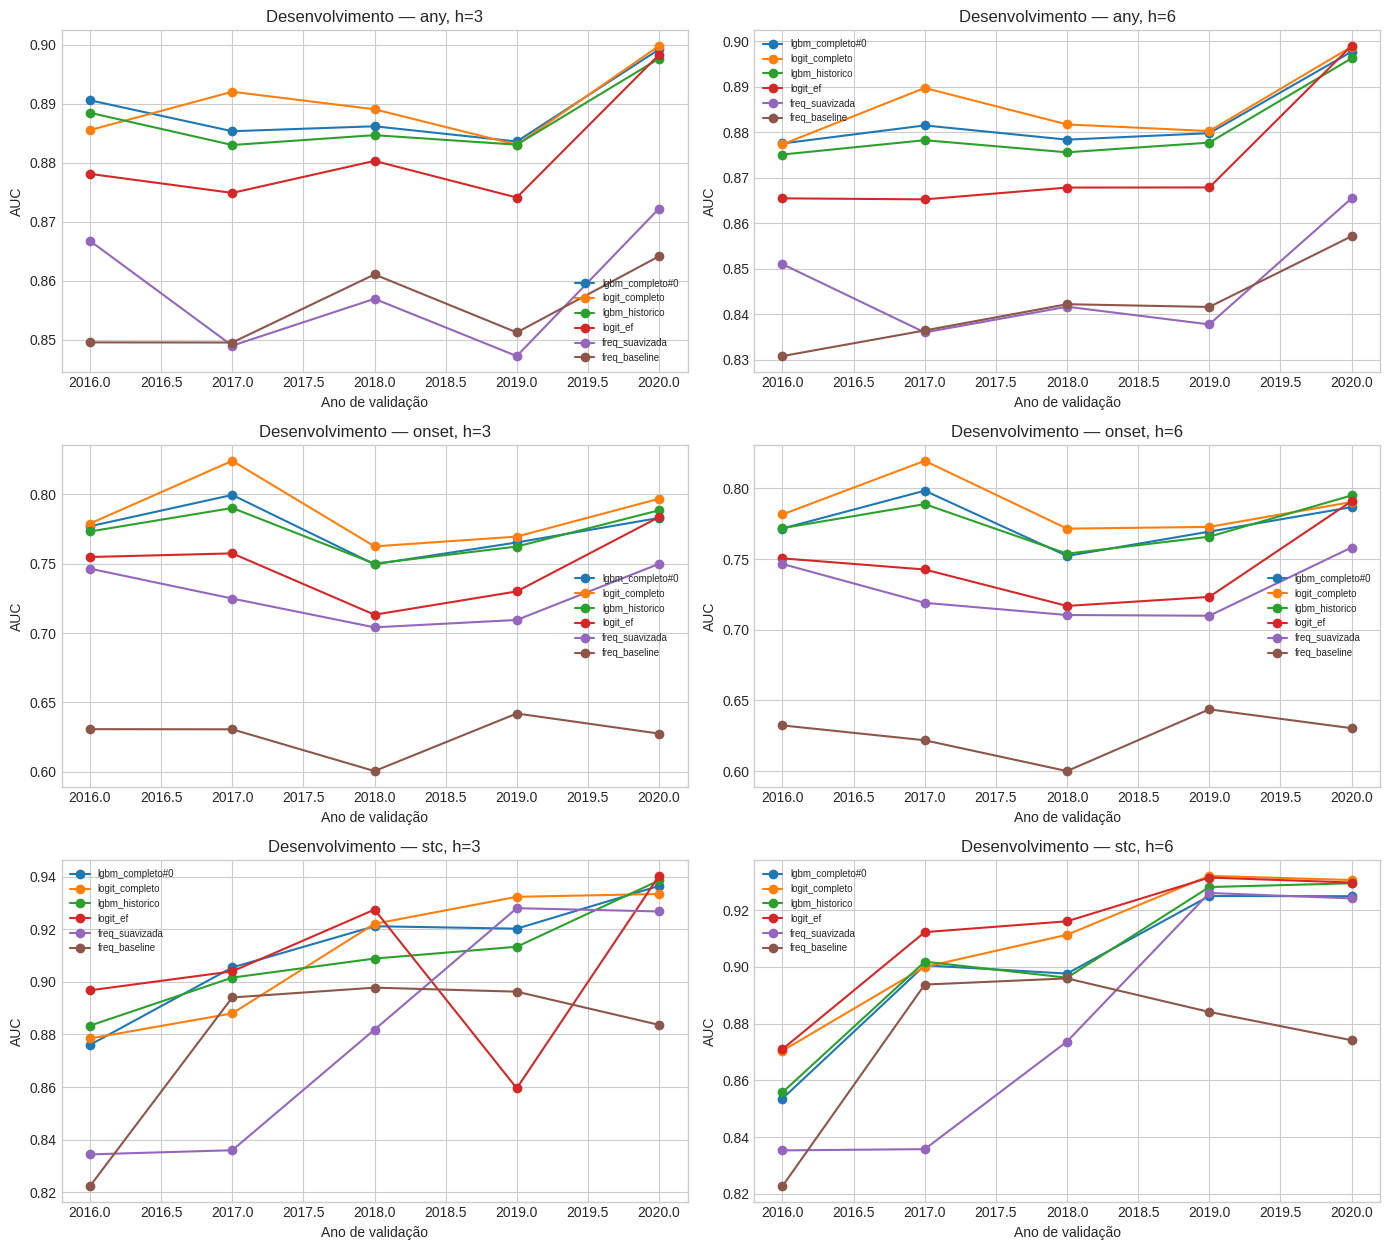

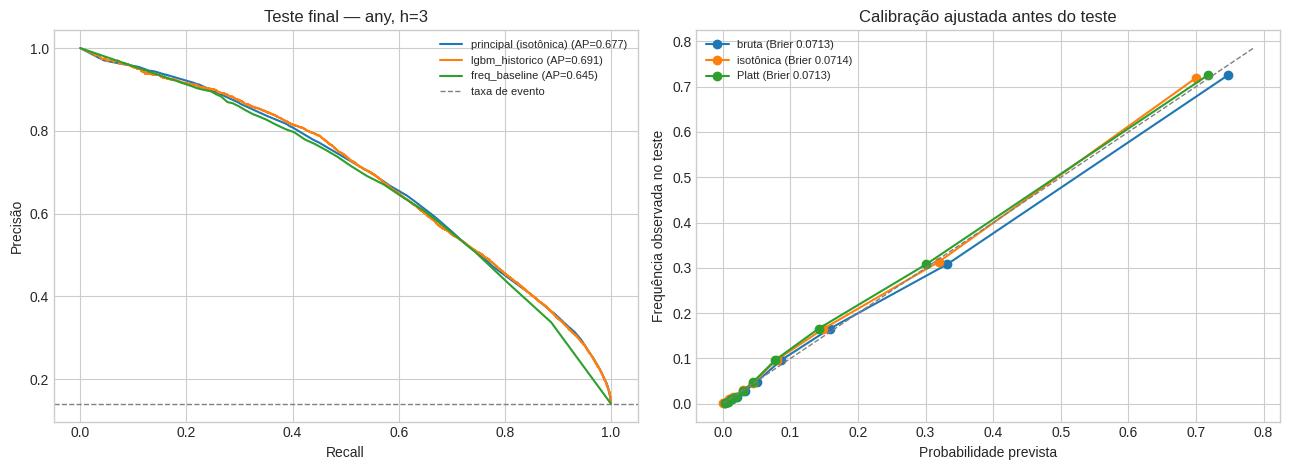

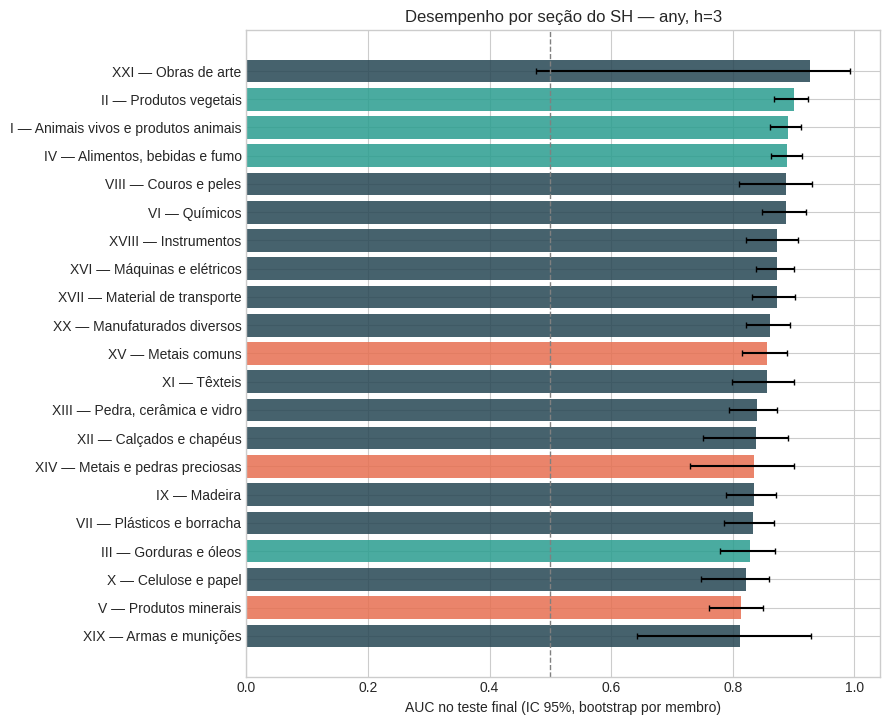

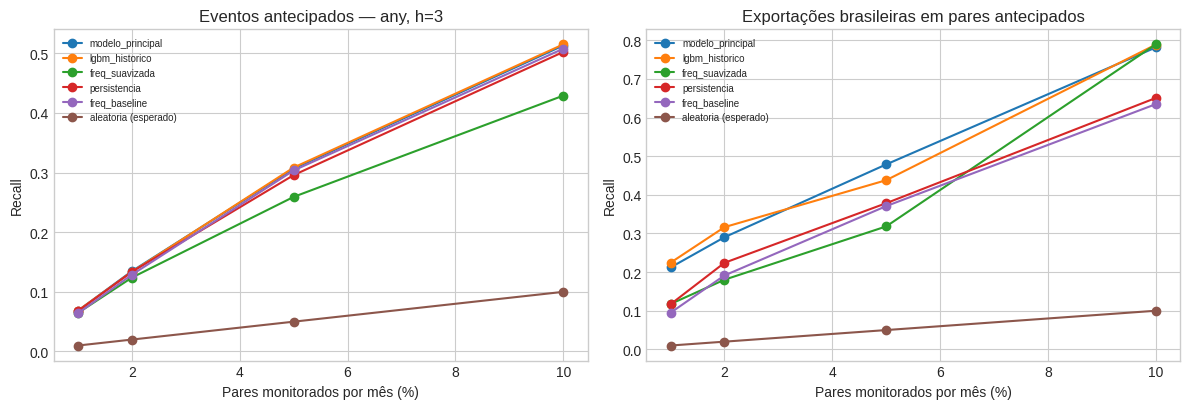

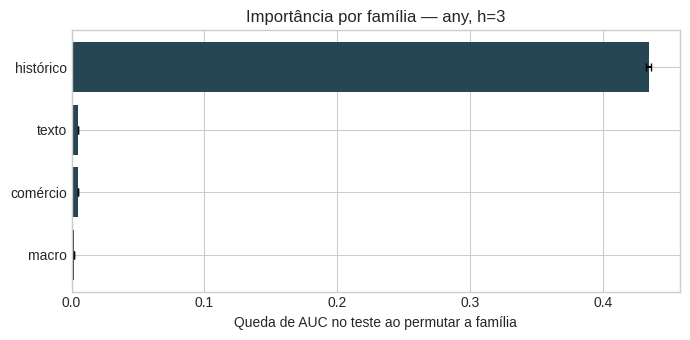

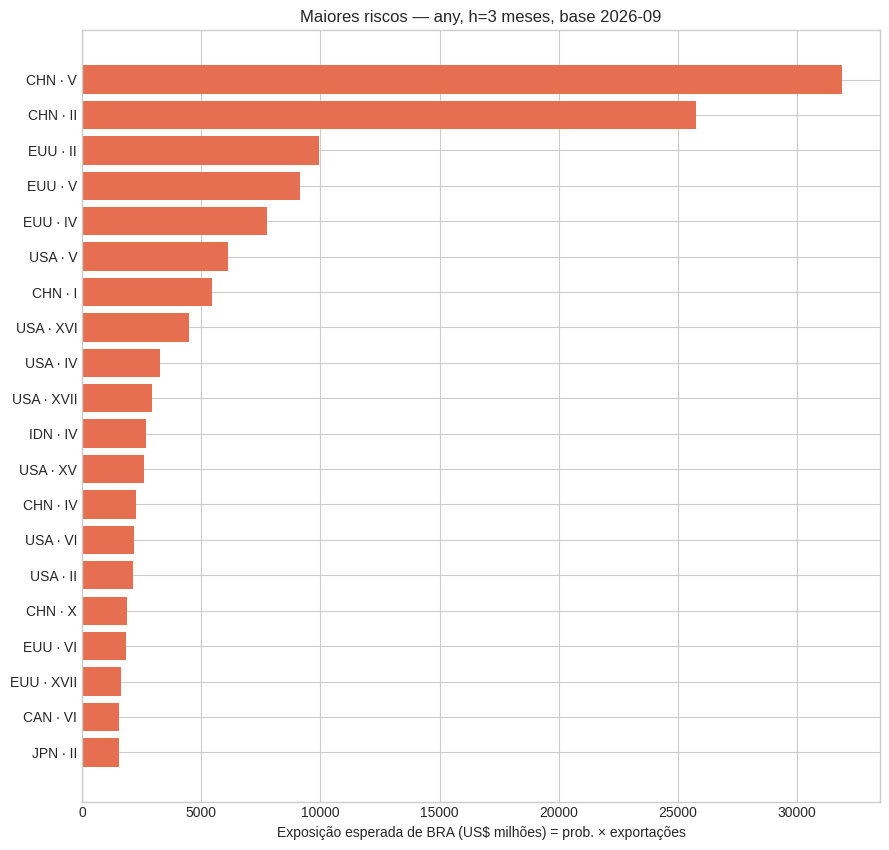

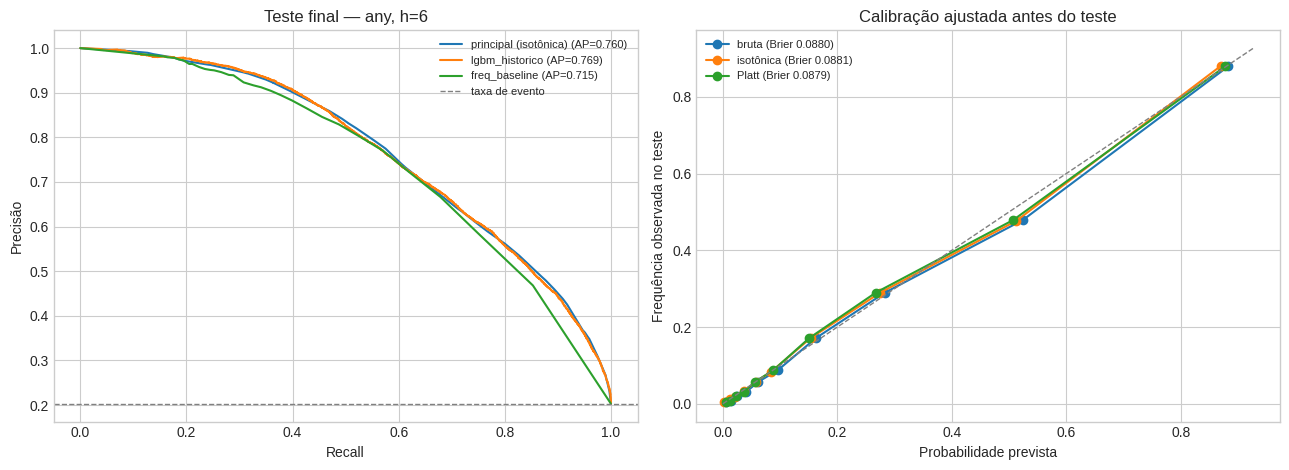

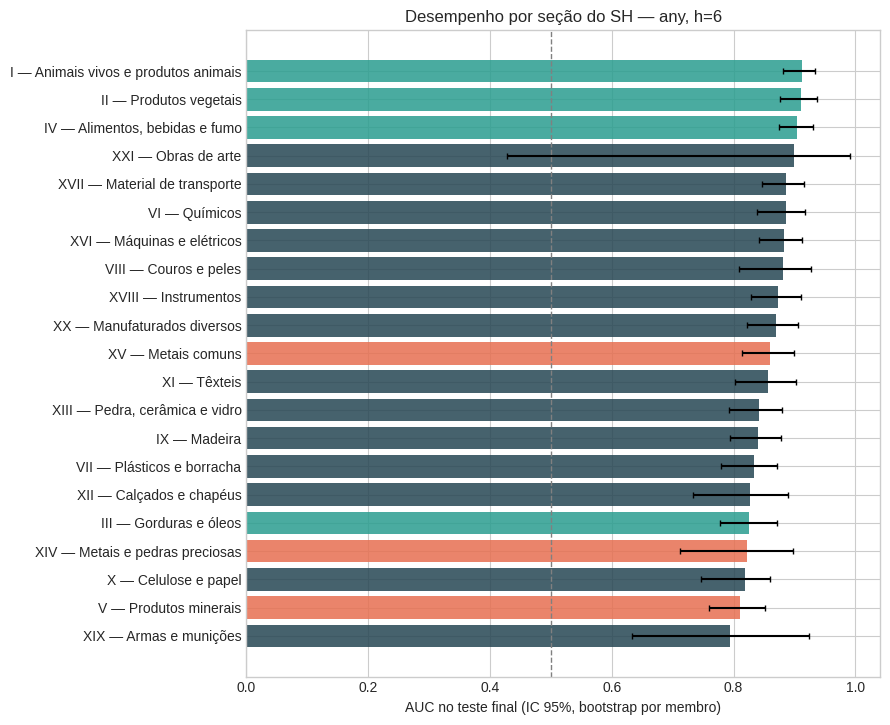

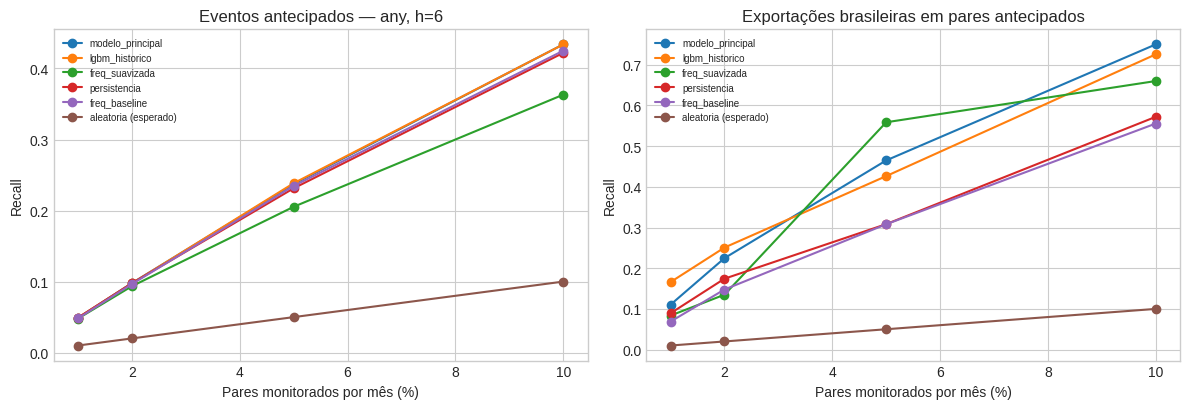

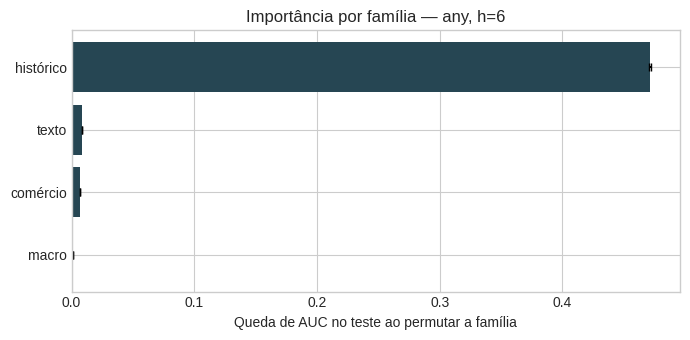

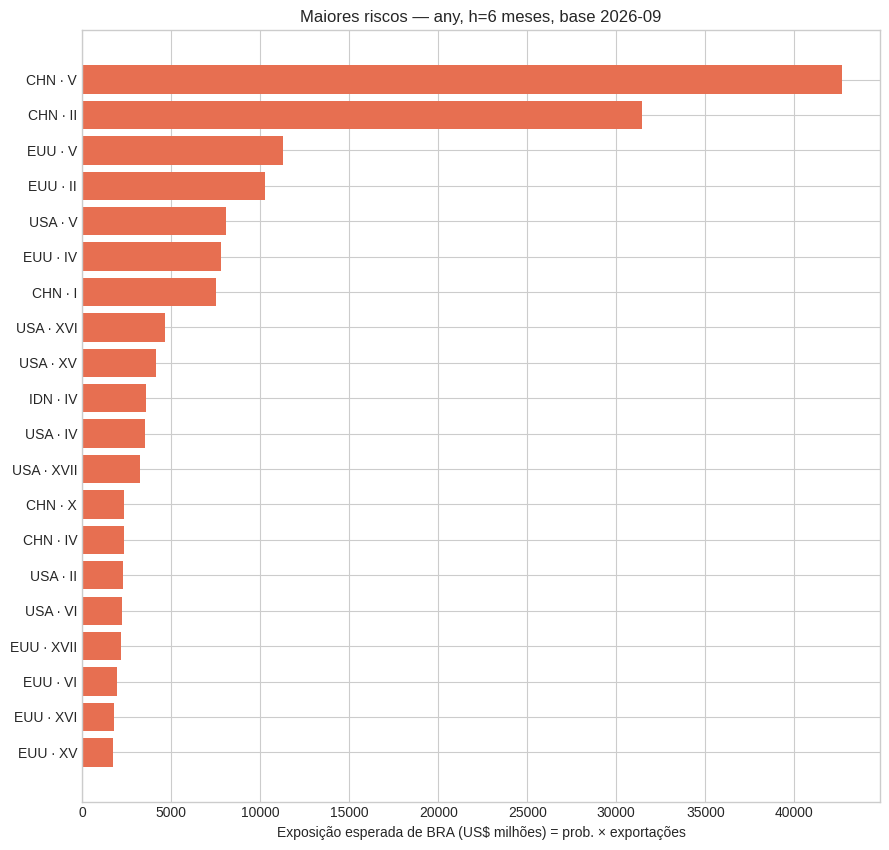

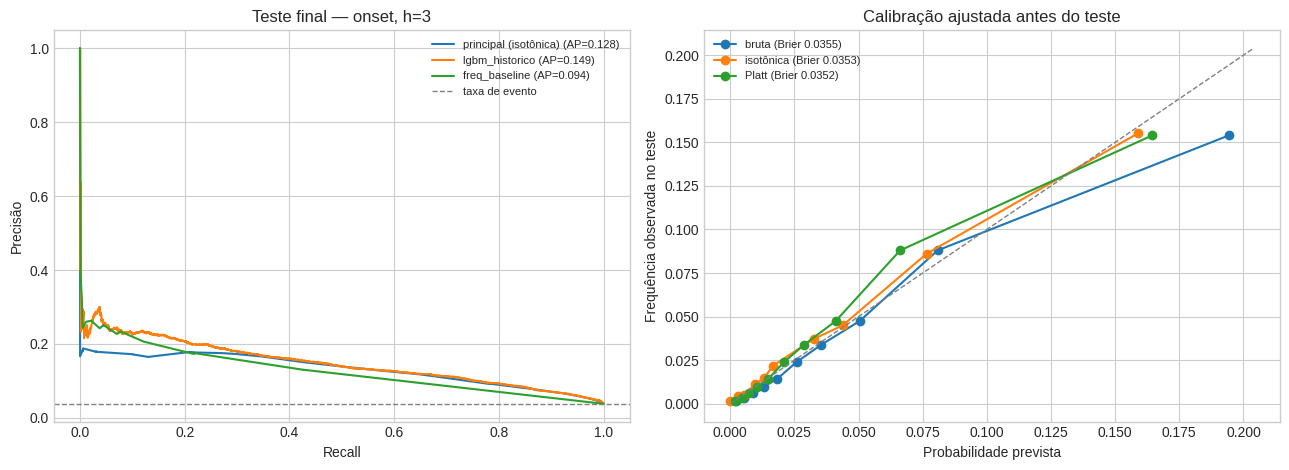

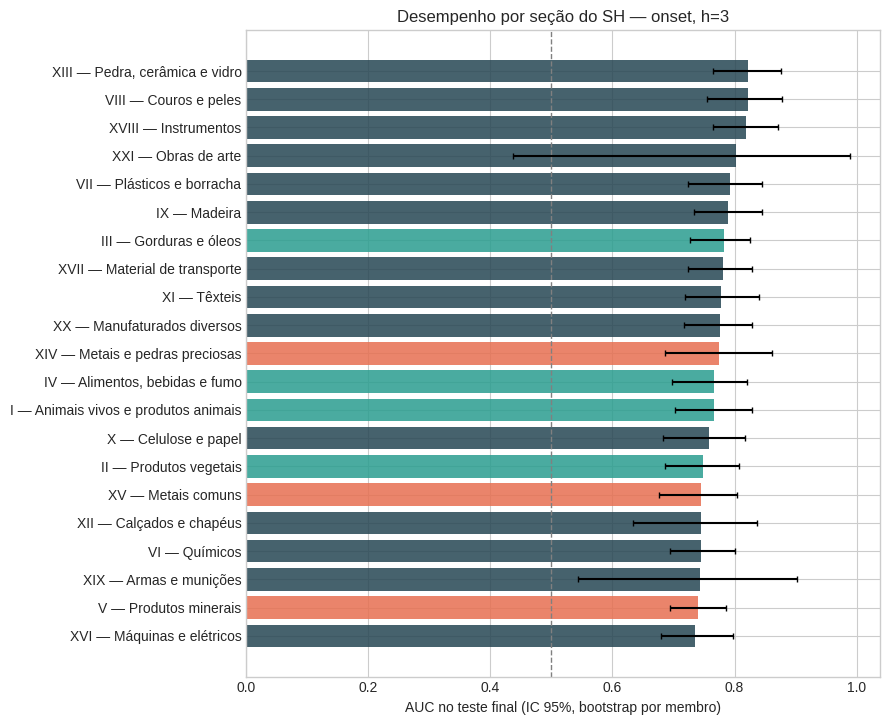

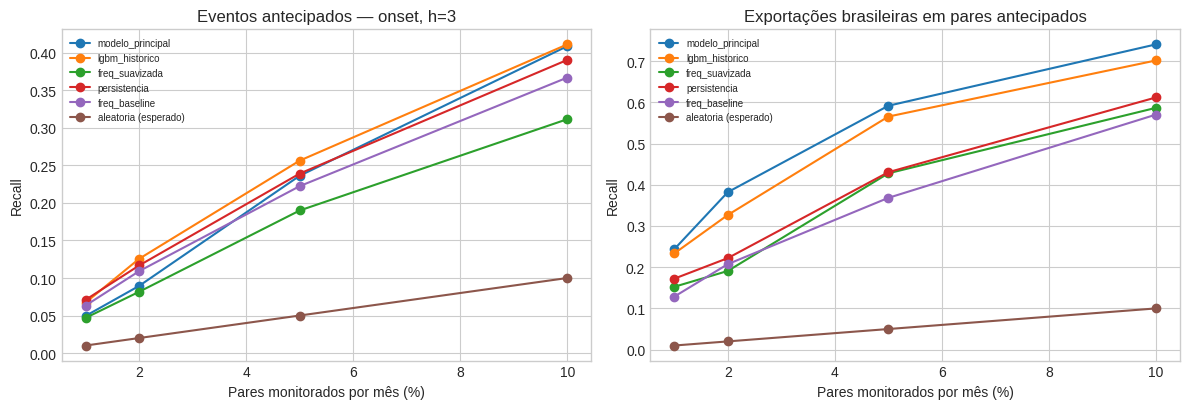

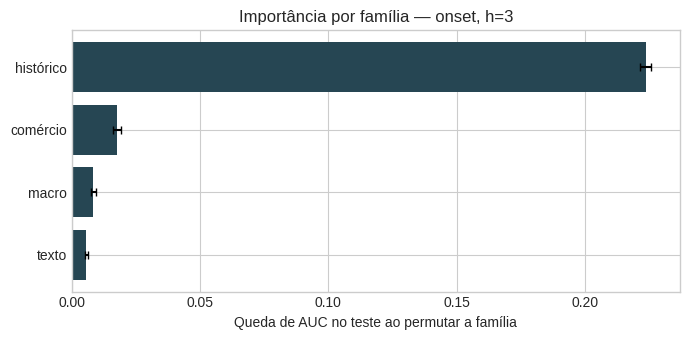

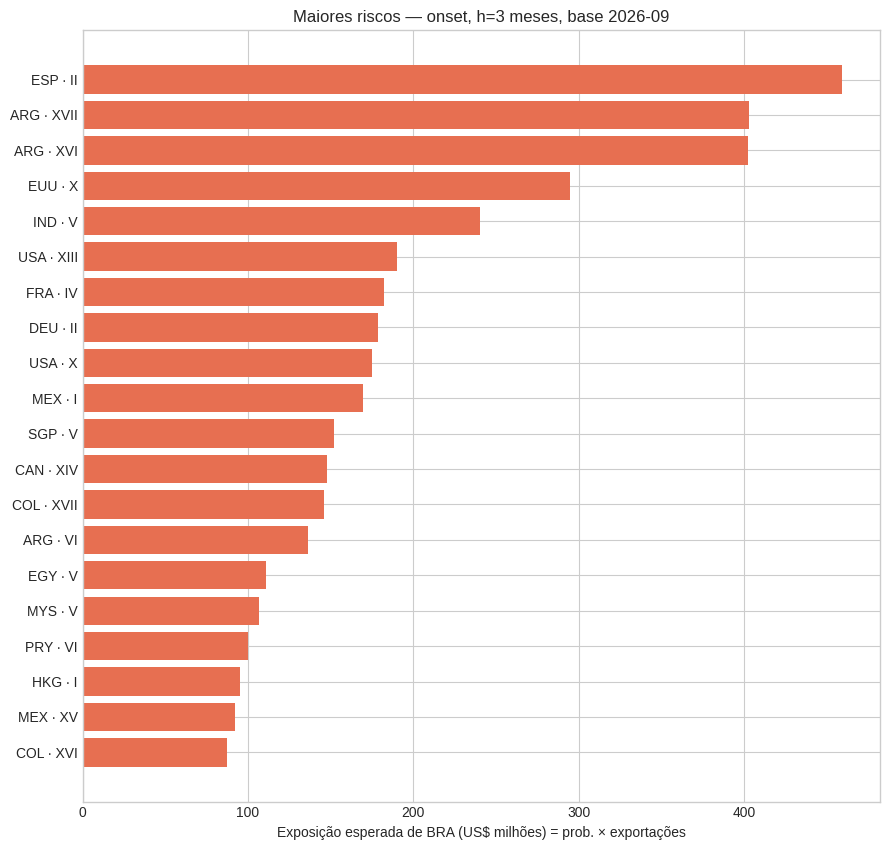

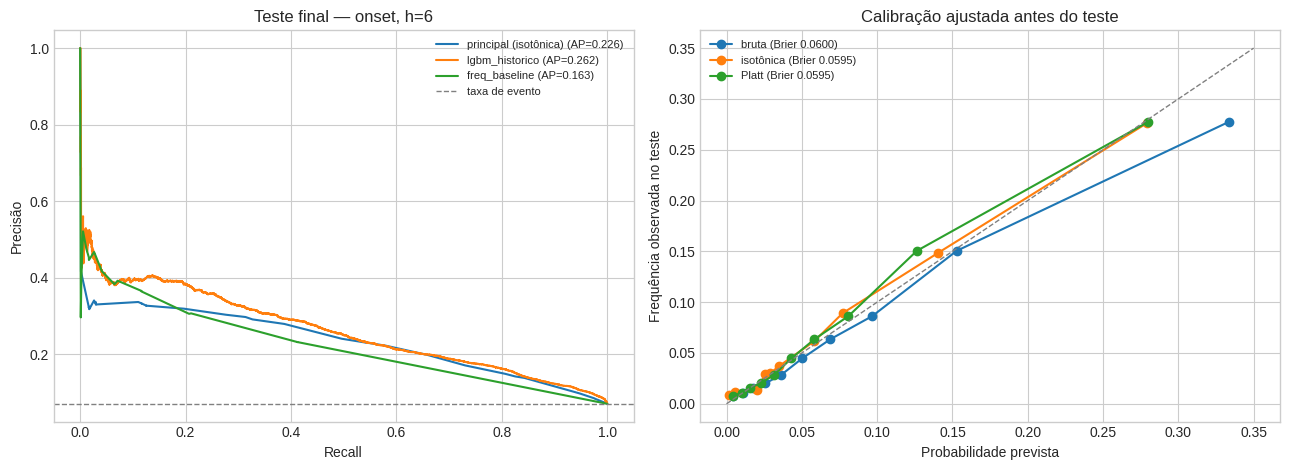

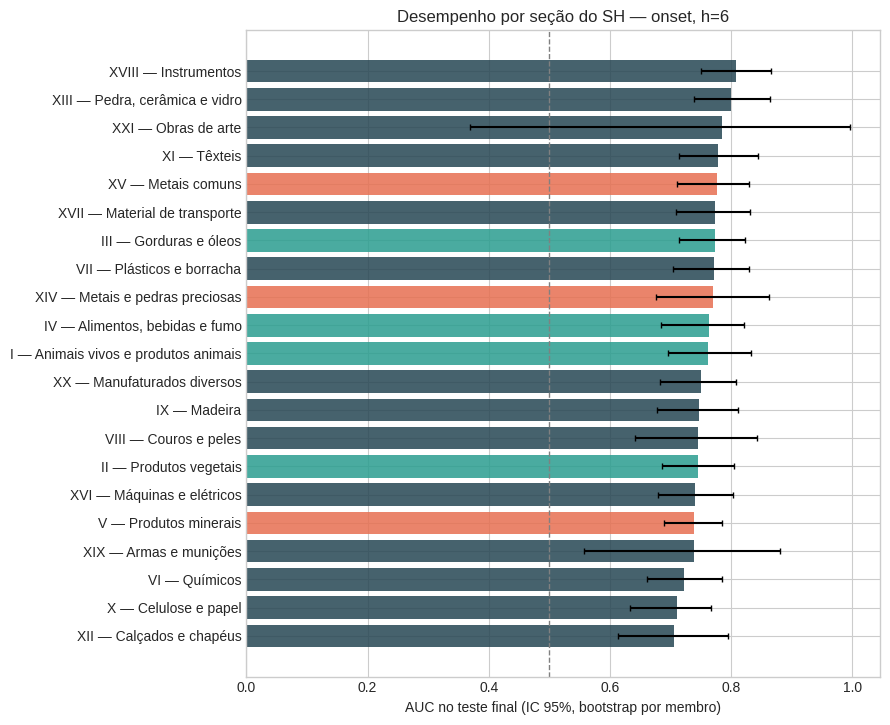

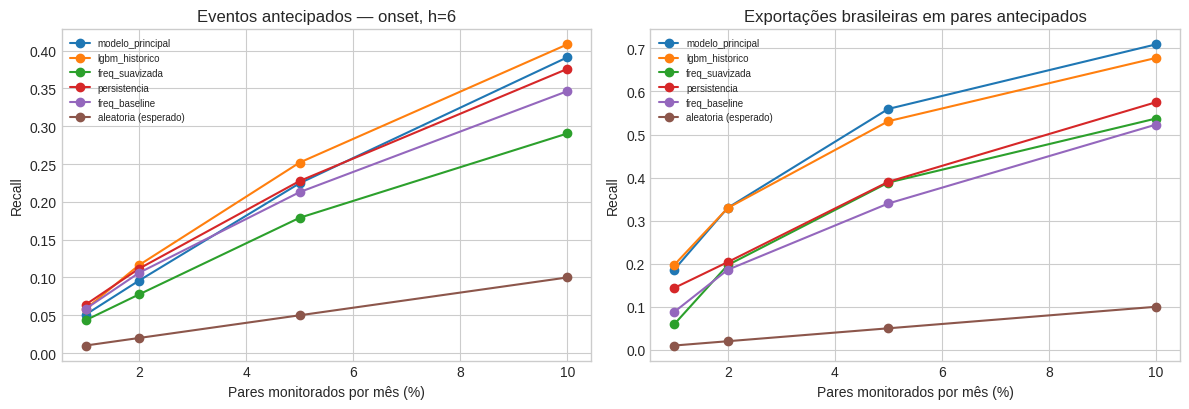

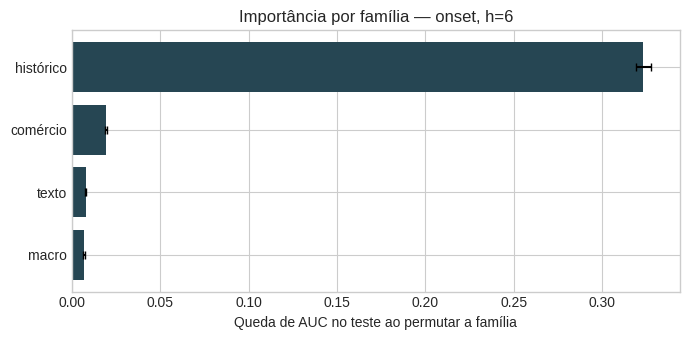

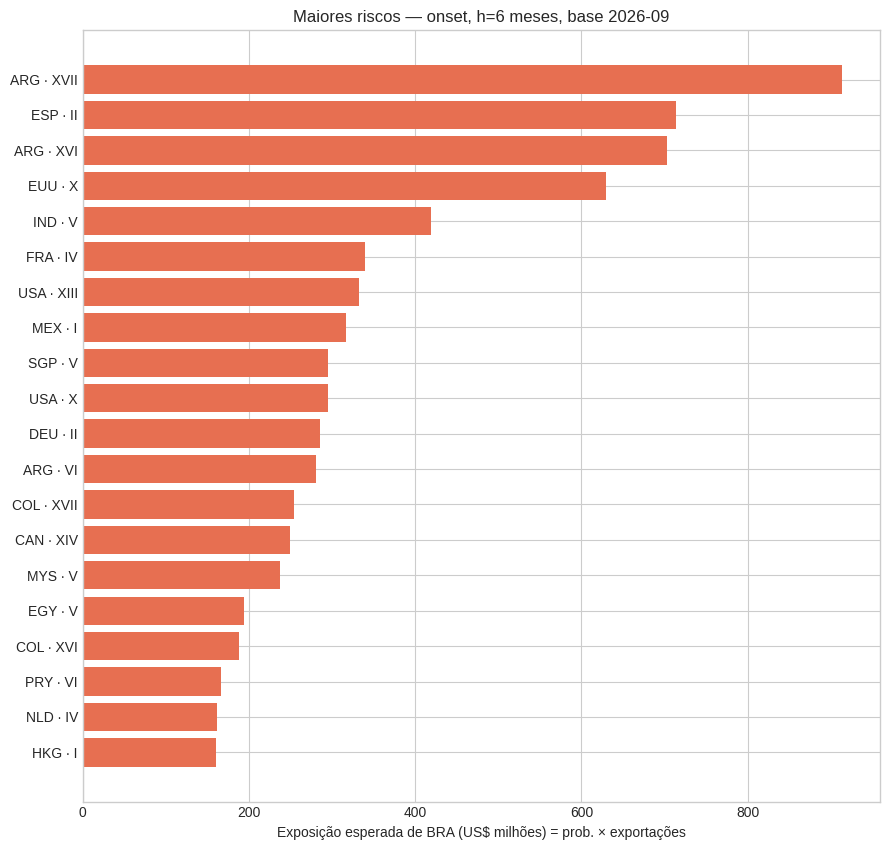

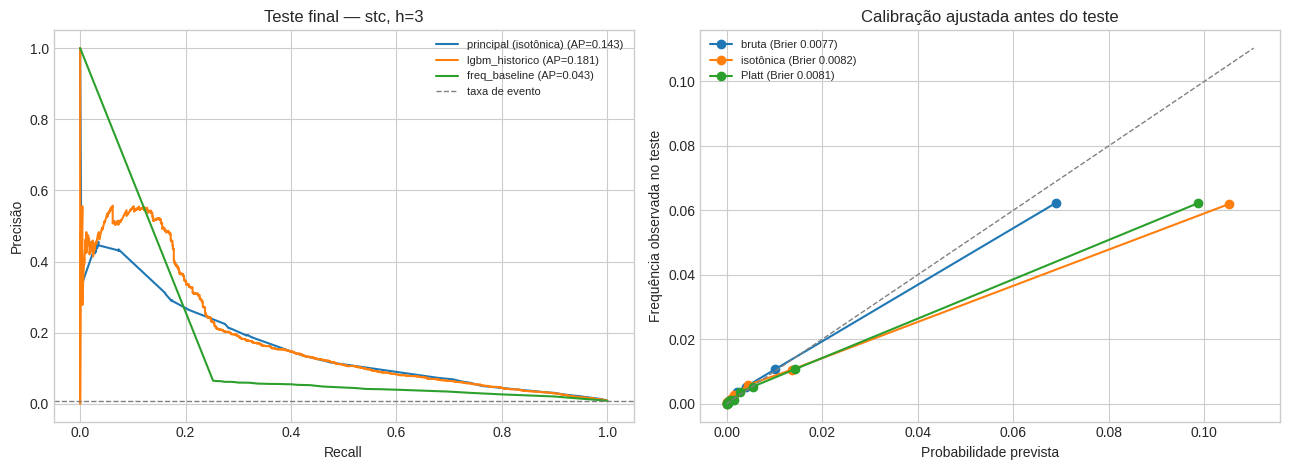

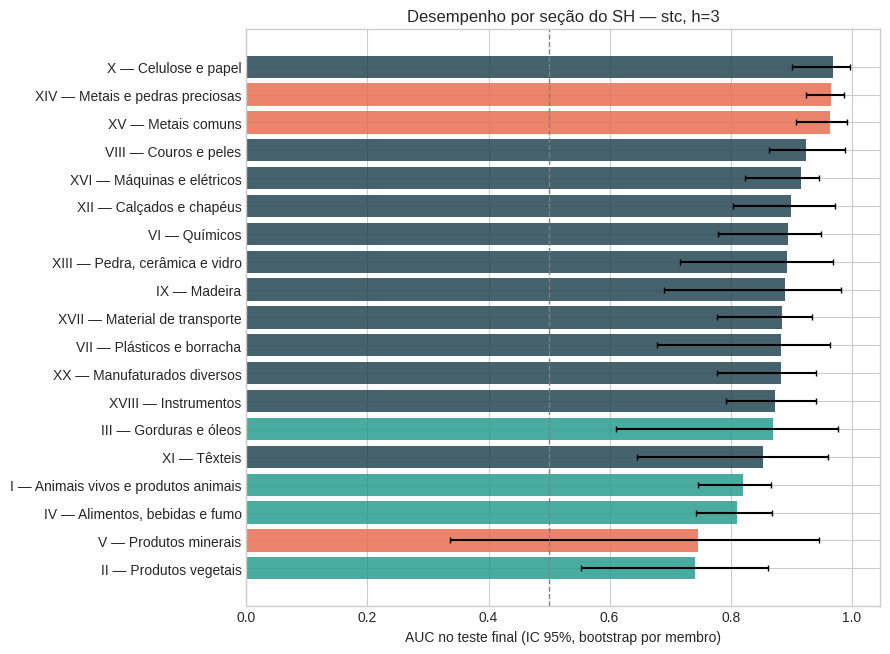

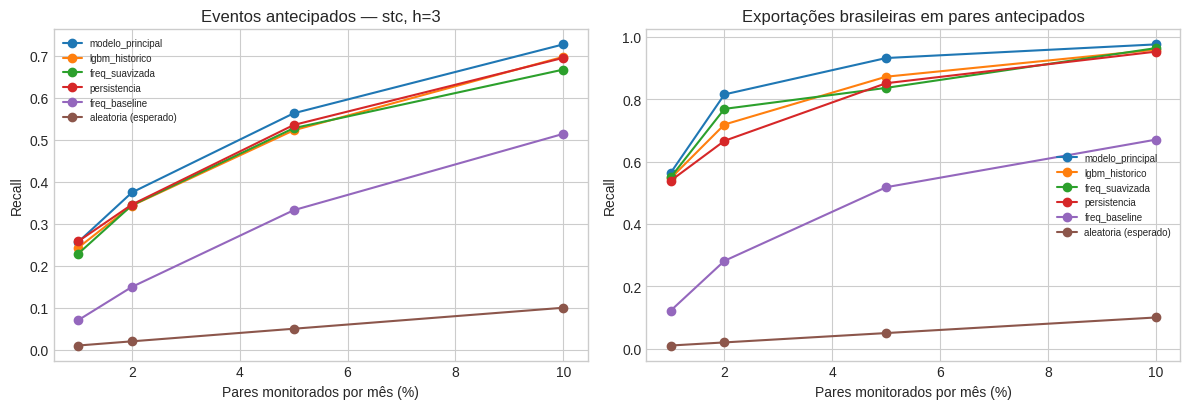

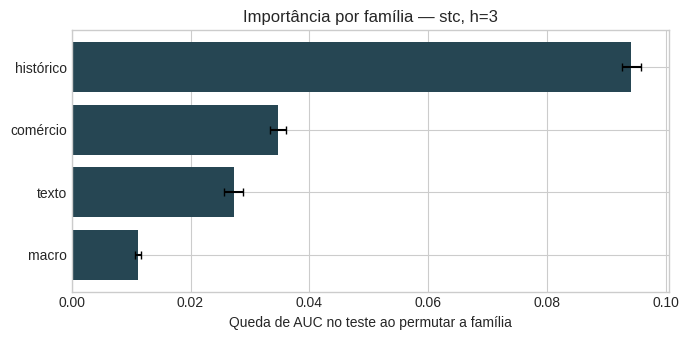

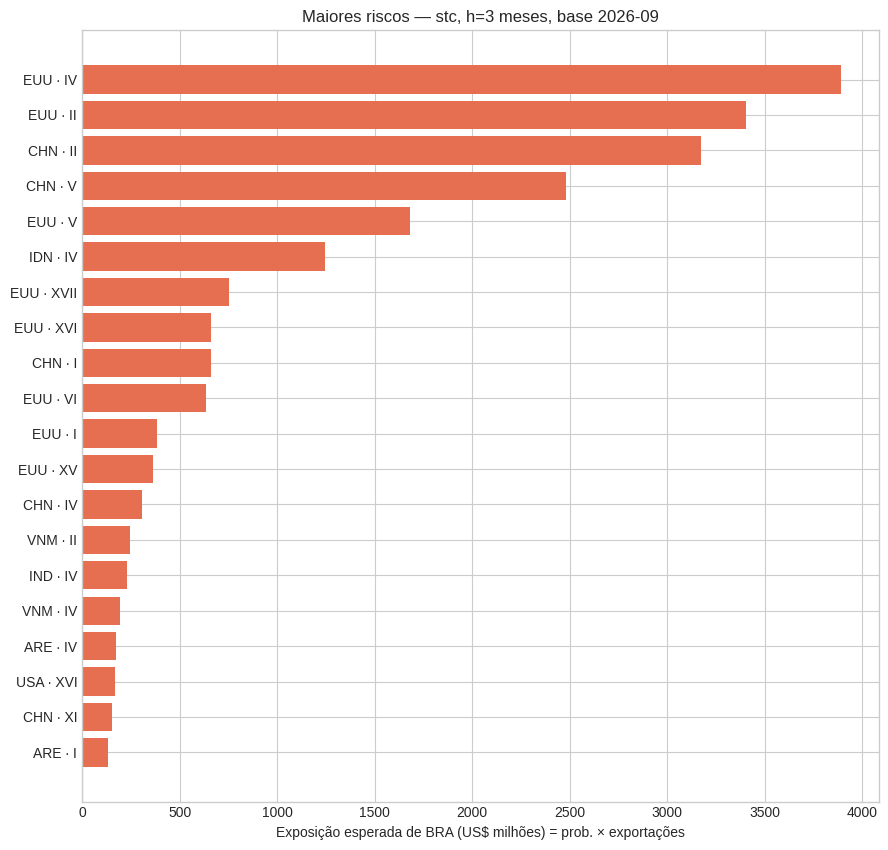

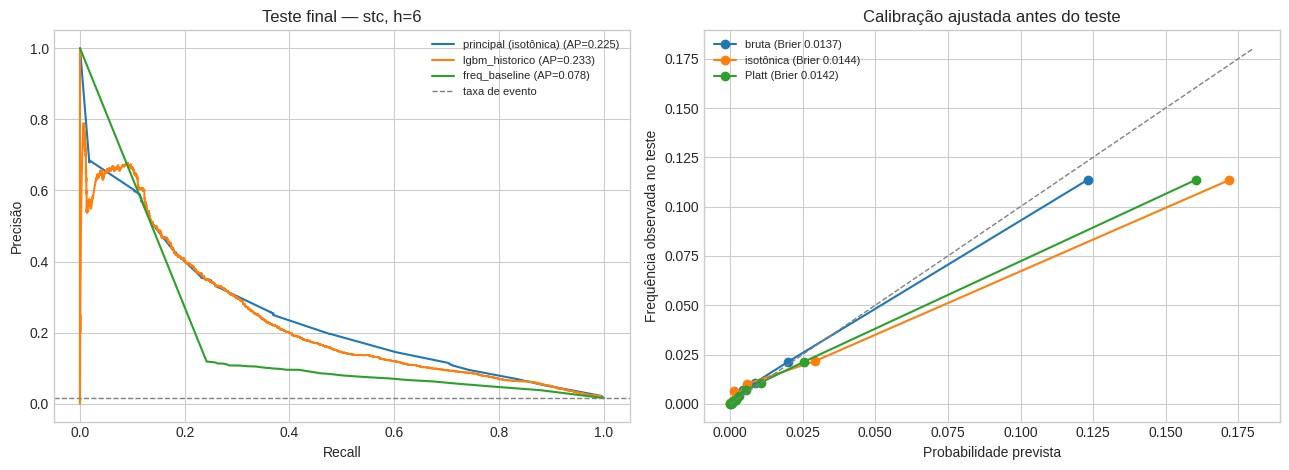

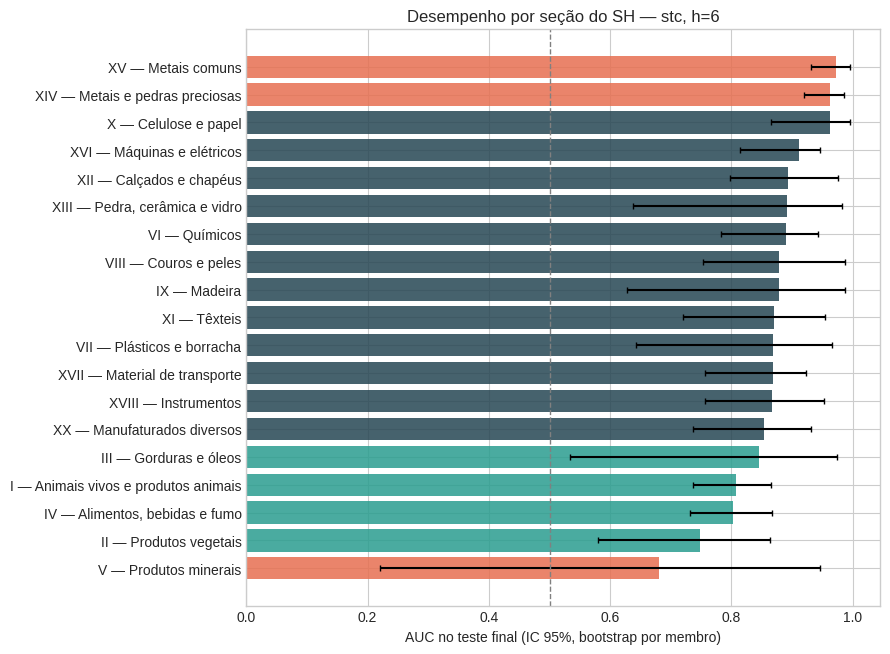

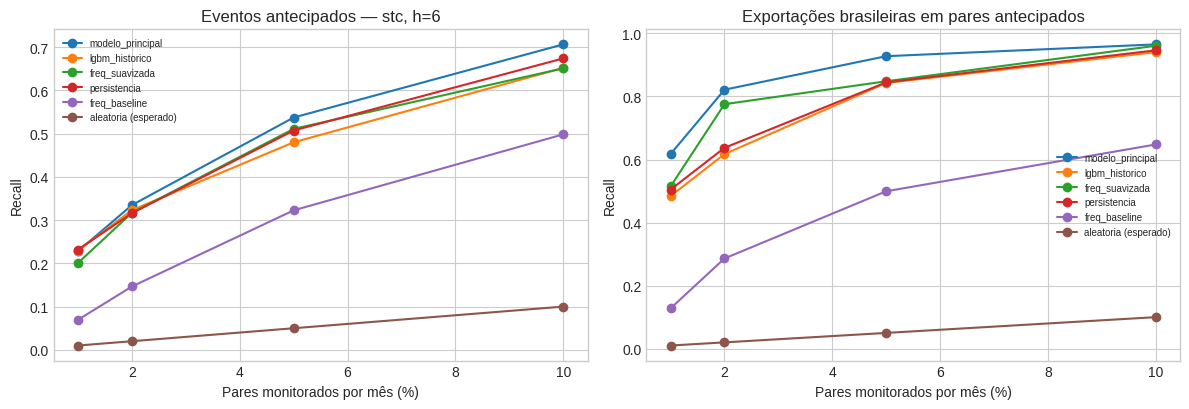

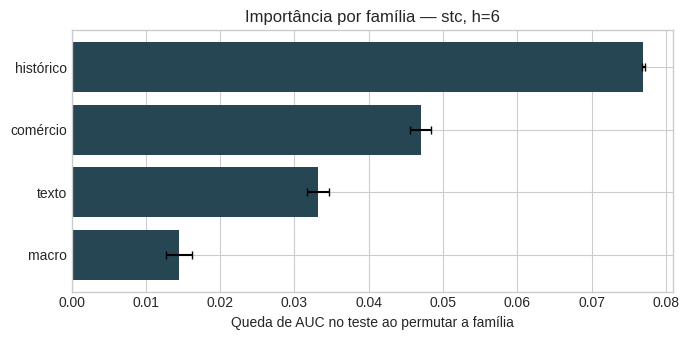

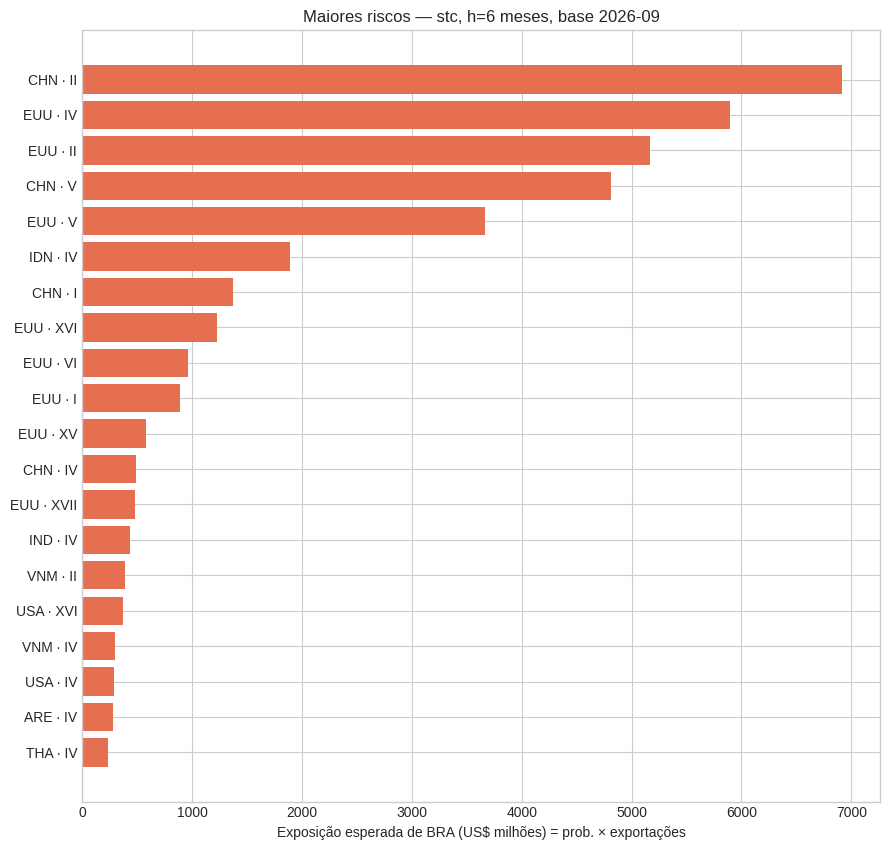

[OK]   Concluído em 109.7 min. Saídas em /kaggle/working/bnt_v2


In [15]:
if __name__ == '__main__':
    results = main()

### Plano B: STCs pelo navegador
Se a API de STCs bloquear o Kaggle, cole o código no console de https://tradeconcerns.wto.org/en/stcs,
aguarde ~5 min e suba o `stc_wto.json` baixado como dataset.
#
```javascript
(async () => {
  const base = '/api/specificTradeConcerns/v1/stcs';
  const list = await (await fetch(`${base}/search?language=English&page=1&pageSize=10000`)).json();
  const items = list.items.filter(i => ['SPS', 'TBT'].includes(i.domainId));
  const out = [];
  for (let k = 0; k < items.length; k += 4) {
    const chunk = items.slice(k, k + 4);
    const dets = await Promise.all(chunk.map(i =>
      fetch(`${base}/getDetails?imsId=${i.imsId}&domainId=${i.domainId}&language=English`)
        .then(r => r.ok ? r.json() : null).catch(() => null)));
    chunk.forEach((i, j) => {
      const d = dets[j], subj = [];
      for (const m of (d?.meetings || [])) {
        for (const s of (m.subject || [])) subj.push({id: s.countryId, name: s.countryName});
        if (subj.length) break;
      }
      out.push({id: i.imsId, domain: i.domainId, title: i.title, first_raised: i.firstTimeRaised,
        times_raised: i.numberOfTimesRaised, subject_name: i.subjectName, subjects: subj,
        raising: i.raisingName, supporting: i.supportingName, status: i.status,
        symbols: [...new Set([...(i.symbols || []), ...(d?.symbols || [])])].sort(),
        hs: (d?.hsProducts || []).map(h => h.code).filter(Boolean),
        keywords: (d?.keywords || []).map(x => x.name).filter(Boolean)});
    });
    console.log(`${out.length}/${items.length}`);
  }
  const a = document.createElement('a');
  a.href = URL.createObjectURL(new Blob([JSON.stringify(out)], {type: 'application/json'}));
  a.download = 'stc_wto.json';
  a.click();
})();
```